In [103]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import colormaps
cmap = colormaps['viridis']

final = r"C:\Users\Utilisateur\Desktop\IRONHACK_DA\COURSES\week-4\first_project\data\clean\final_dataset.csv"
df = pd.read_csv(final)
df = df.drop('code', axis=1)
df.drop_duplicates(inplace=True)

In [104]:
df

,year,country,christianity,judaism,islam,buddhism,hindu,shinto,confus_tao,gdp,un_region,conflict_present,hdi,population
0,1990,United States,214425162,5508504,2294757,1575481,323352,59724,106818,5.963144e+12,Northern America,0.0,0.88,249623000.0
1,1995,United States,215593975,5259463,2425377,1608346,574269,57972,62455,7.639749e+12,Northern America,0.0,0.89,266278000.0
2,2000,United States,219818305,5010424,2555997,2449569,825186,56220,18093,1.025095e+13,Northern America,0.0,0.89,282162411.0
3,2005,United States,226464805,5536622,2685374,3682694,1311442,60560,90593,1.303920e+13,Northern America,0.0,0.91,295516599.0
4,2010,United States,233111307,5942248,2814750,3410236,1797698,156375,95752,1.504896e+13,Northern America,0.0,0.92,309378227.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
774,1990,Samoa,159500,0,37,15,0,0,0,1.257663e+08,Oceania,0.0,0.66,169042.0
775,1995,Samoa,161677,0,43,16,0,0,0,2.248657e+08,Oceania,0.0,0.66,174571.0
776,2000,Samoa,174600,0,50,18,0,0,0,2.588561e+08,Oceania,0.0,0.67,181685.0
777,2005,Samoa,177510,0,58,18,0,0,0,4.768018e+08,Oceania,0.0,0.69,186978.0


In [105]:
# real long format for initial tot graph
long_df = df.melt(id_vars=['year','country','gdp','un_region','hdi','conflict_present','population'], var_name ='religion', value_name = 'relig_pop')

In [106]:
df1 = long_df.copy()

In [107]:
# Replace the countries names accordingly
df1["un_region"] = df["un_region"].replace("Latin America and the Caribbean", "Southern America")

In [108]:
df1.un_region.unique()

<StringArray>
['Northern America', 'Southern America',           'Europe',
             'Asia',           'Africa',          'Oceania',
                nan]
Length: 7, dtype: str

C:\Users\Utilisateur\AppData\Local\Temp\ipykernel_11336\1982751351.py:12: UserWarning: Numpy array is not a supported type for `palette`. Please convert your palette to a list. This will become an error in v0.14
  sns.lineplot(


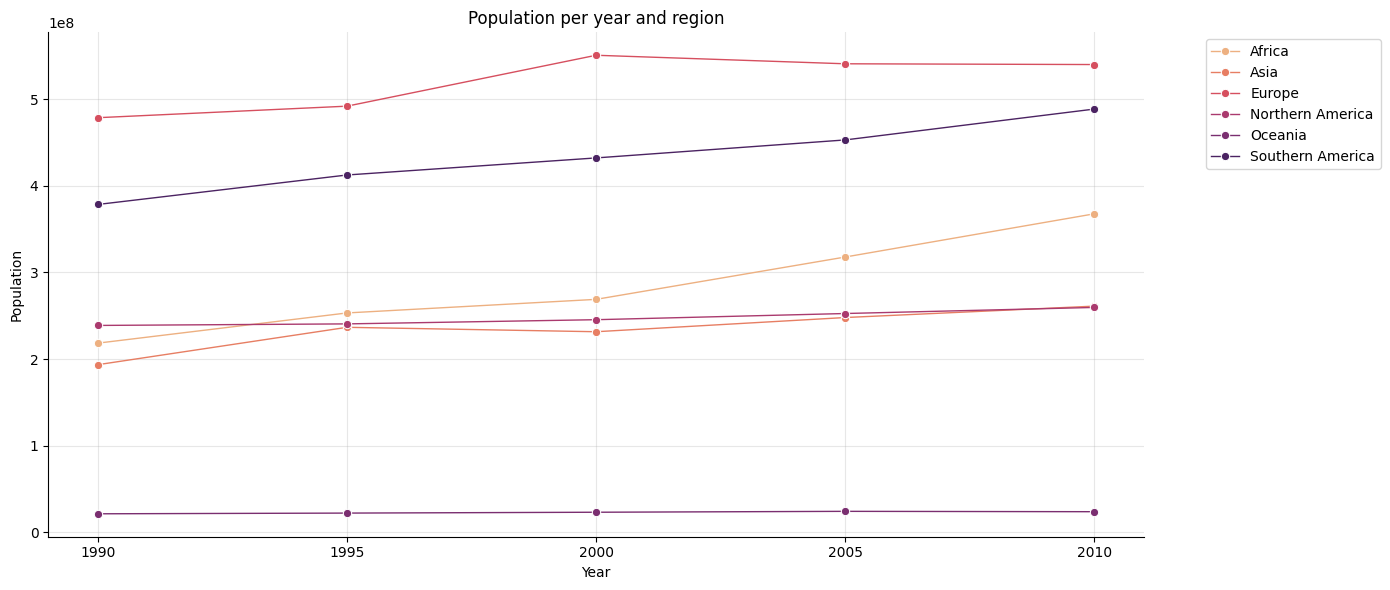

In [109]:
# Total religious population per year and per region

pop_region_year = (df1.groupby(["year", "un_region"], as_index=False)["relig_pop"].sum())

# regions unique
n = pop_region_year["un_region"].nunique()

# color for each region (from continuous to non continuous data)
colors = colormaps['flare'](np.linspace(0, 1, n))

plt.figure(figsize=(14,6))
sns.lineplot(
    data=pop_region_year,
    x="year",
    y="relig_pop",
    hue="un_region",
    marker="o",
    linewidth=1,
    markersize=6,
    palette=colors
)

# plot customize
plt.title("Population per year and region")
plt.xlabel("Year")
plt.ylabel("Population")
plt.grid(alpha=0.3)
plt.xticks(sorted(pop_region_year["year"].unique()))
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize = 10)
plt.tight_layout()
sns.despine()
plt.savefig("FigA.1.PopRegYear_linechart.png", dpi=300)

## Interpretation
In this first graph, we can see that the number of believers is stable in Oceania, South America, and Europe, and significantly lower than in Asia, where the religious population in 1990 was already four times larger and continues to grow steadily. Africa also shows a clear increase, although its total number of believers is lower, placing it second, and it is even starting to surpass Europe, which exhibits only minor fluctuations at the macro level. In summary, Asia shows the largest increase, Africa a moderate increase, while other regions remain relatively stable at this aggregated scale. This information should be interpreted with caution, as it is not adjusted for the total population of each region.

In [110]:
# Pop Share graph 
long_df2 = df.melt(id_vars=['year','country','gdp','un_region','hdi','conflict_present','population'], var_name ='religion', value_name = 'relig_pop')

In [111]:
pop_percent = (
    long_df2
    .groupby(["year", "country",'un_region','conflict_present'], as_index=False)
    .agg(population=("population", "mean"),relig_pop=("relig_pop", "sum")))

pop_percent["relig_pop"] = pop_percent[["relig_pop","population"]].min(axis=1)

pop_percent["percent_pop"] = pop_percent["relig_pop"] / pop_percent["population"]
pop_percent



,year,country,un_region,conflict_present,population,relig_pop,percent_pop
0,1990,Afghanistan,Asia,1.0,12045660.0,12045660.0,1.000000
1,1990,Albania,Europe,0.0,3286542.0,2344223.0,0.713279
2,1990,Algeria,Africa,0.0,25375810.0,24275000.0,0.956620
3,1990,Angola,Africa,1.0,11626360.0,9400071.0,0.808514
4,1990,Argentina,Latin America and the Caribbean,0.0,32755901.0,30091626.0,0.918663
...,...,...,...,...,...,...,...
774,2010,Uzbekistan,Asia,0.0,28385506.0,27601556.0,0.972382
775,2010,Vanuatu,Oceania,0.0,238248.0,205666.0,0.863243
776,2010,Viet Nam,Asia,0.0,87455152.0,51228005.0,0.585763
777,2010,Zambia,Africa,0.0,13965594.0,11486415.0,0.822480


In [112]:

pop_percent_region

,year,un_region,percent_pop
0,1990,Africa,0.790042
1,1990,Asia,0.869868
2,1990,Europe,0.897756
3,1990,Latin America and the Caribbean,0.887362
4,1990,Northern America,0.916581
5,1990,Oceania,0.897819
6,1995,Africa,0.817542
7,1995,Asia,0.878995
8,1995,Europe,0.850767
9,1995,Latin America and the Caribbean,0.885251


In [78]:
pop_percent_region
pop_percent["percent_pop"] = pop_percent["relig_pop"] / pop_percent["population"]
pop_percent

,year,country,un_region,conflict_present,population,relig_pop,percent_pop
0,1990,Afghanistan,Asia,1.0,12045660.0,12045660.0,1.000000
1,1990,Albania,Europe,0.0,3286542.0,2344223.0,0.713279
2,1990,Algeria,Africa,0.0,25375810.0,24275000.0,0.956620
3,1990,Angola,Africa,1.0,11626360.0,9400071.0,0.808514
4,1990,Argentina,Latin America and the Caribbean,0.0,32755901.0,30091626.0,0.918663
...,...,...,...,...,...,...,...
774,2010,Uzbekistan,Asia,0.0,28385506.0,27601556.0,0.972382
775,2010,Vanuatu,Oceania,0.0,238248.0,205666.0,0.863243
776,2010,Viet Nam,Asia,0.0,87455152.0,51228005.0,0.585763
777,2010,Zambia,Africa,0.0,13965594.0,11486415.0,0.822480


C:\Users\Utilisateur\AppData\Local\Temp\ipykernel_11336\474703213.py:11: UserWarning: Numpy array is not a supported type for `palette`. Please convert your palette to a list. This will become an error in v0.14
  sns.lineplot(


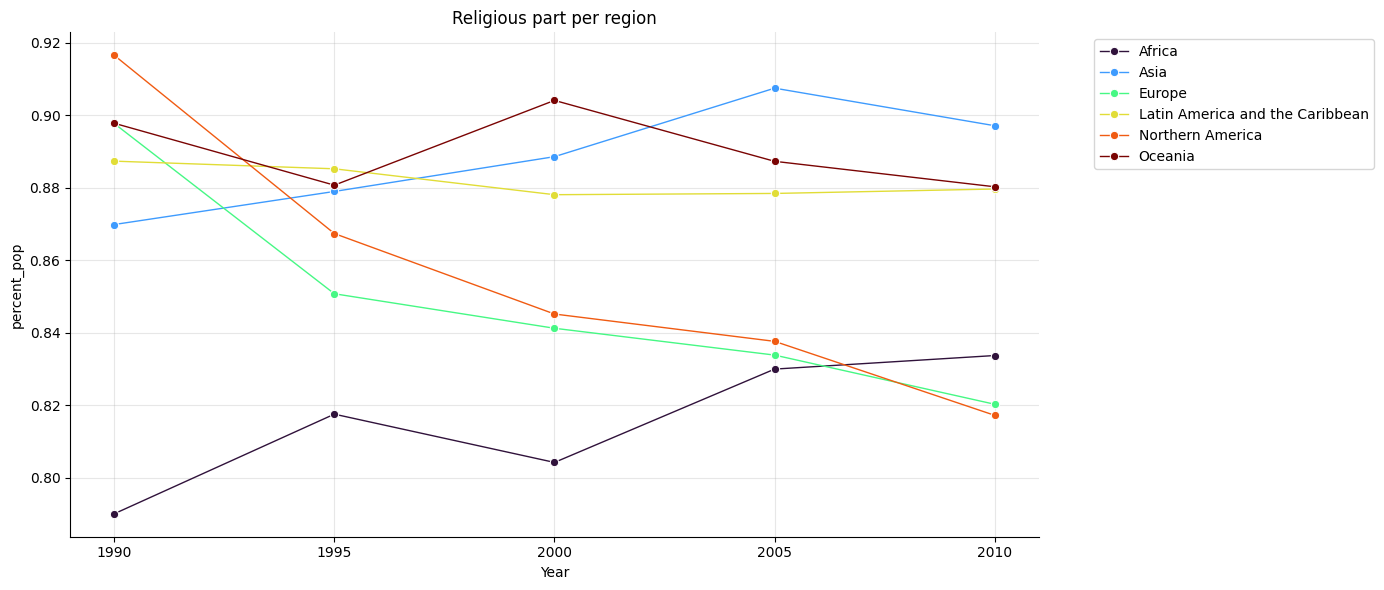

In [113]:
# % religious population per year and per region
pop_percent_region = pop_percent.groupby(["year", 'un_region'], as_index=False)["percent_pop"].mean()

# regions unique
n = pop_percent_region["un_region"].nunique()

# color for each region (from continuous to non continuous data)
colors = colormaps['turbo'](np.linspace(0, 1, n))

plt.figure(figsize=(14,6))
sns.lineplot(
    data=pop_percent_region,
    x="year",
    y="percent_pop",
    hue="un_region",
    marker="o",
    linewidth=1,
    markersize=6,
    palette=colors
)

# plot customize
plt.title("Religious part per region")
plt.xlabel("Year")
#plt.ylabel("Population")
plt.grid(alpha=0.3)
plt.xticks(sorted(pop_percent_region["year"].unique()))
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize = 10)
plt.tight_layout()
sns.despine()
plt.savefig("FigA.1.1.PopPartRegYear_linechart.png", dpi=300)

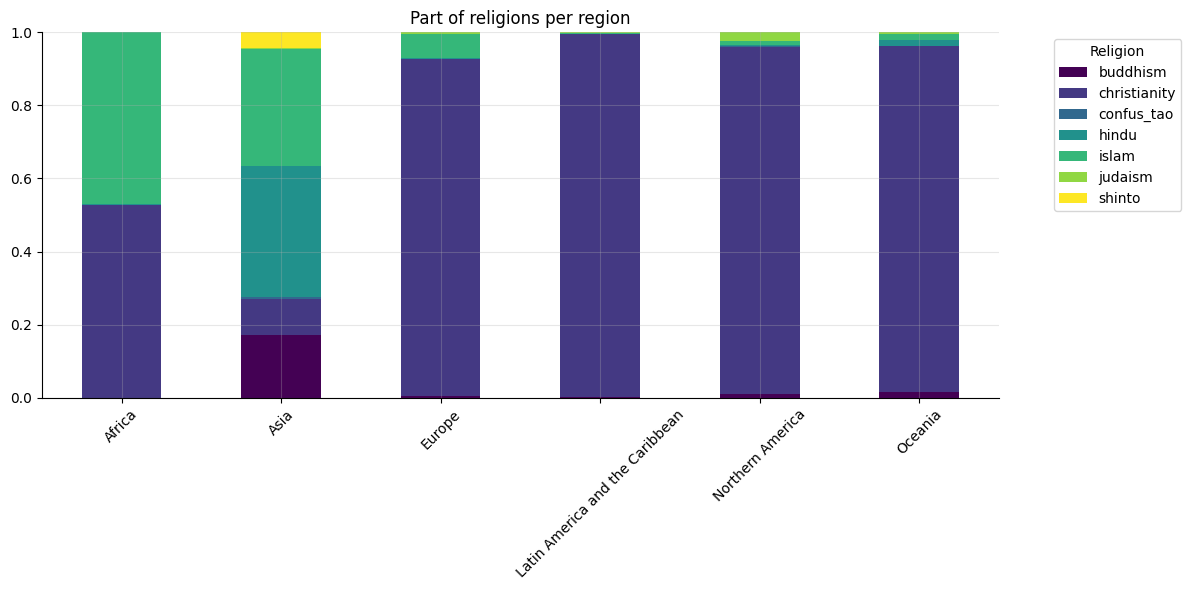

In [114]:
# Distribution of religions among regions 
from matplotlib import colormaps
cmap = colormaps['viridis']

# mean per region
mean_relig = (long_df.groupby(["un_region", "religion"], as_index=False)["relig_pop"].mean())

# pivot table per region per religion (unstack)
pivot_relig = mean_relig.pivot(
    index="un_region",
    columns="religion",
    values="relig_pop"
).fillna(0)

# percentage of each religion by region  (.div => division, sum(axis=1) means total of the row, 
pivot_pct = pivot_relig.div(pivot_relig.sum(axis=1), axis=0)

cmap = colormaps['viridis']
colors = cmap(np.linspace(0, 1, pivot_pct.shape[1]))



pivot_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(12,6),
    color=colors
)

sns.despine()
plt.title("Part of religions per region")
plt.xlabel("")
plt.ylabel("")
plt.grid(alpha = 0.3)
plt.xticks(rotation=45, fontsize=10)
plt.yticks(fontsize=10)
plt.legend(title="Religion", bbox_to_anchor=(1.05,1), fontsize=10)
plt.tight_layout()
plt.savefig("FigA.2.ReligionPartPerRegion.png", dpi=300)
plt.show() #to put AFTER savefig because it erases once showed

## Interpretation
Looking at the distribution of the major or more familiar religions, South America, North America, Oceania, and Europe are predominantly Christian, with some Judaism in North America and Islam in Oceania. Africa shows an equal of Islam and Christianity (other religions, such as animist practices, have been excluded, though syncretism is common and should be further explored). Asia presents a more diverse composition, with Hinduism in India, Shinto in Japan, Islam in several countries, and Buddhism. While local diversities are smoothed out, three broad profiles emerge across regions: predominantly Christian, mixed, and highly diverse.

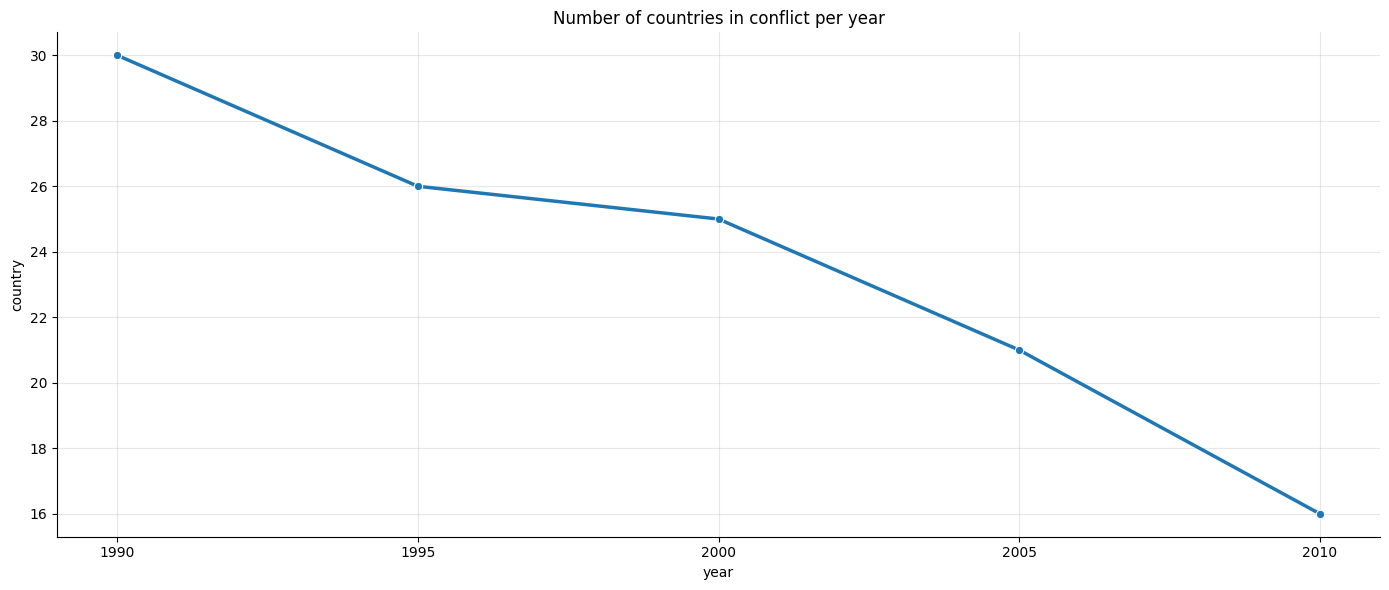

In [115]:
# Countries in conflict per year 

conflict_countries = long_df[long_df["conflict_present"] == 1]
conflict_countries = conflict_countries.groupby(["year"], as_index=False)["country"].nunique()

plt.figure(figsize=(14,6))
sns.lineplot(
    data=conflict_countries,
    x="year",
    y="country",
    marker="o",
    linewidth=2.5
)


# plot customize
sns.despine()
plt.title("Number of countries in conflict per year")
#plt.xlabel("Year", fontsize = 10)
#plt.ylabel("Population", fontsize = 10)
plt.grid(alpha=0.3)
plt.xticks(sorted(conflict_countries["year"].unique()))
#plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize = 10)
plt.tight_layout()
plt.savefig("FigA.3.NbCountriesConflict_Year_linechart.png", dpi=300)
plt.show()

## Interpretation 
The number of countries experiencing armed conflict has steadily declined since 1990, from 35 to around 18 in 2010, corresponding to a decrease of approximately 49%. The dataset contains several biases. Despite the apparent quality of the source, we closely examined several countries and confirmed they were indeed in conflict during the years listed or within the observed period. Furthermore, only countries with at least 25 battle-related deaths per year are counted, so nations that participate in conflicts without incidents on their own territory are not included. Additionally, attempts to approximate the geographic location and radius of conflicts increase the risk of missing data or double counting.

C:\Users\Utilisateur\AppData\Local\Temp\ipykernel_11336\3902585517.py:13: UserWarning: Numpy array is not a supported type for `palette`. Please convert your palette to a list. This will become an error in v0.14
  sns.lineplot(


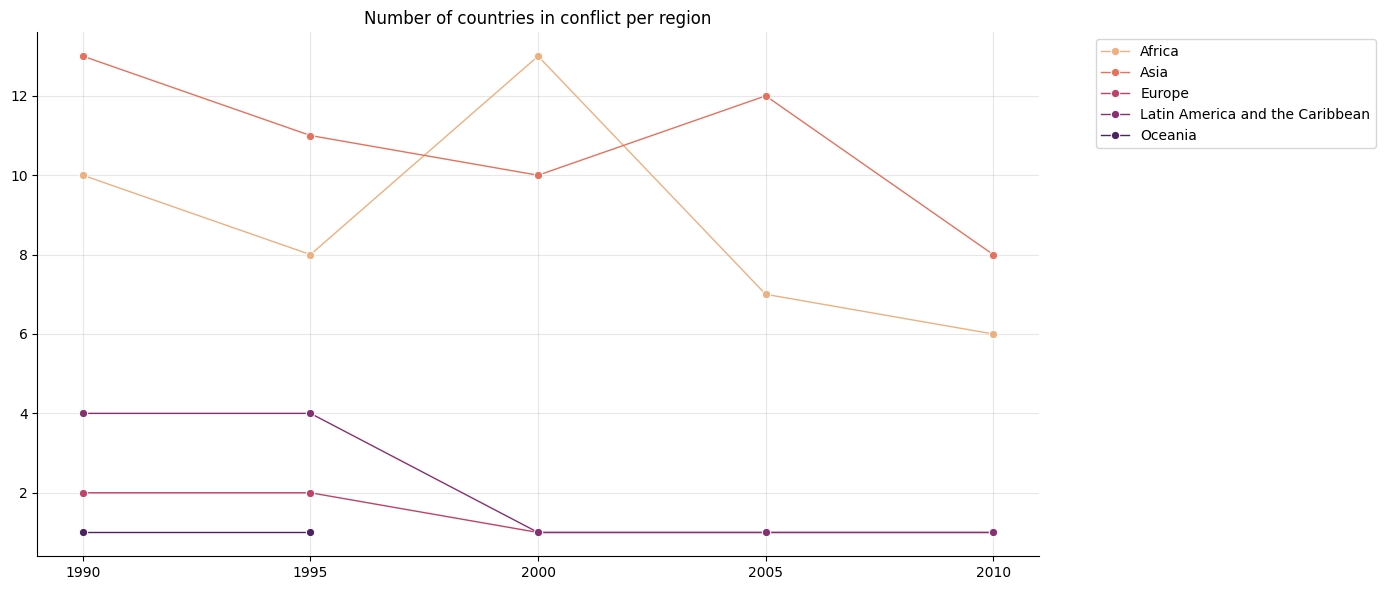

In [116]:
# Countries in conflict per year per region

conflict_countries = long_df[long_df["conflict_present"] == 1]
conflict_countries = conflict_countries.groupby(["year", "un_region"], as_index=False)["country"].nunique()

# regions unique
n = conflict_countries["un_region"].nunique()

# color for each region (from continuous to non continuous data)
colors = colormaps['flare'](np.linspace(0, 1, n))

plt.figure(figsize=(14,6))
sns.lineplot(
    data=conflict_countries,
    x="year",
    y="country",
    hue="un_region",
    marker="o",
    linewidth=1,
    markersize=6,
    palette=colors
)

# plot customize
sns.despine()
plt.title("Number of countries in conflict per region")
plt.xlabel("", fontsize = 10)
plt.ylabel("", fontsize = 10)
plt.grid(alpha=0.3)
plt.xticks(sorted(conflict_countries["year"].unique()))
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize = 10)
plt.tight_layout()
plt.savefig("FigA.4.NbCountriesConflict_Year_Region_linechart.png", dpi=300)
plt.show()

## Interpretation
Africa and Asia have experienced the highest number of conflicts, with notable increases around 2000 for Africa and 2005 for Asia. After these peaks, the number of conflicts decreased. In contrast, other regions have consistently experienced very few conflicts, remaining at low levels throughout the period.
### Add
Asia and Africa have the bggest religious population and the highest number of countries in conflict

In [117]:
conflict_years_per_country1 = (
    long_df.groupby(["country", "year","un_region"])["conflict_present"] # put all the variables in one row
    .mean()  # addition of all conflict_presence
    .reset_index(name="years_in_conflict")
) #could have done a wide format

conflict_years_per_country2 = (
    conflict_years_per_country1.groupby(["country","un_region"])["years_in_conflict"] # put all the variables in one row
    .sum()  # addition of all conflict_presence
    .reset_index(name="years_in_conflict")
)

country_summary = conflict_years_per_country2.describe()
conflict_years_per_country2

,country,un_region,years_in_conflict
0,Afghanistan,Asia,5.0
1,Albania,Europe,0.0
2,Algeria,Africa,4.0
3,Andorra,Europe,0.0
4,Angola,Africa,3.0
...,...,...,...
158,Uzbekistan,Asia,1.0
159,Vanuatu,Oceania,0.0
160,Viet Nam,Asia,0.0
161,Zambia,Africa,0.0


The majority of the countries did not experienced to be in conflict at the analysed years. 75% of them have experienced 1 mentioned year (which is different from a period) or not at all. Some countries could have encounter conflicts in between those years, which might not be reflected in the current dataset.

In [118]:
# Filter contries in conflict at least 1 mentioned year
countries_in_conflict = conflict_years_per_country2[conflict_years_per_country2["years_in_conflict"] > 0]

# Mean
mean_years_conflict = countries_in_conflict ["years_in_conflict"].mean()
#mean_years_conflict
## result: 2.63
#len(countries_in_conflict)
# result : 52

52 countries on 192 (27% a quarter) experienced conflict for 2 up to 3 reported years. 

In [120]:
# Analyze countries more often in conflict
conflict_3_of_5 = countries_in_conflict[
    (countries_in_conflict["years_in_conflict"] >= 3)]
conflict_3_of_5.describe()

,years_in_conflict
count,20.000000
mean,4.200000
std,0.833509
min,3.000000
25%,3.750000
50%,4.000000
75%,5.000000
max,5.000000


In [121]:
# A list of countries with =>3 years of conflict
country_conflict_list = conflict_3_of_5.country.unique()

# Selct the initial data
df_selected = long_df[long_df["country"].isin(country_conflict_list)]

# did not find it alone! it applies a transofrmation for each row (i.e. religion in each country) to calculate the value of the religion (pop) 
# divided by the sum of relig_pop for this year in this country
df_selected["prop_relig"] = df_selected.groupby(["country","year"])["relig_pop"].transform(lambda x: x / x.sum())

df_selected
df_selected.to_csv("df_selected.csv")

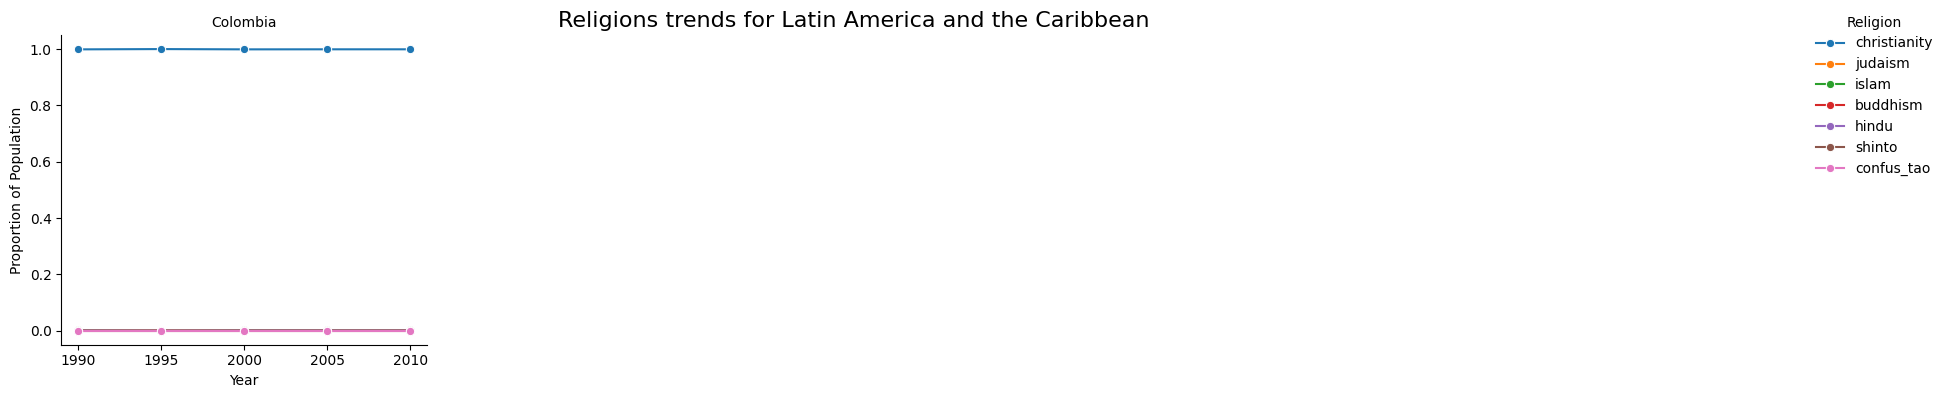

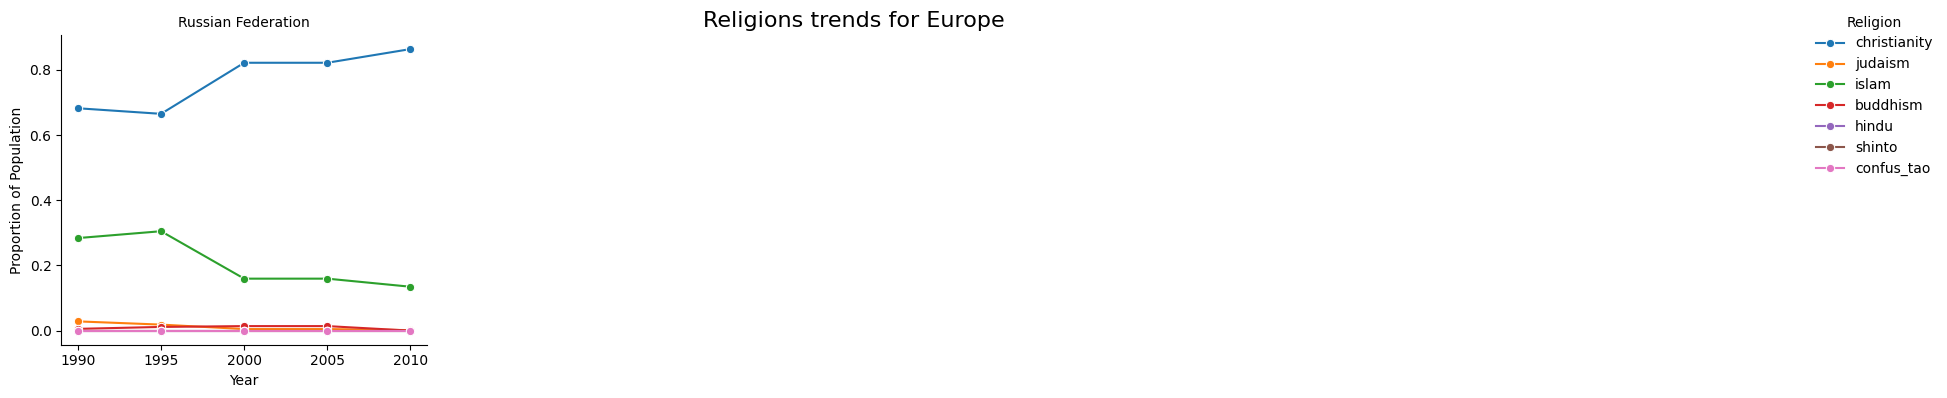

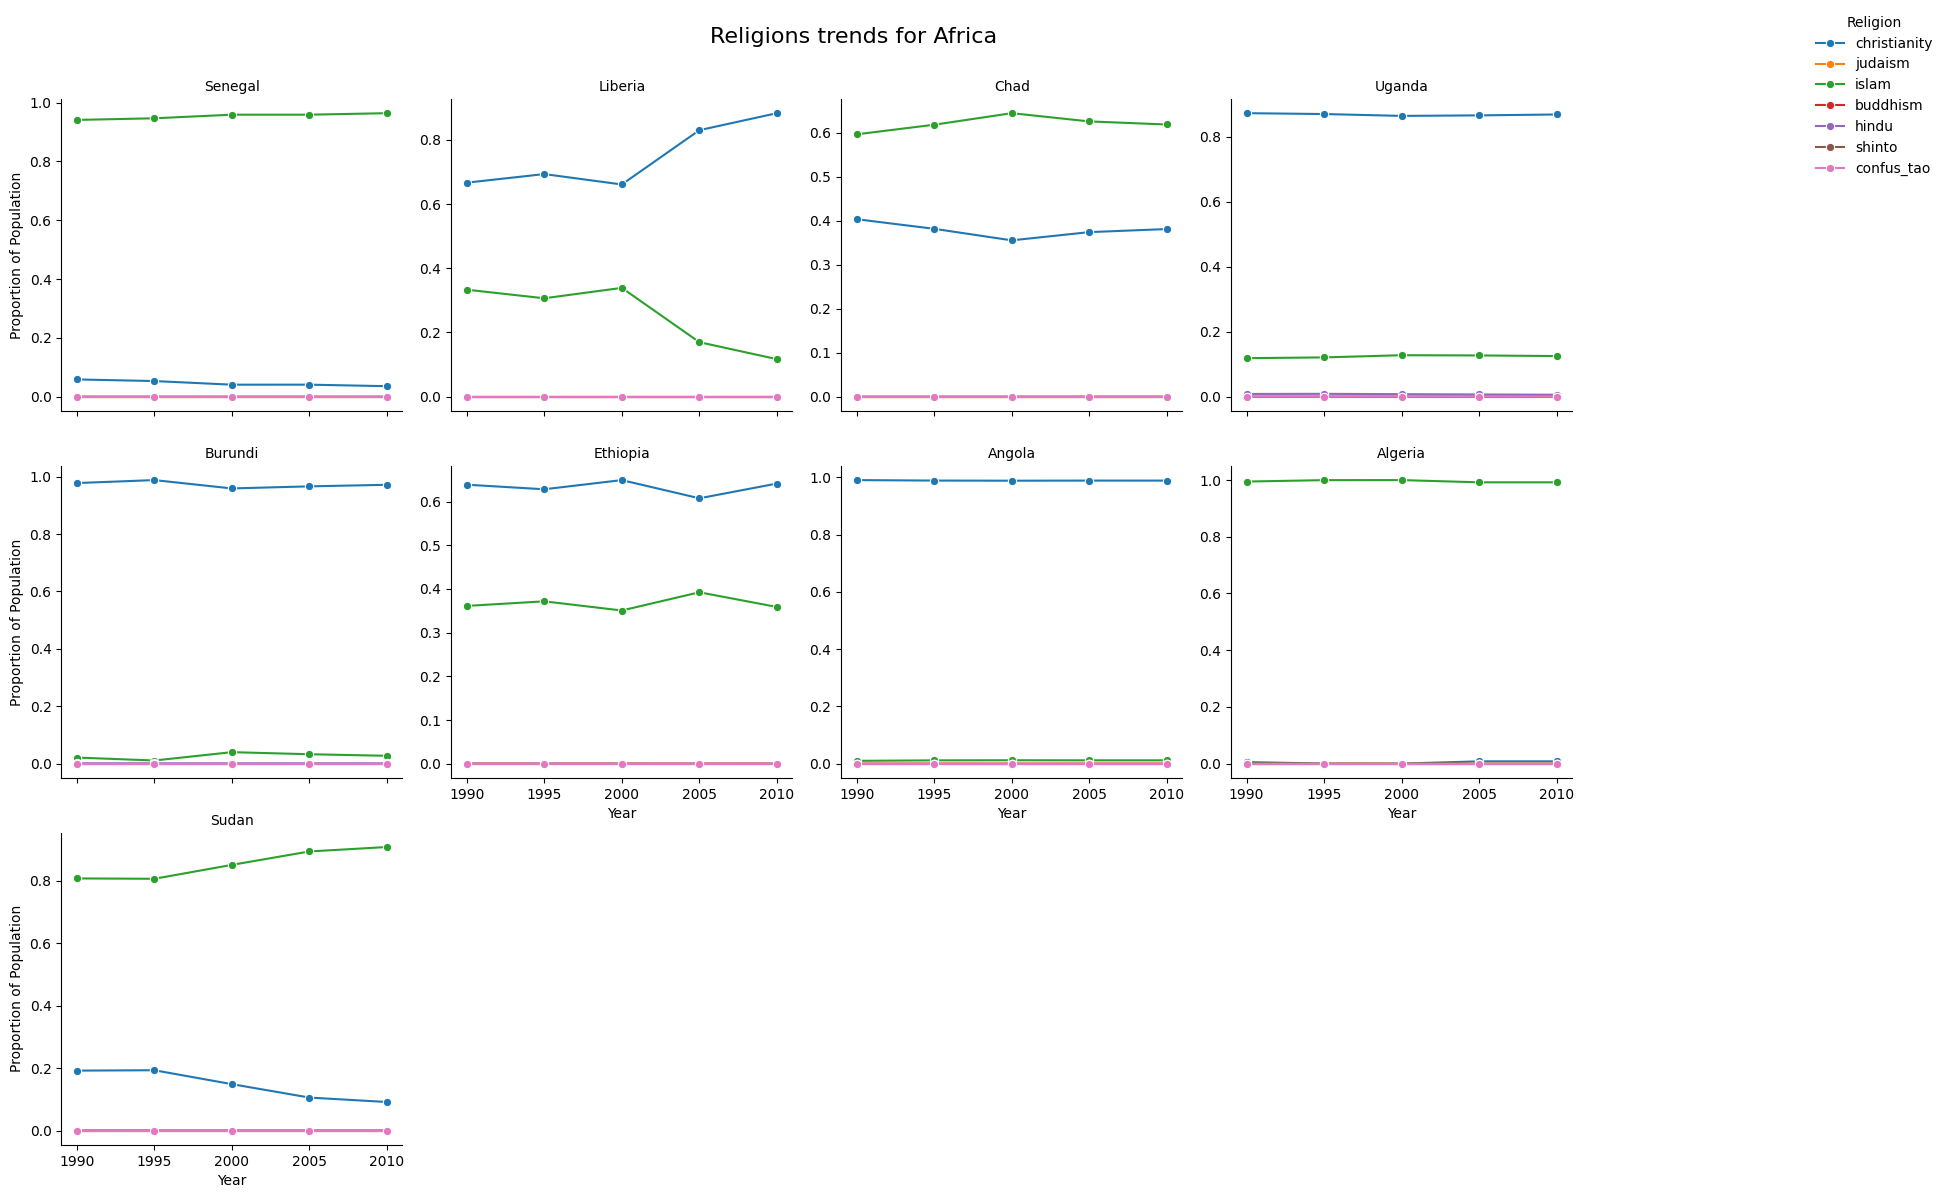

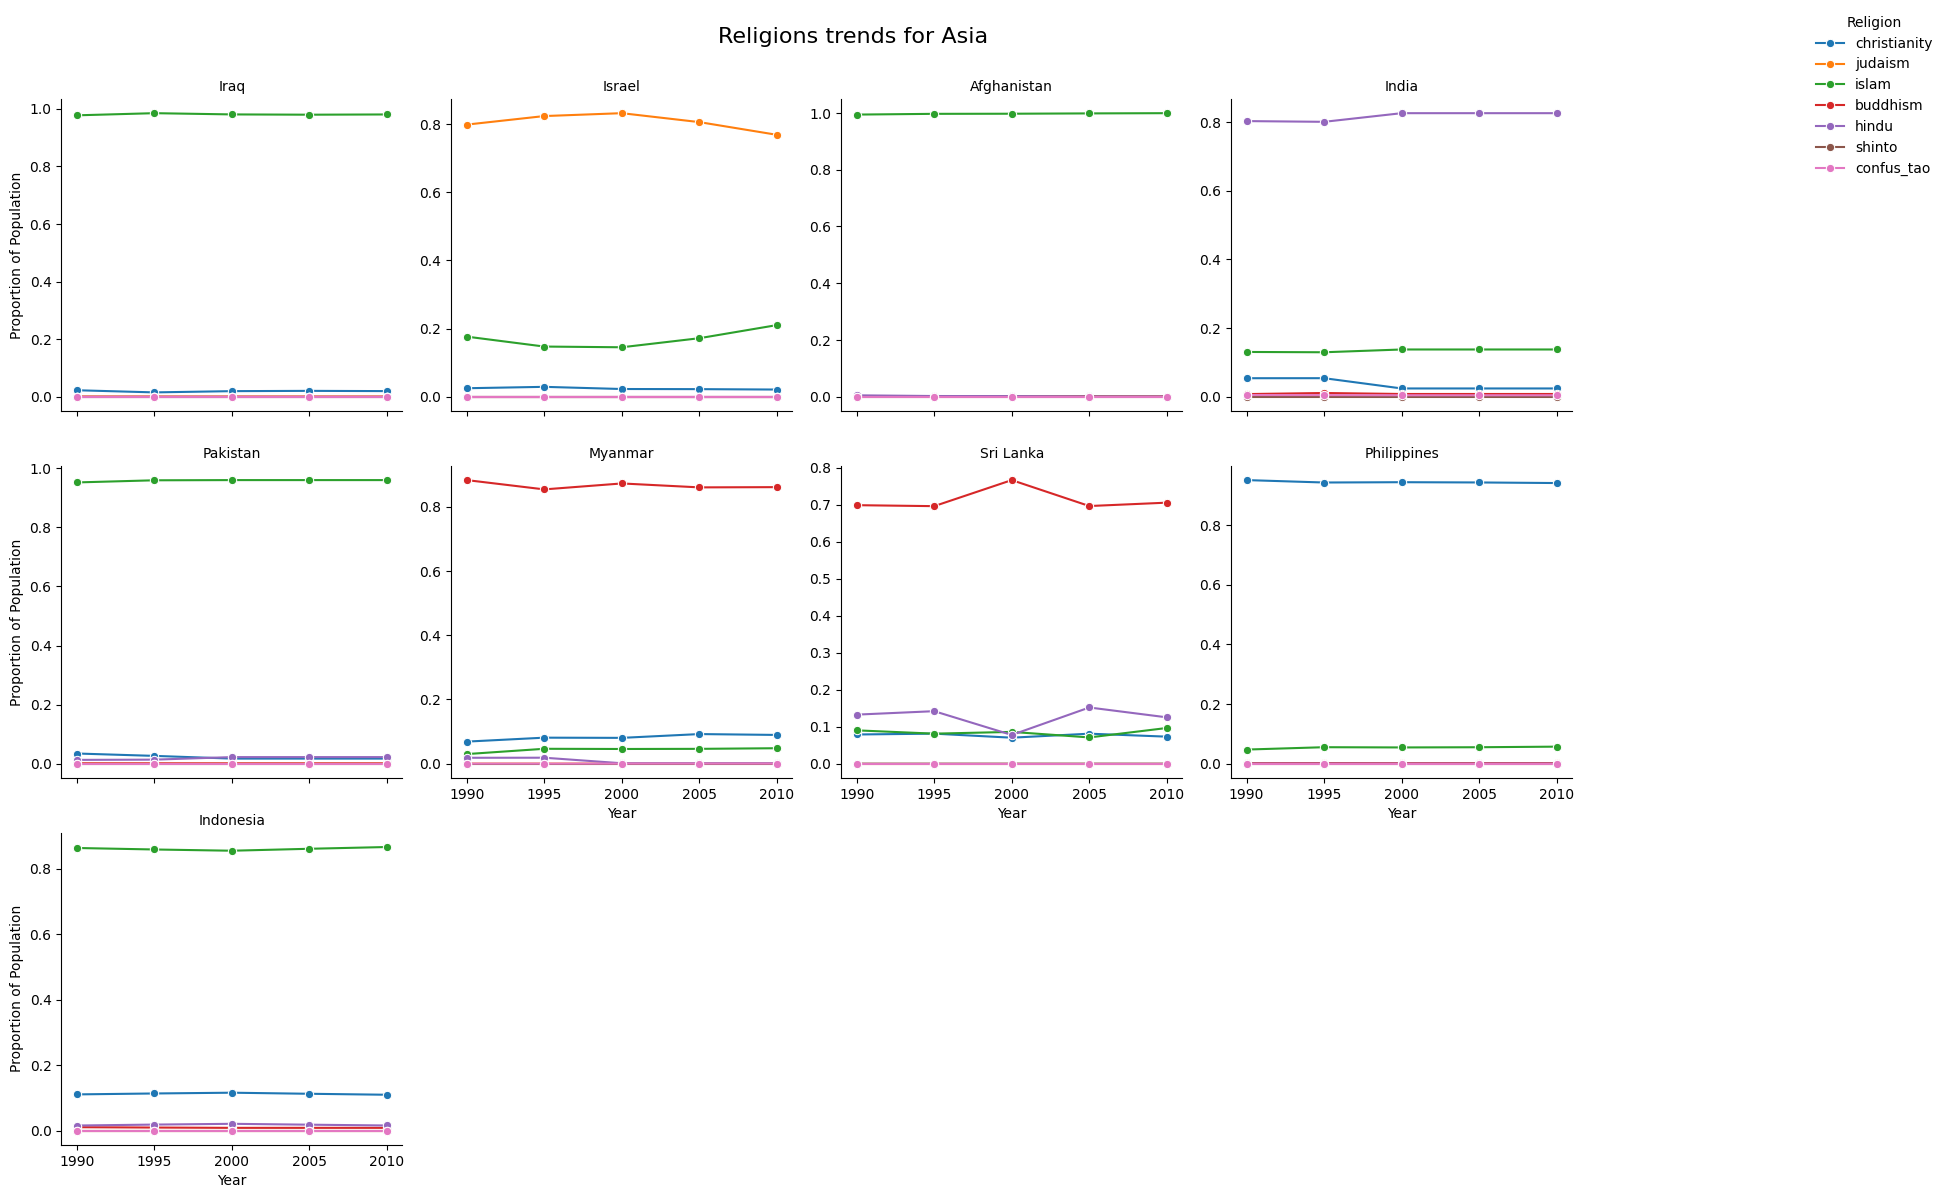

In [123]:
# Plotting facet grid region and countries
for region in df_selected["un_region"].unique():
    df_region = df_selected[df_selected["un_region"] == region]
    num_countries = len(country_conflict_list)
    if num_countries == 0:
        continue  # next

    cols = 4
    rows = (num_countries + cols - 1) // cols # (n + k - 1) // k // means division integer it is a trick
    
    g = sns.FacetGrid(
        df_region,
        col="country",
        col_wrap=cols,
        height=4,
        sharey=False
    )
    
    g.map_dataframe(
        sns.lineplot,
        x="year",
        y="prop_relig",
        hue="religion",
        marker="o"
    )
    
    g.set_axis_labels("Year", "Proportion of Population")
    g.set_titles(col_template="{col_name}")
    g.add_legend(title="Religion", bbox_to_anchor=(1.05,1), loc="upper left")
    plt.subplots_adjust(top=0.92)
    g.fig.suptitle(f"Religions trends for {region}", fontsize=16)
    plt.savefig(f"FigA.5.1.ReligiousTrendsConflict_country_region_facetgrid_{region}.png")
    plt.show()

In [124]:
# Filter contries out of conflicts
countries_no_conflict = conflict_years_per_country2[conflict_years_per_country2["years_in_conflict"] == 0]

# Mean
mean_years_no_conflict = countries_no_conflict ["years_in_conflict"].mean()
#mean_years_no_conflict
## result: 0
#len(mean_years_no_conflict)
# result : 140

In [125]:
# A list of countries with = 0 years of conflict
no_conflict_list = countries_no_conflict .country.unique()

# Selct the initial data
df_selected_0 = long_df[long_df["country"].isin(no_conflict_list)]

# did not find it alone! it applies a transofrmation for each row (i.e. religion in each country) to calculate the value of the religion (pop) 
# divided by the sum of relig_pop for this year in this country
df_selected_0["prop_relig"] = df_selected_0.groupby(["country","year"])["relig_pop"].transform(lambda x: x / x.sum())

df_selected_0


,year,country,gdp,un_region,hdi,conflict_present,population,religion,relig_pop,prop_relig
0,1990,United States,5.963144e+12,Northern America,0.88,0.0,249623000.0,christianity,214425162,0.956001
1,1995,United States,7.639749e+12,Northern America,0.89,0.0,266278000.0,christianity,215593975,0.955724
2,2000,United States,1.025095e+13,Northern America,0.89,0.0,282162411.0,christianity,219818305,0.952692
3,2005,United States,1.303920e+13,Northern America,0.91,0.0,295516599.0,christianity,226464805,0.944264
4,2010,United States,1.504896e+13,Northern America,0.92,0.0,309378227.0,christianity,233111307,0.942517
...,...,...,...,...,...,...,...,...,...,...
5448,1990,Samoa,1.257663e+08,Oceania,0.66,0.0,169042.0,confus_tao,0,0.000000
5449,1995,Samoa,2.248657e+08,Oceania,0.66,0.0,174571.0,confus_tao,0,0.000000
5450,2000,Samoa,2.588561e+08,Oceania,0.67,0.0,181685.0,confus_tao,0,0.000000
5451,2005,Samoa,4.768018e+08,Oceania,0.69,0.0,186978.0,confus_tao,0,0.000000


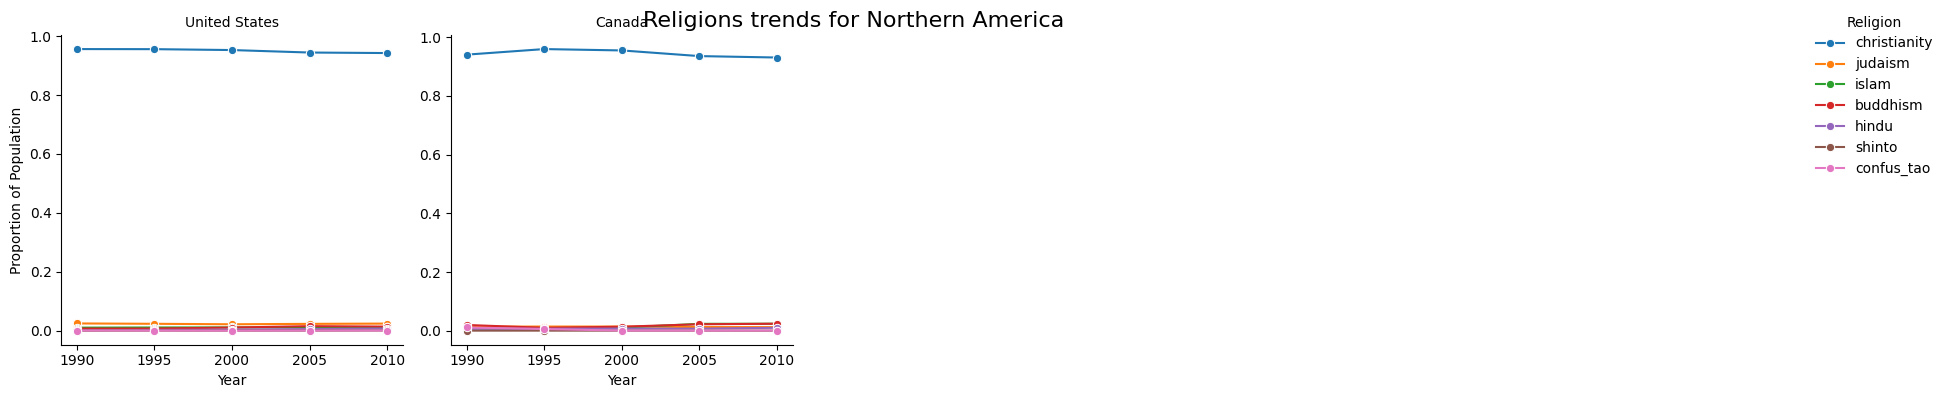

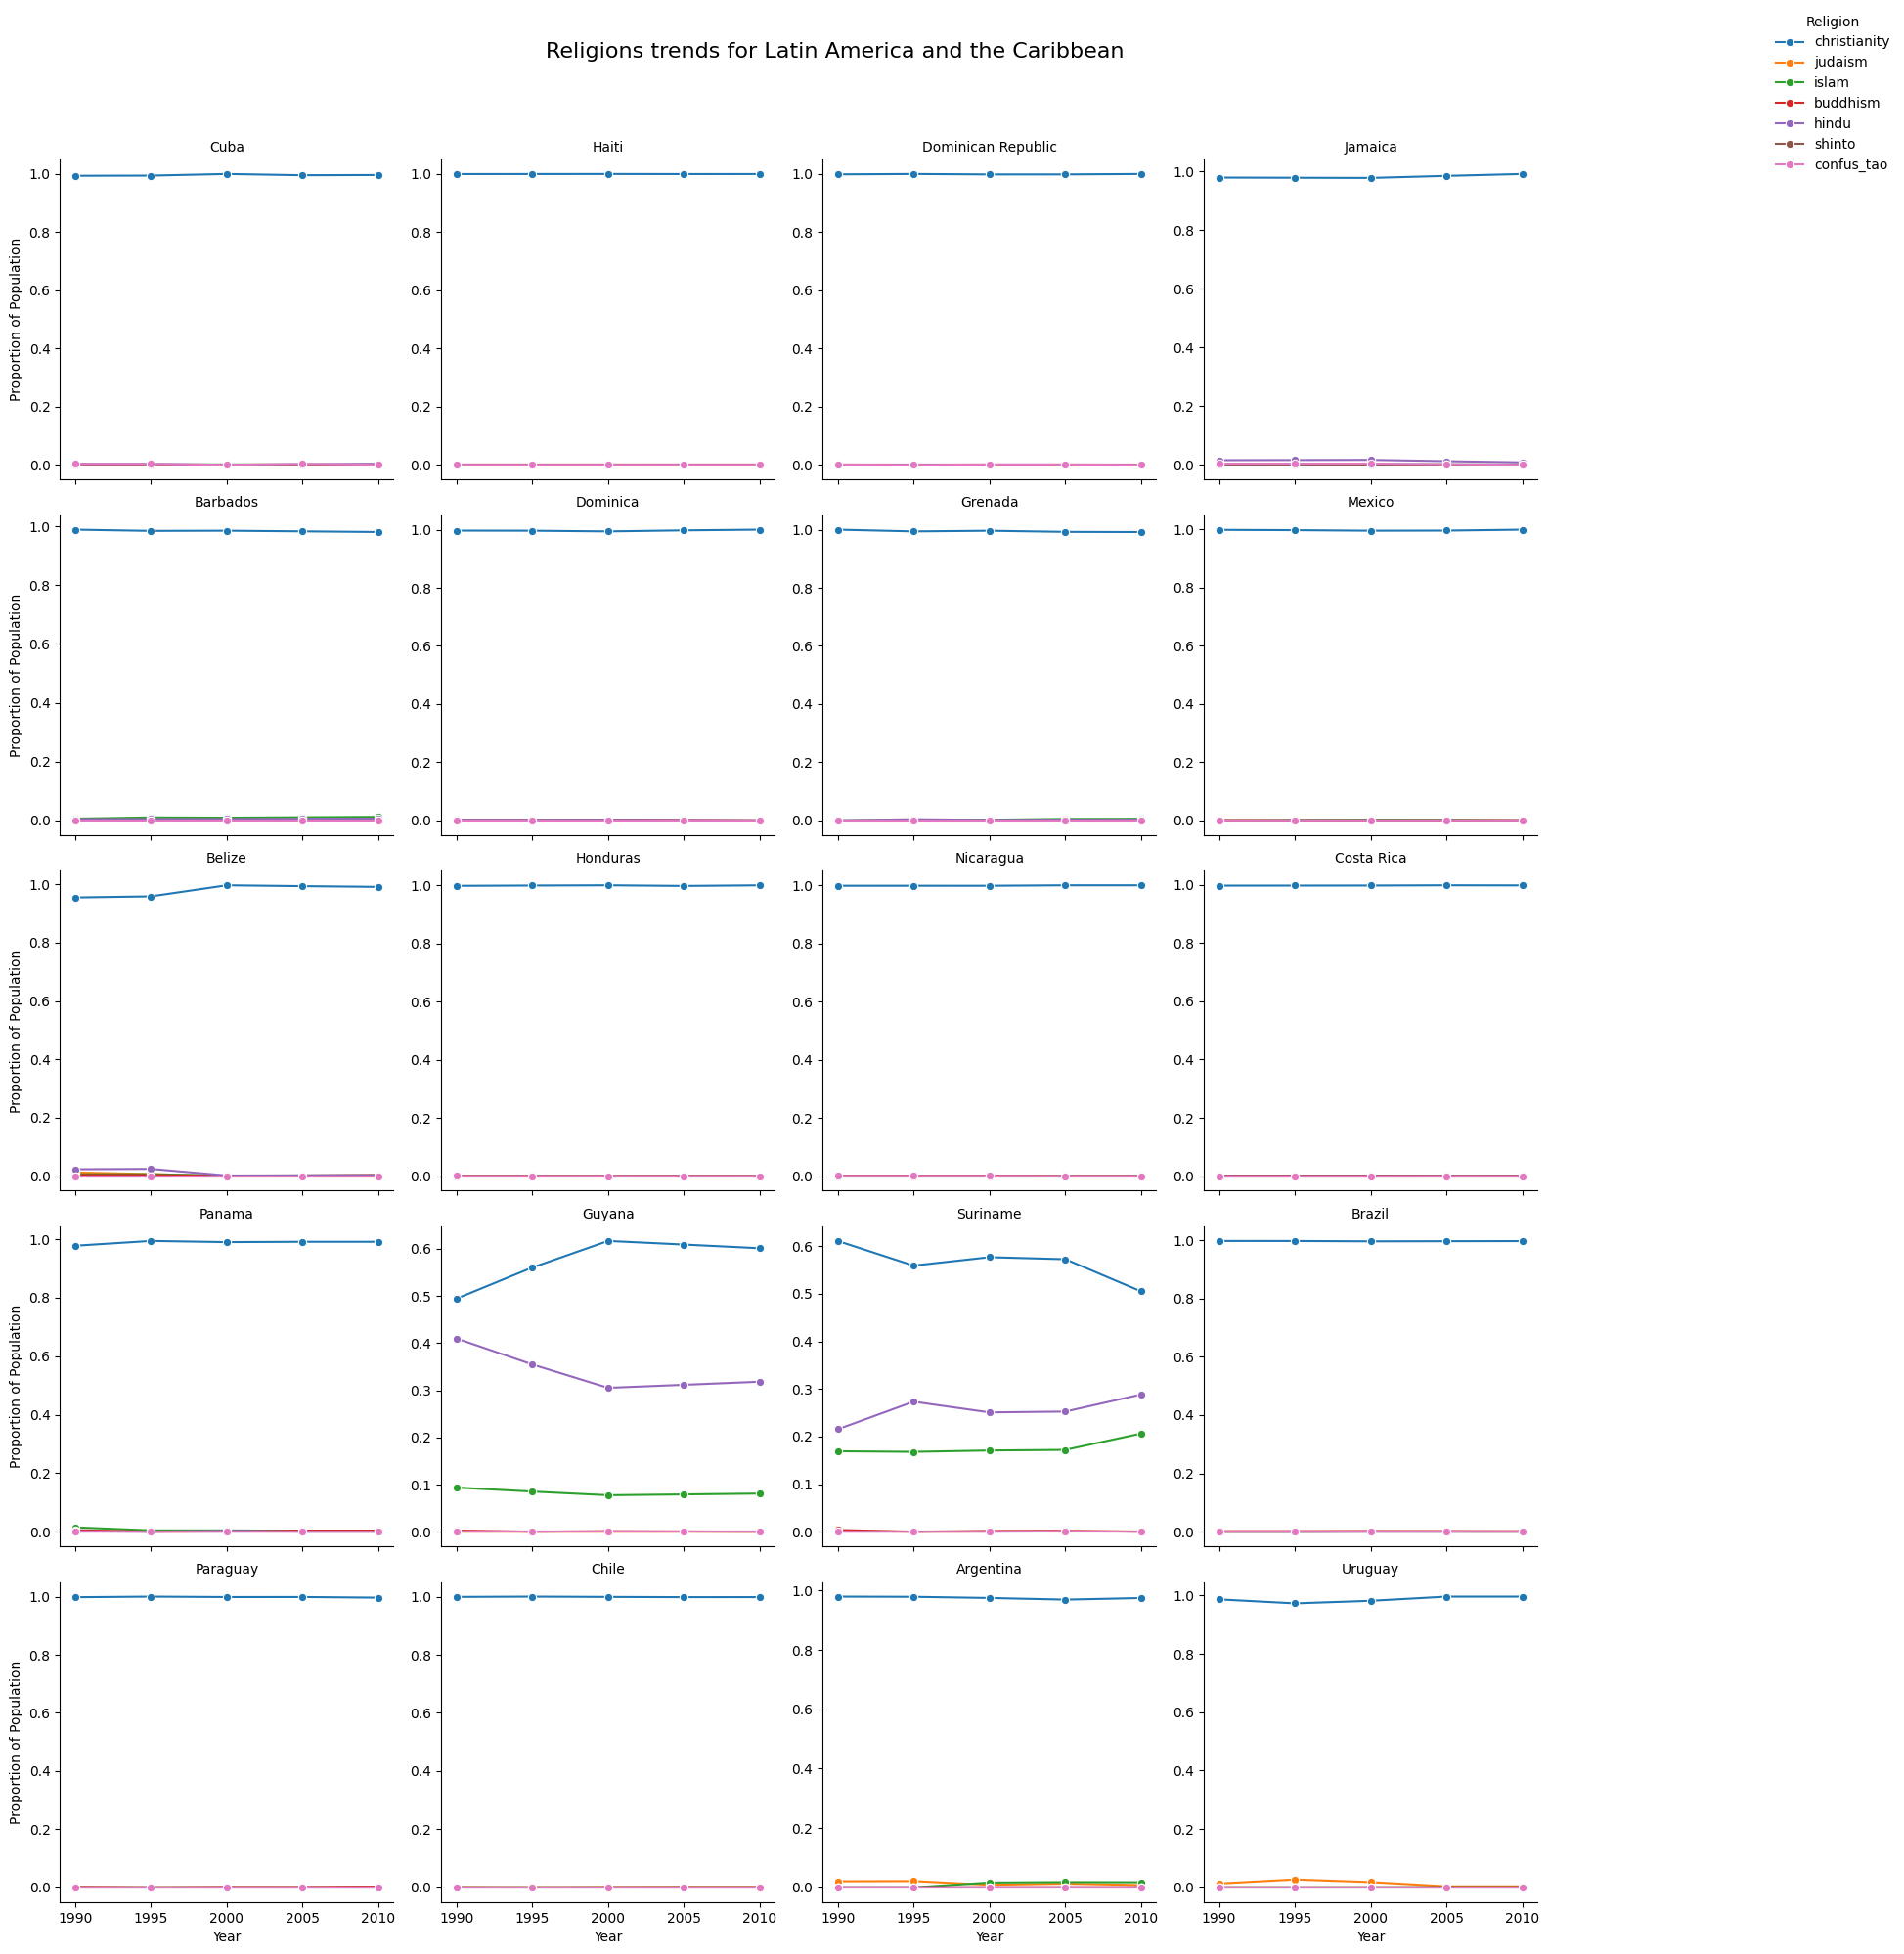

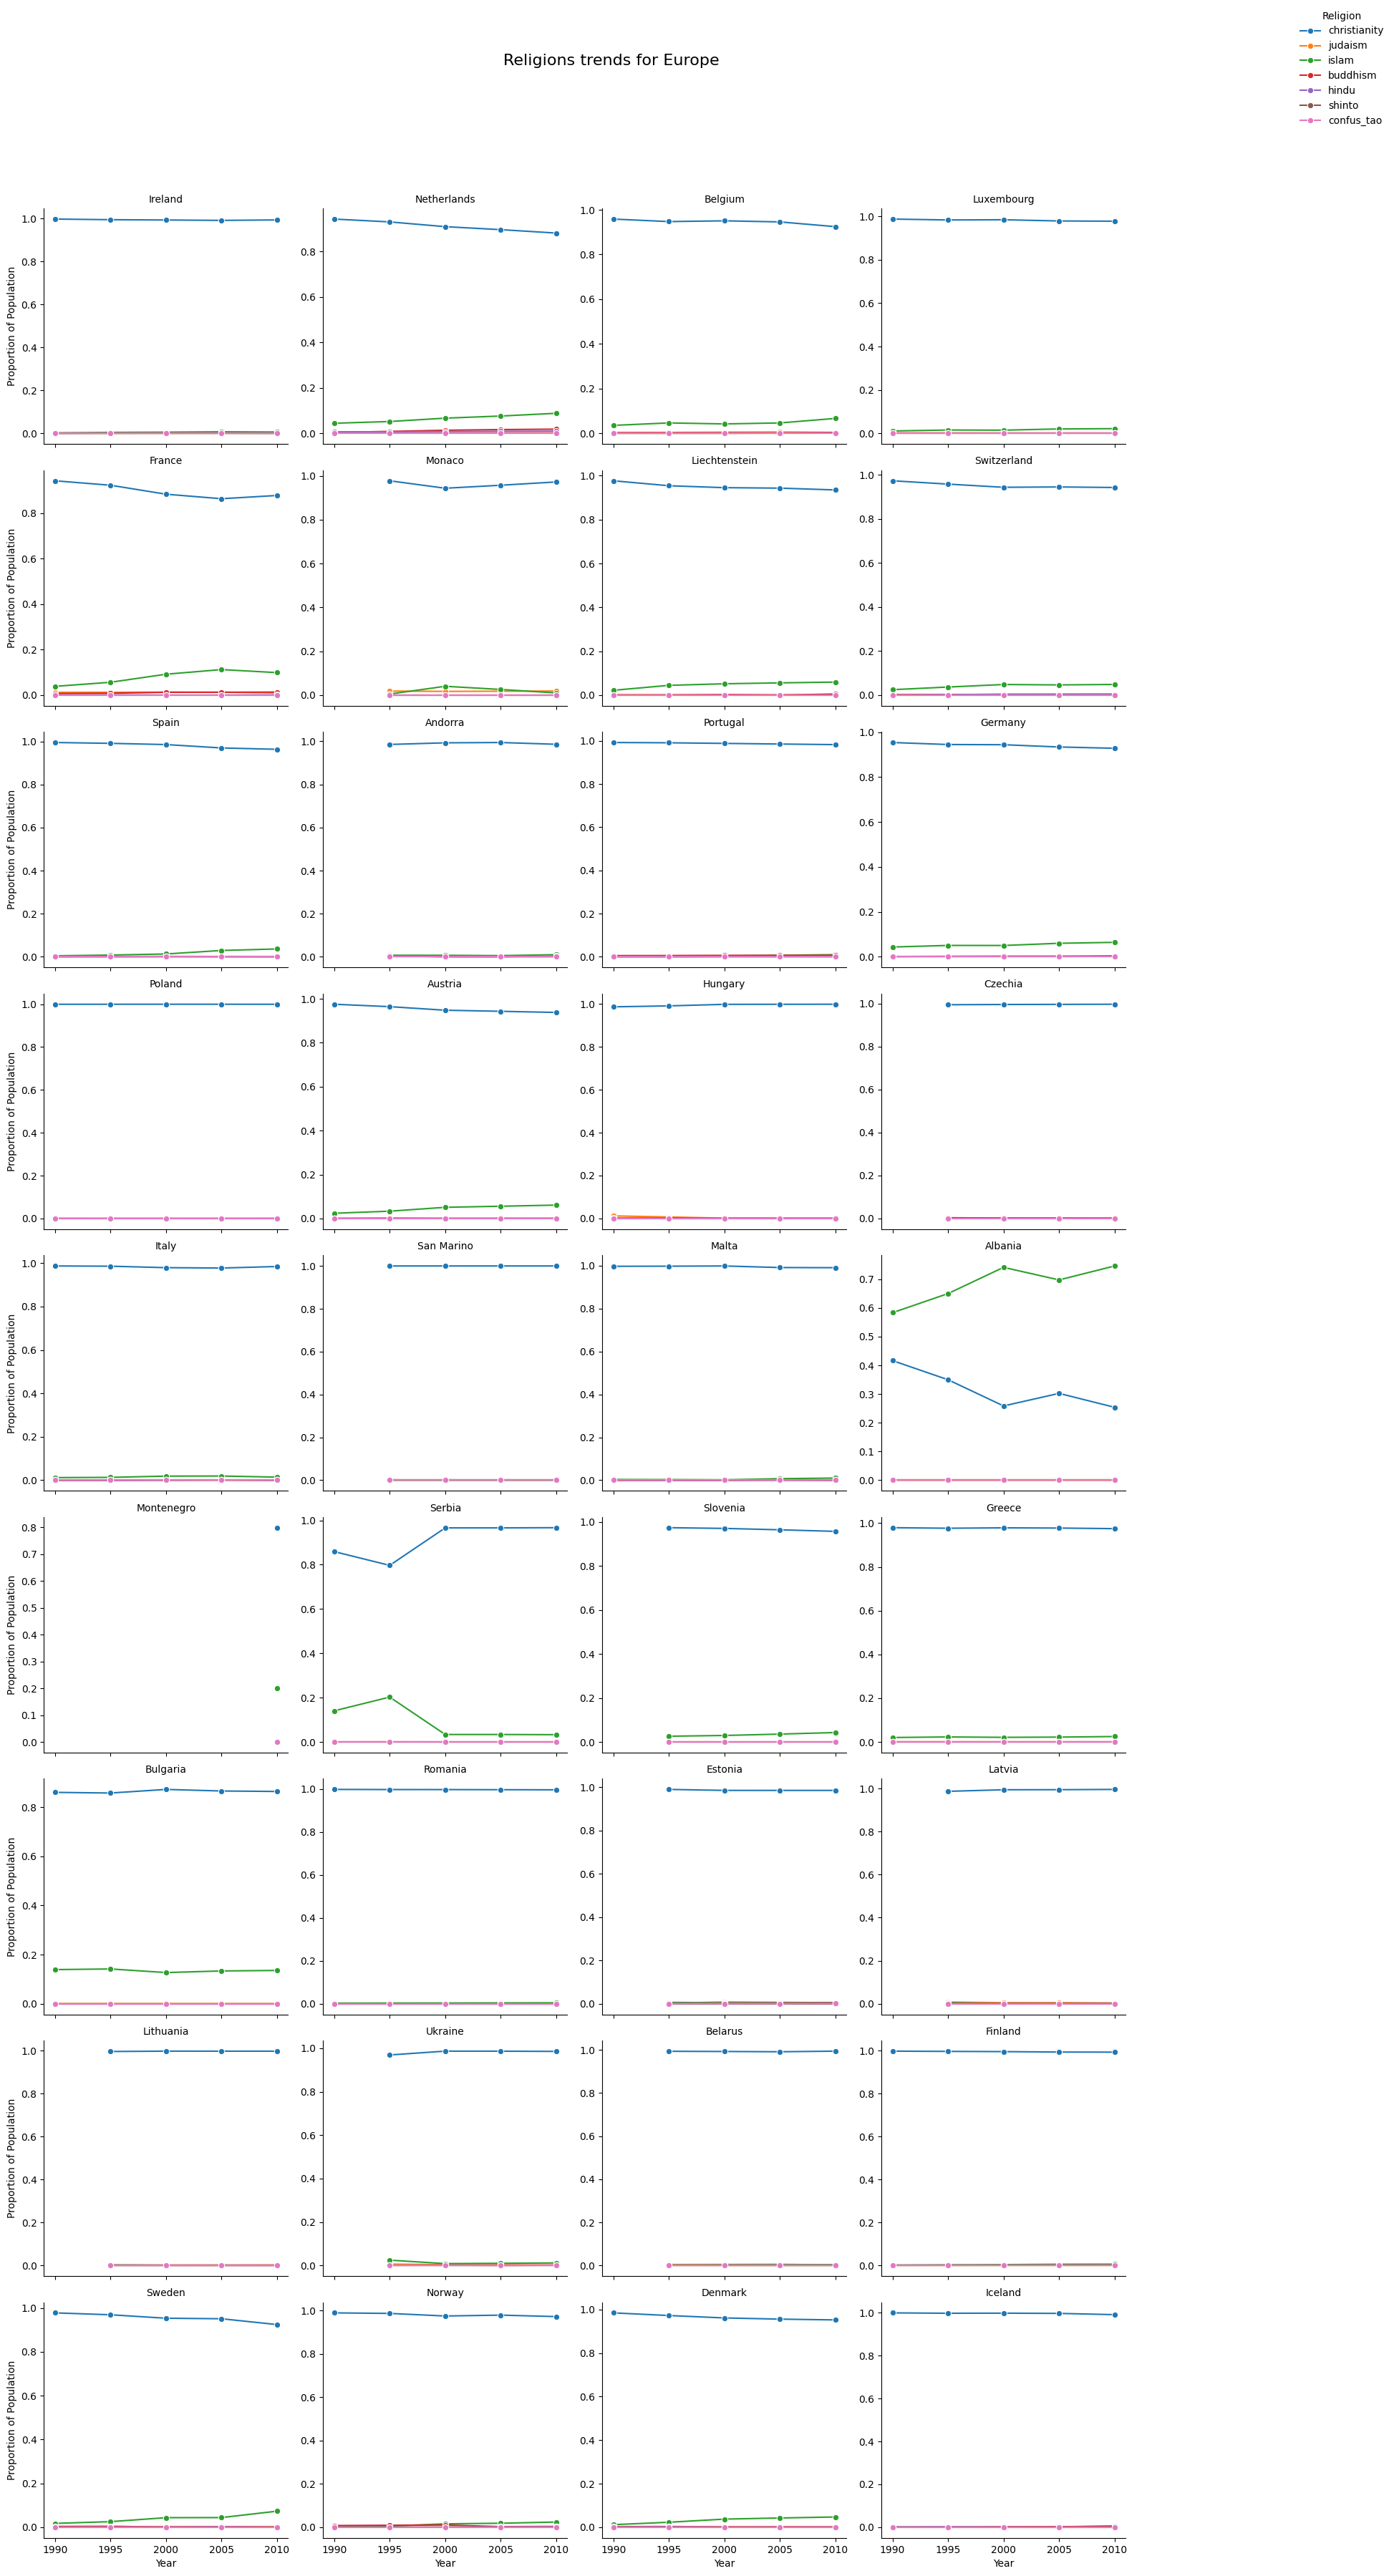

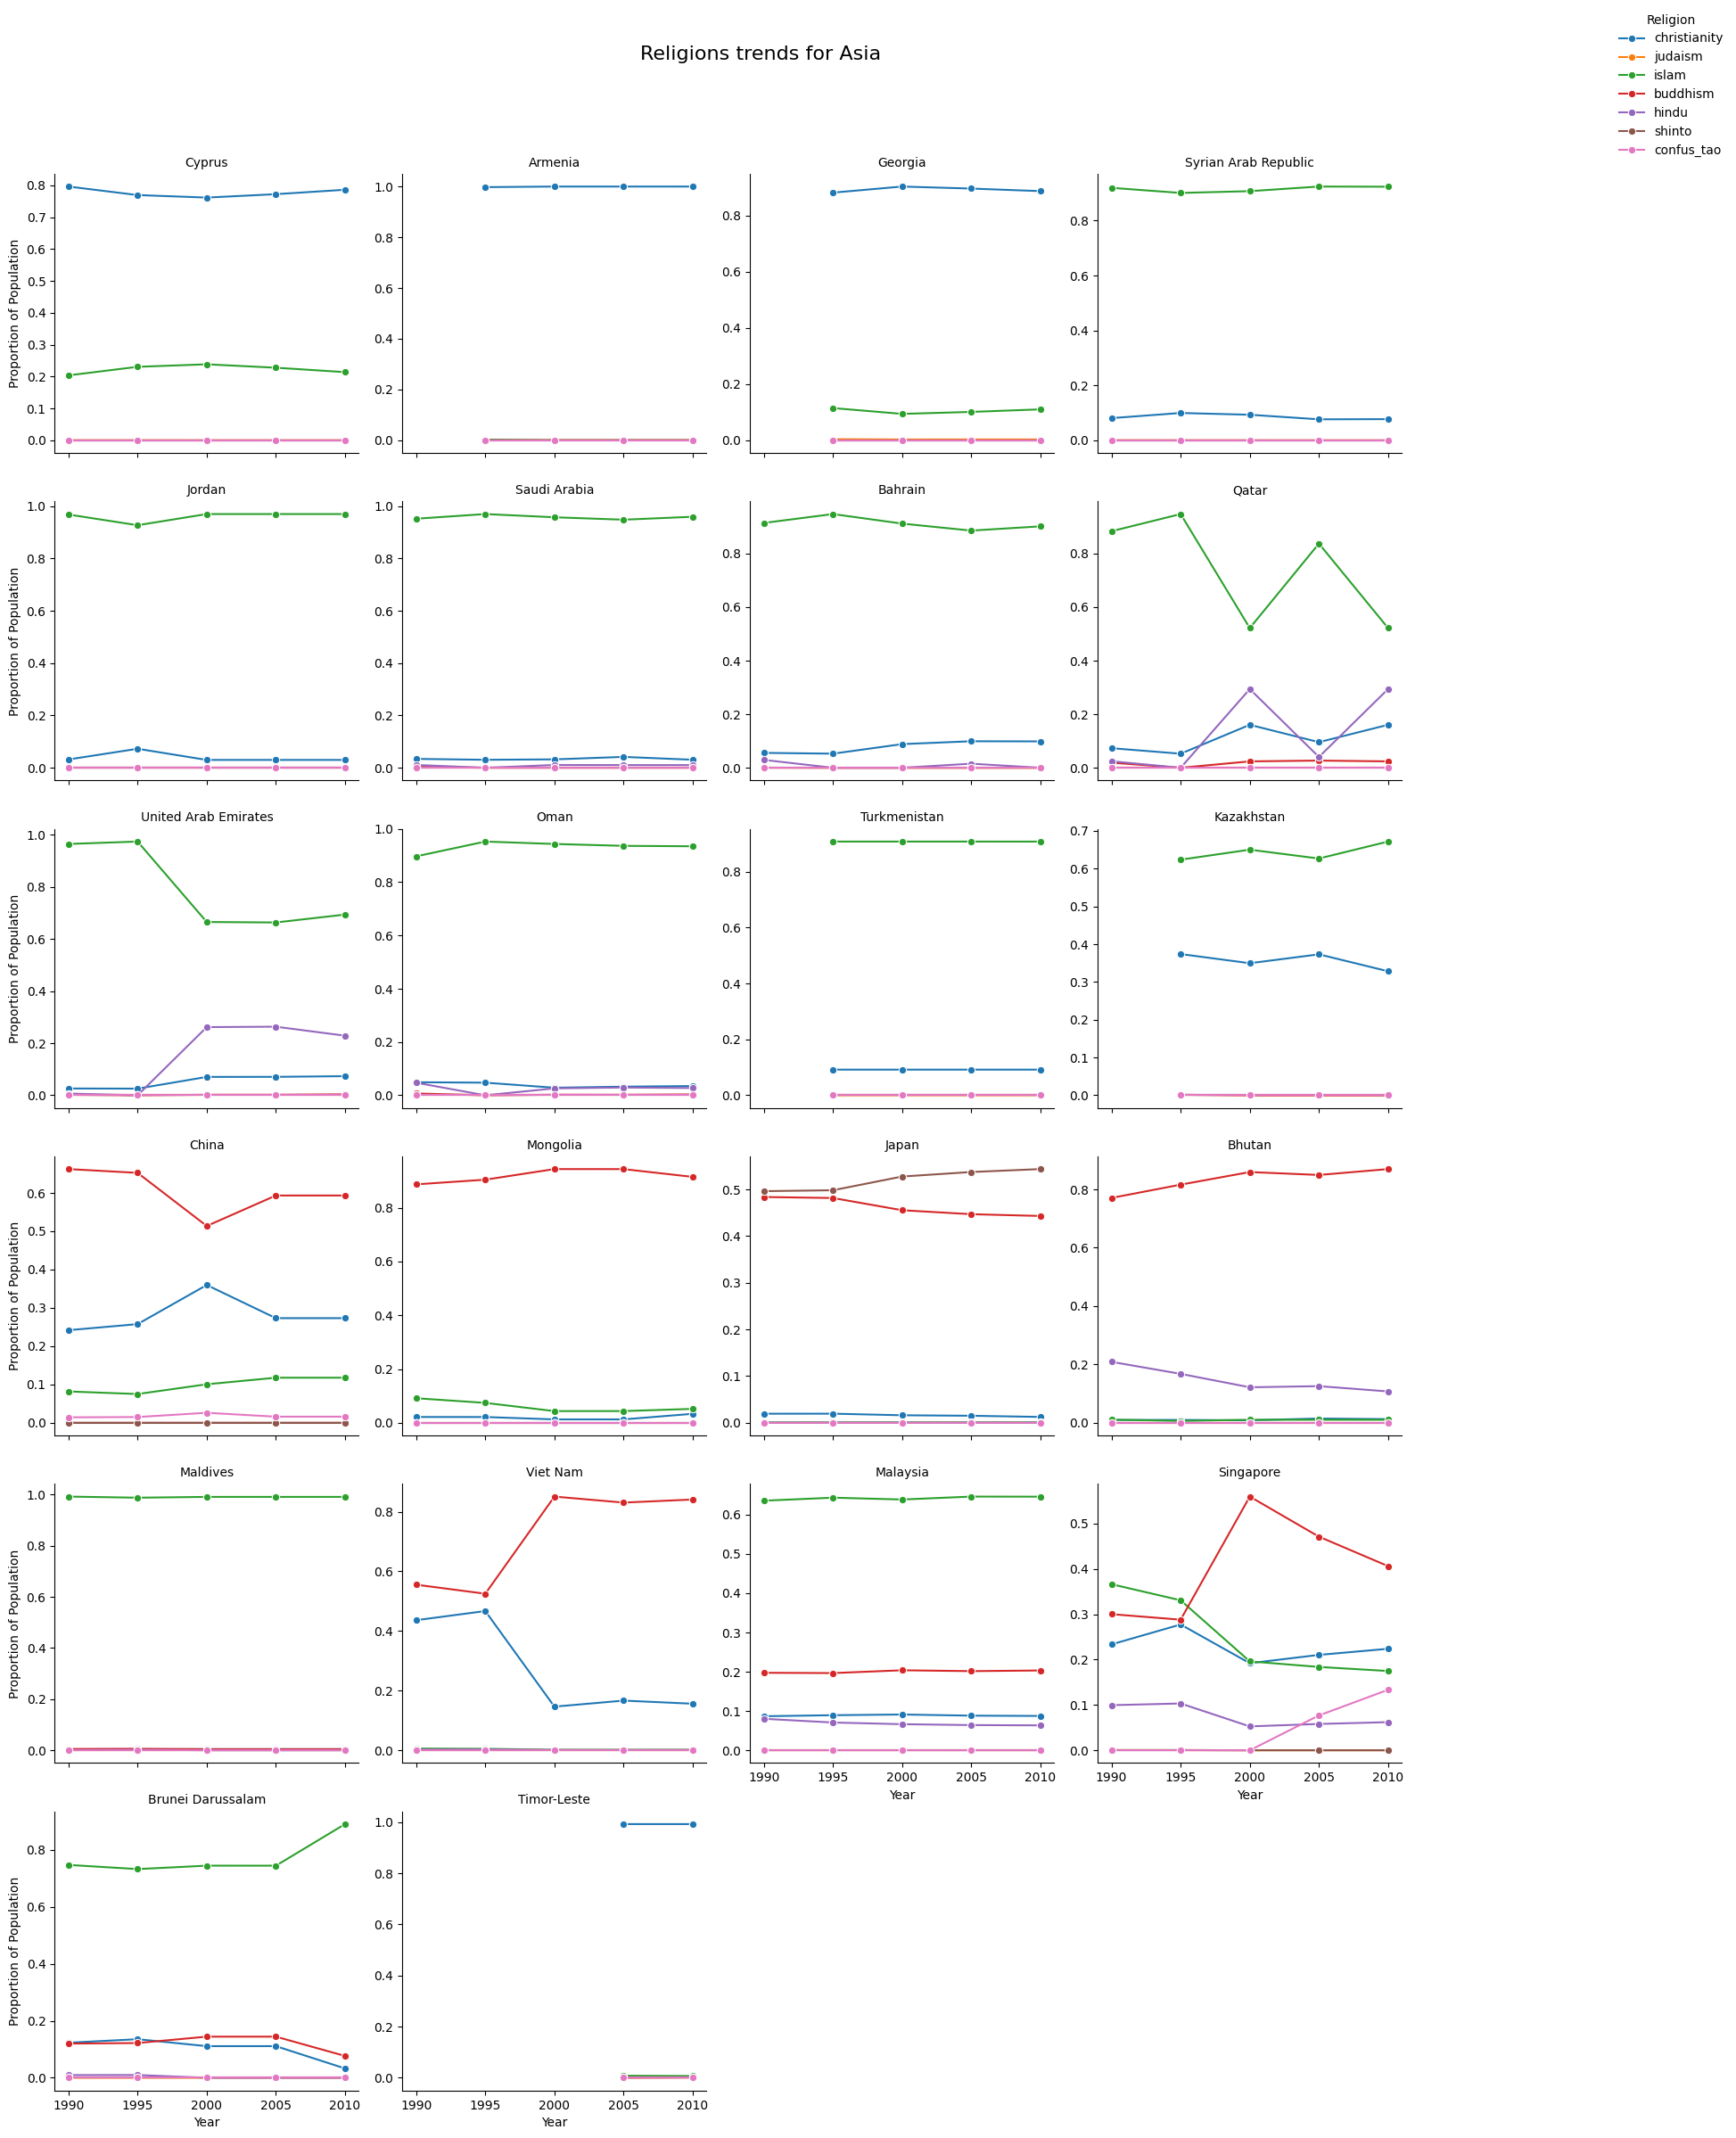

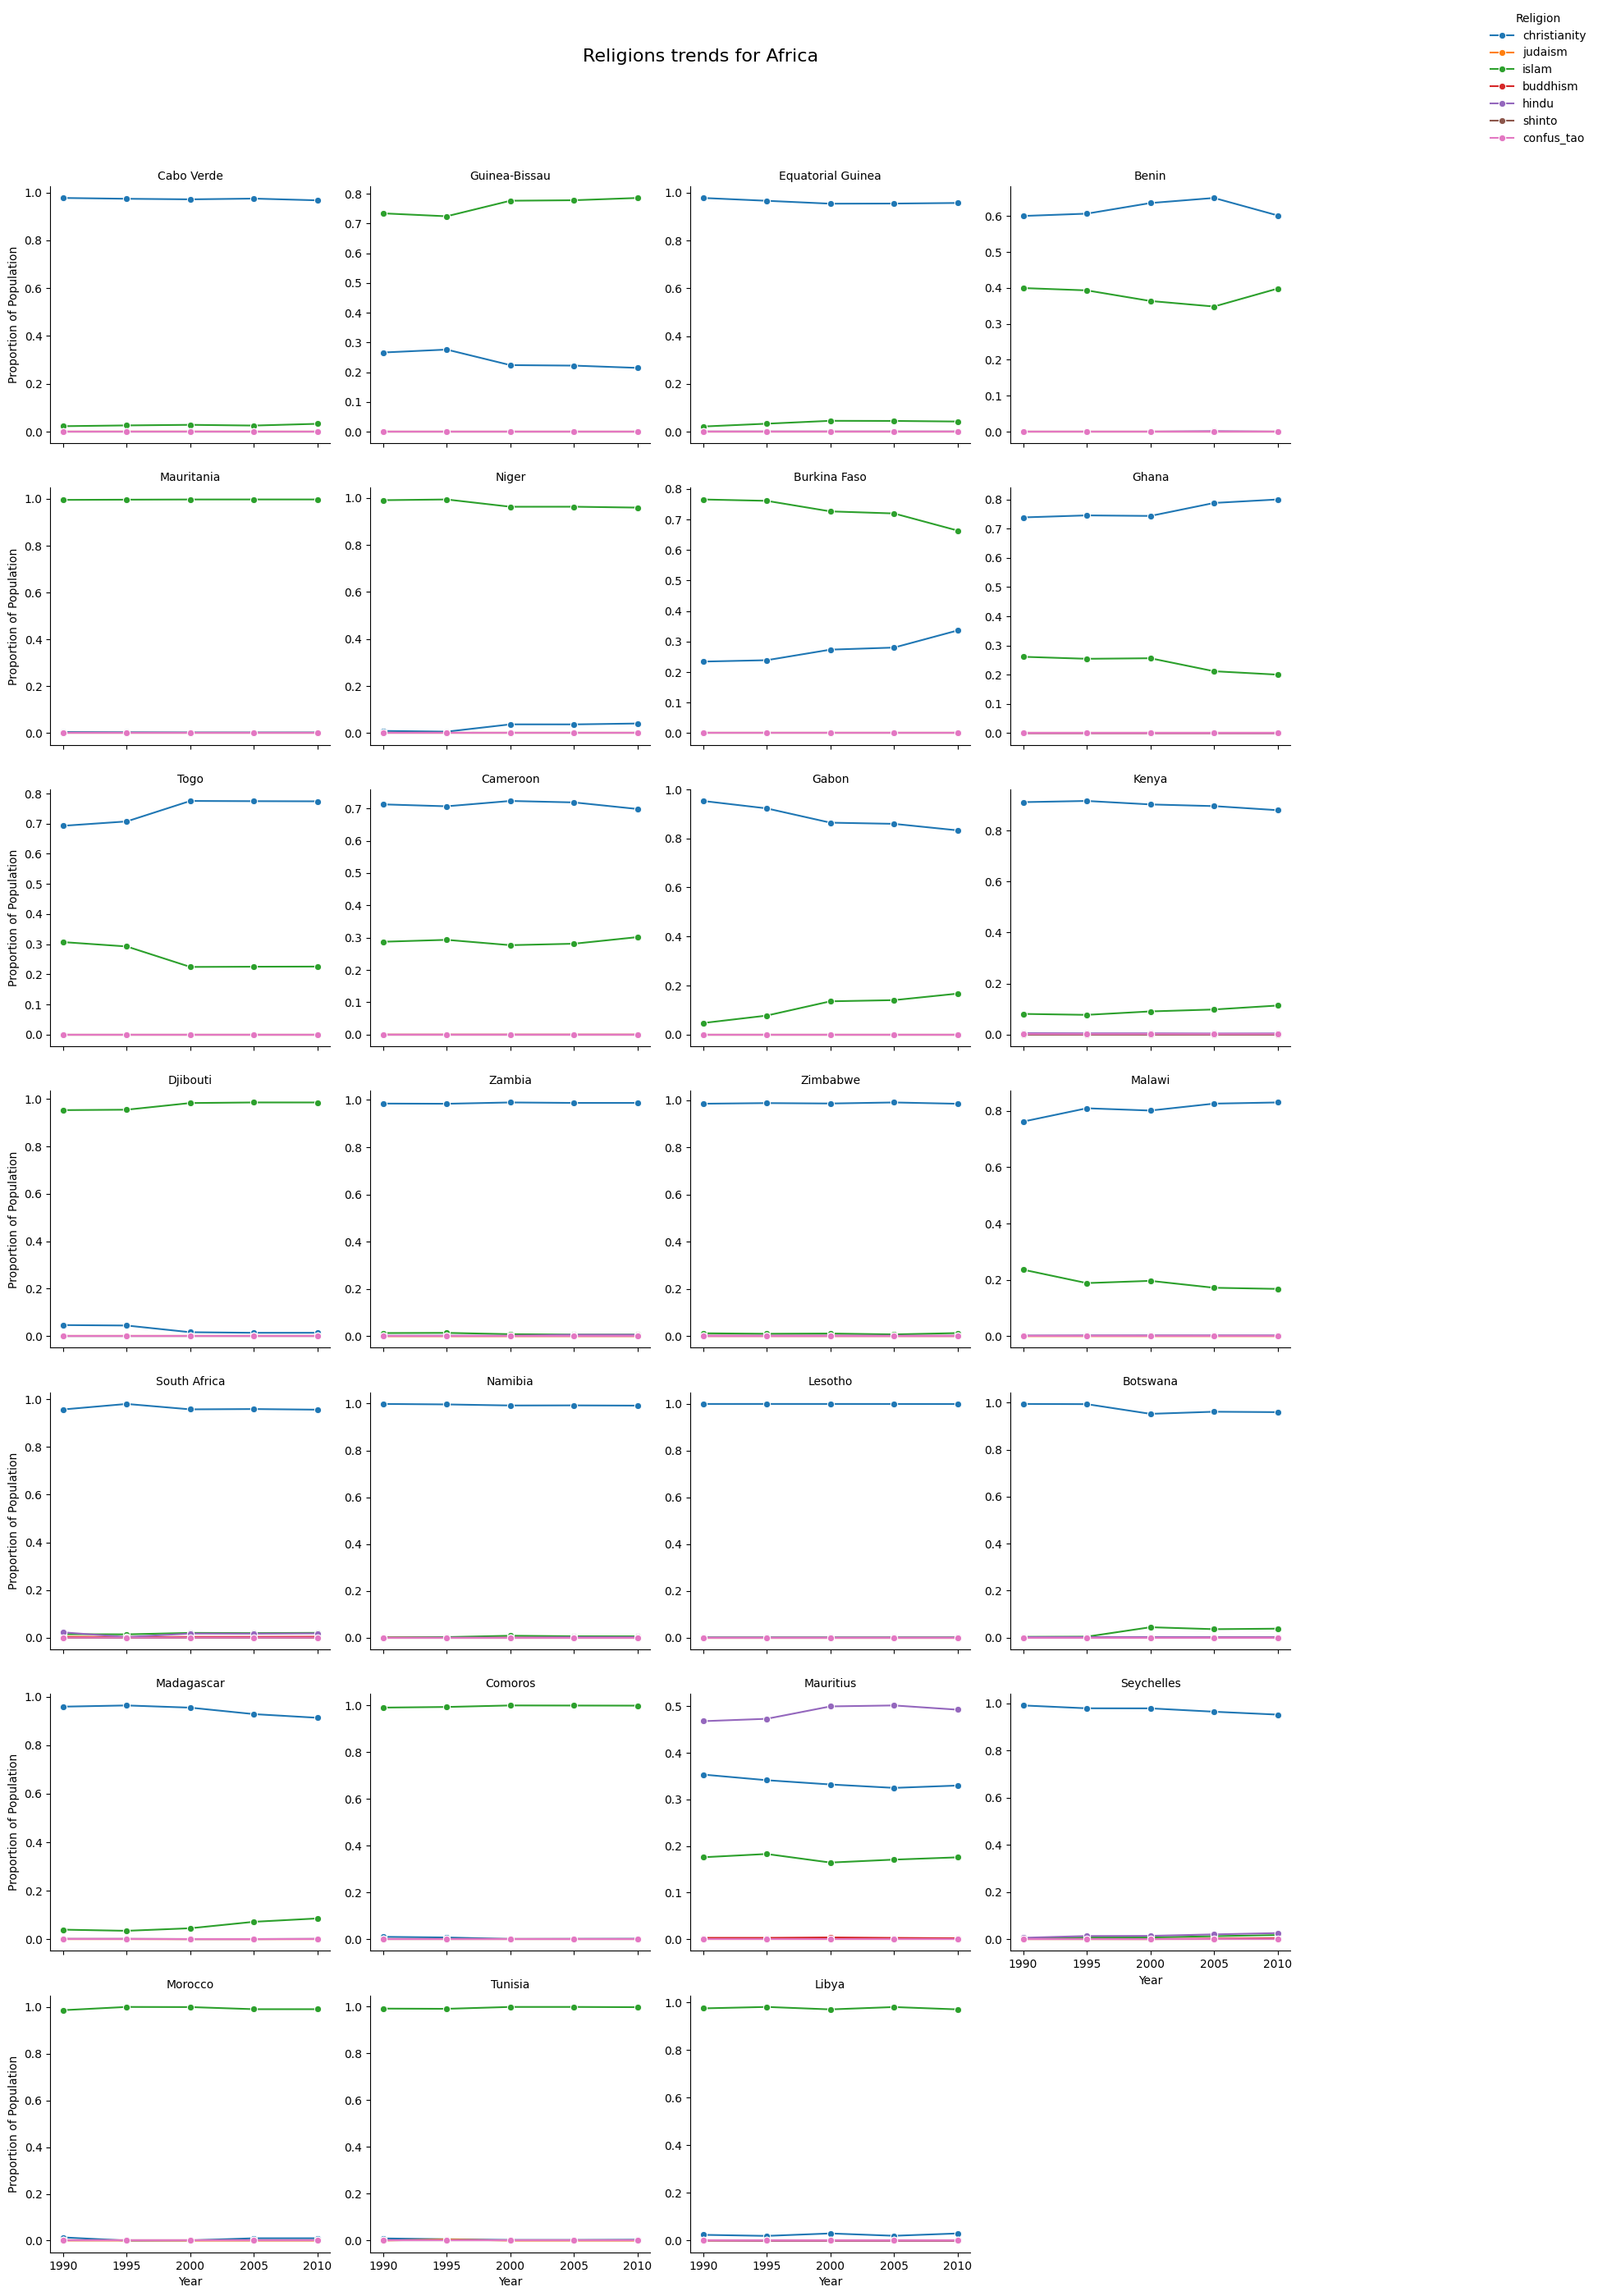

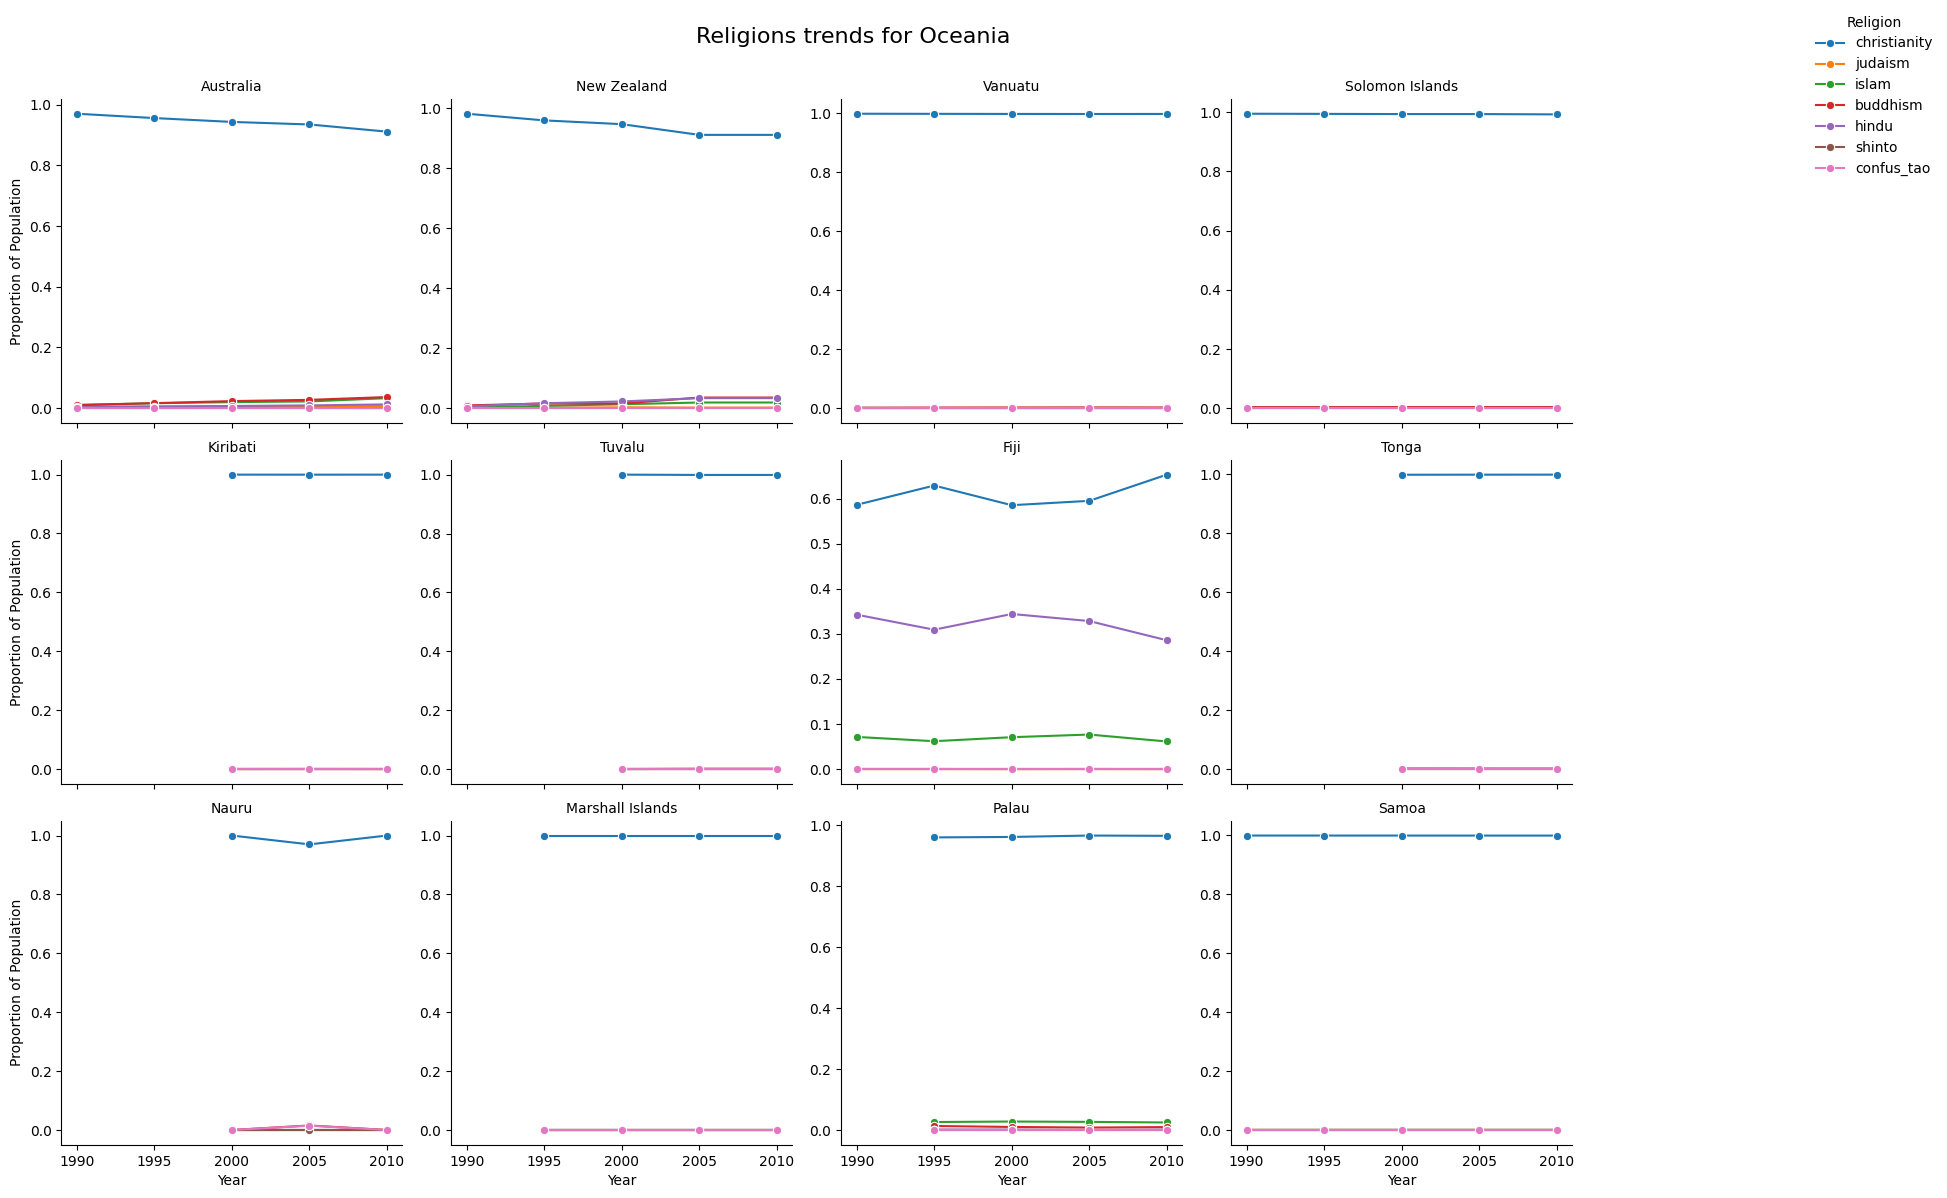

In [126]:
# Plotting facet grid region and countries
for region in df_selected_0["un_region"].unique():
    df_region = df_selected_0[df_selected_0["un_region"] == region]
    num_countries = len(no_conflict_list)
    
    if num_countries == 0:
        continue  # next

    cols = 4
    rows = (num_countries + cols - 1) // cols # (n + k - 1) // k // means division integer it is a trick
    
    g = sns.FacetGrid(
        df_region,
        col="country",
        col_wrap=cols,
        height=4,
        sharey=False
    )
    
    g.map_dataframe(
        sns.lineplot,
        x="year",
        y="prop_relig",
        hue="religion",
        marker="o"
    )
    
    g.set_axis_labels("Year", "Proportion of Population")
    g.set_titles(col_template="{col_name}")
    g.add_legend(title="Religion", bbox_to_anchor=(1.05,1), loc="upper left")
    plt.subplots_adjust(top=0.92)
    g.fig.suptitle(f"Religions trends for {region}", fontsize=16)
    plt.savefig(f"FigA.6.NoConflictReligiousTrends_country_region_facegrid_{region}.png")
    plt.show()

## Interpretation
The analysis of religious distribution and evolution in countries considered to be in conflict reveals coherent and meaningful patterns. Generally, one or two religions dominate, encompassing nearly the entire population of believers, while other religions remain very minor. Islam and Christianity are predominant in most regions, except in parts of Asia, where Confucianism, Hinduism, and Buddhism prevail. Dominant religions evolve symmetrically, suggesting a ‘communicating vessels’ effect: even when total population increases, the relative proportions of each religious group remain stable.

For a more detailed analysis, it is useful to focus on countries with large internal variation. In Europe, non-conflict countries are very stable, except for Albania, Serbia, and North Macedonia, which may reflect unaccurate data but suggest in contrast relation between conflit and religious variations. In South America, trends are mostly stable, except in Guyana and Suriname, where symmetric shifts occur—Christianity decreases and Hinduism increases in Suriname, with the opposite pattern in Guyana—suggesting cross-border dynamics. Symmetric patterns are also observed in North Korea, South Korea, and Vietnam, with overlapping but different religious groups, implying additional underlying factors.

These observations remain preliminary and show that, despite categorization as conflict or non-conflict countries, similar trends appear across both. They open the way to exploring the role of socio-economic factors, such as GDP and HDI, in shaping religious populations and the relative proportions of dominant religions.

### Summary
Religious patterns are coherent and meaningful, even in conflict-affected countries.

One or two religions dominate nearly the entire population; other religions remain very minor.

Islam and Christianity are predominant, except in parts of Asia (Hinduism, Buddhism, Confucianism).

Dominant religions evolve symmetrically → relative proportions remain stable despite total population growth.

Countries with large variations deserve focused analysis (Europe: Albania, Serbia, North Macedonia; South America: Guyana, Suriname; Asia: North Korea, South Korea, Vietnam).

Similar patterns are observed in conflict and non-conflict countries → categorization is relative.

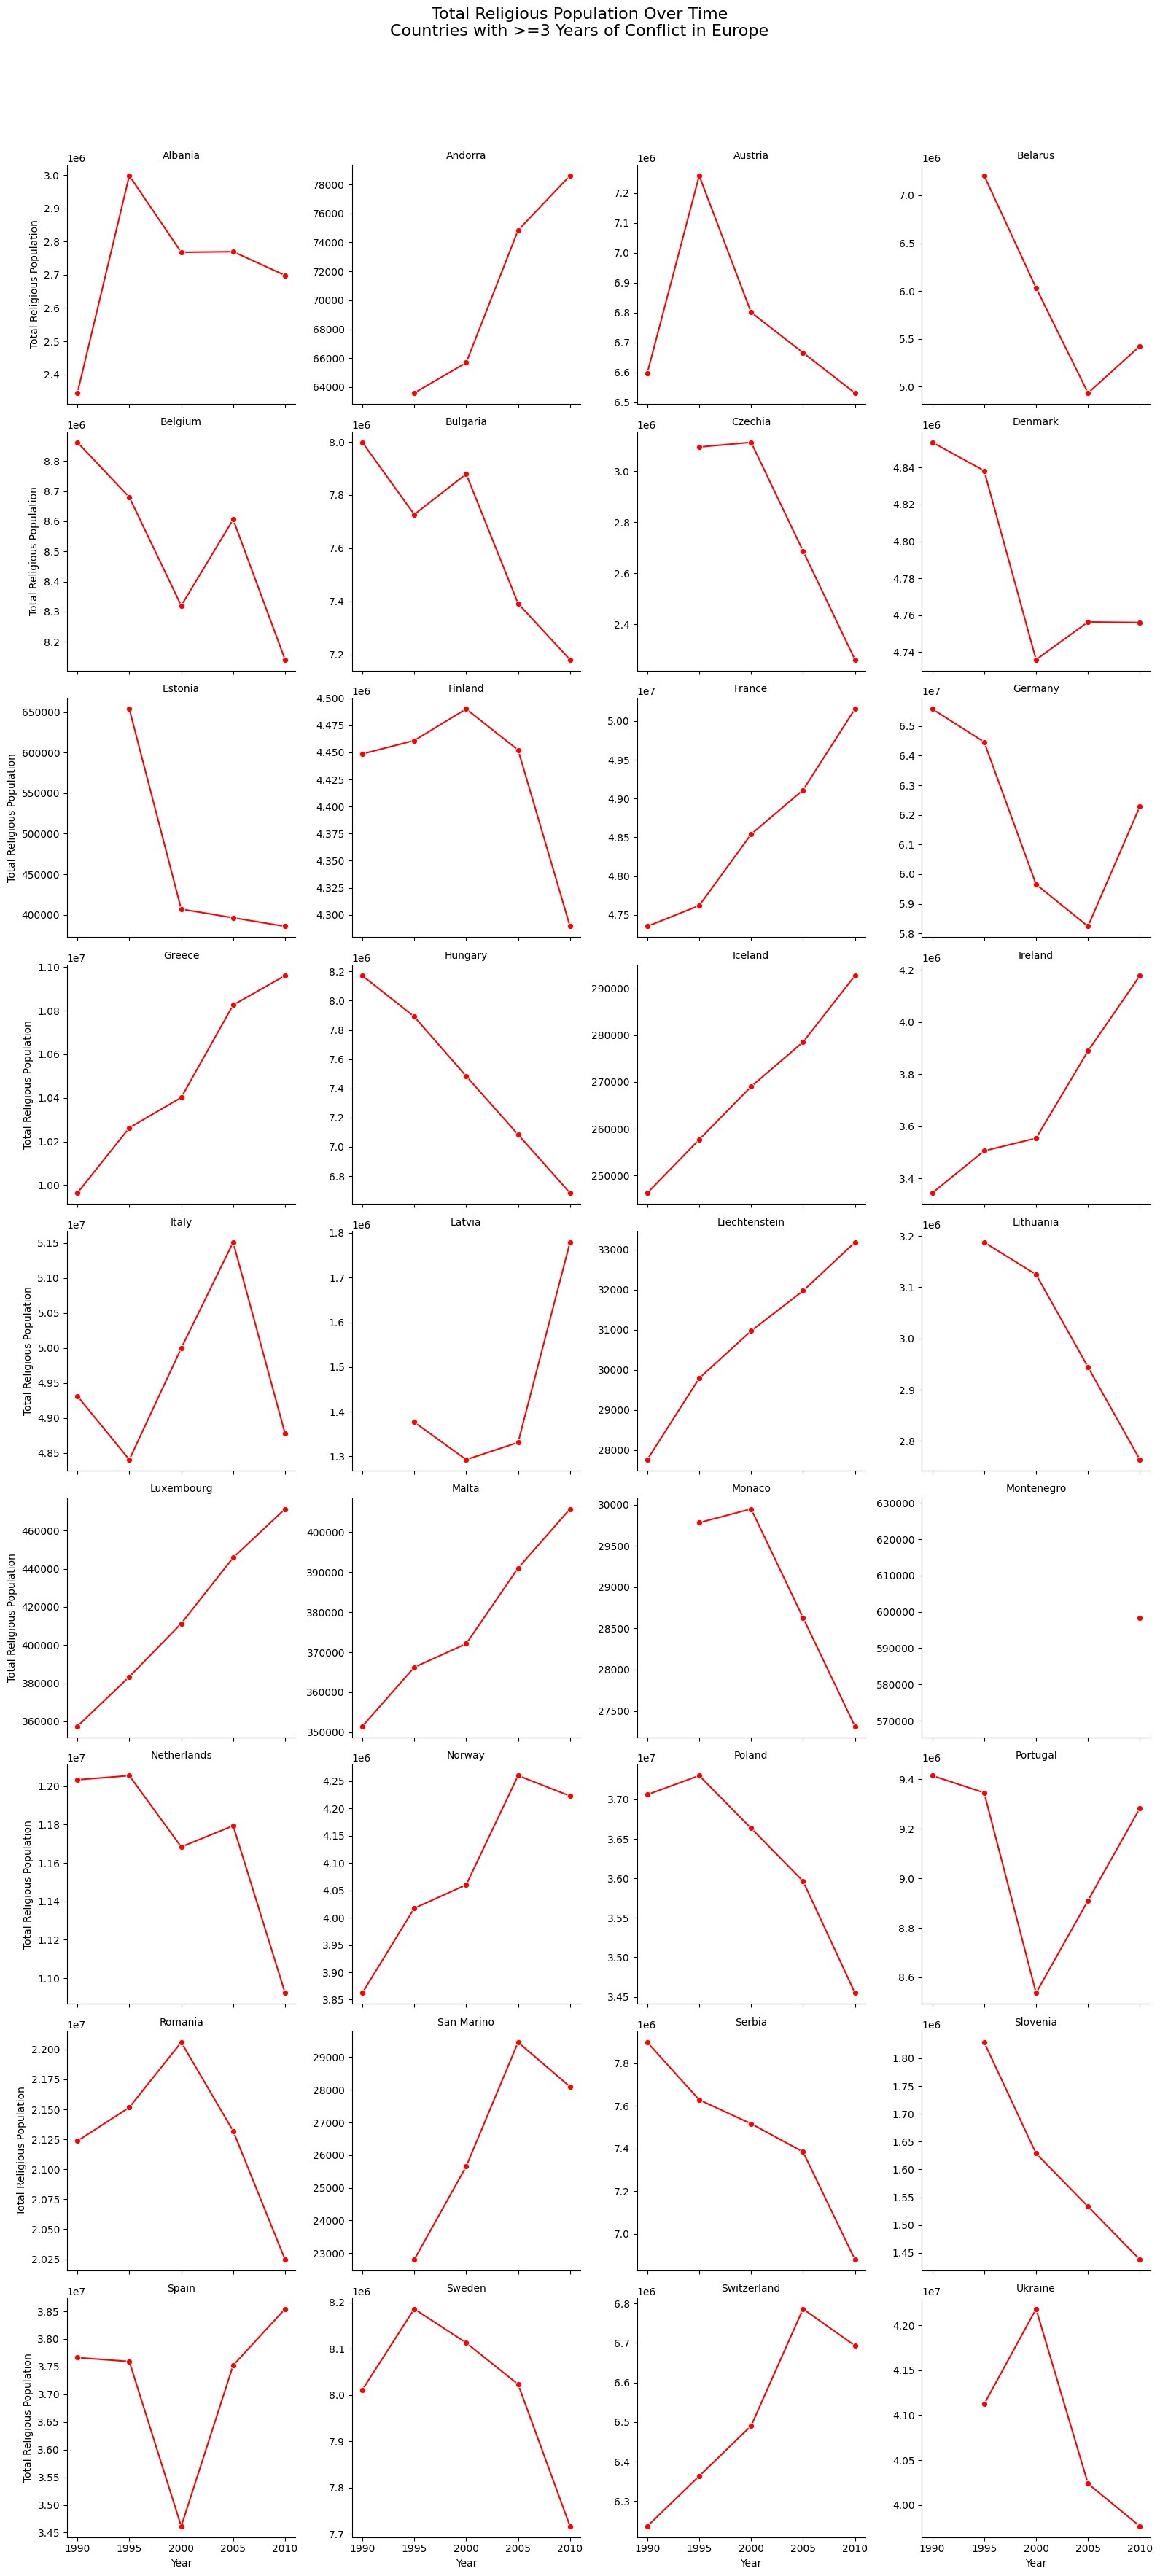

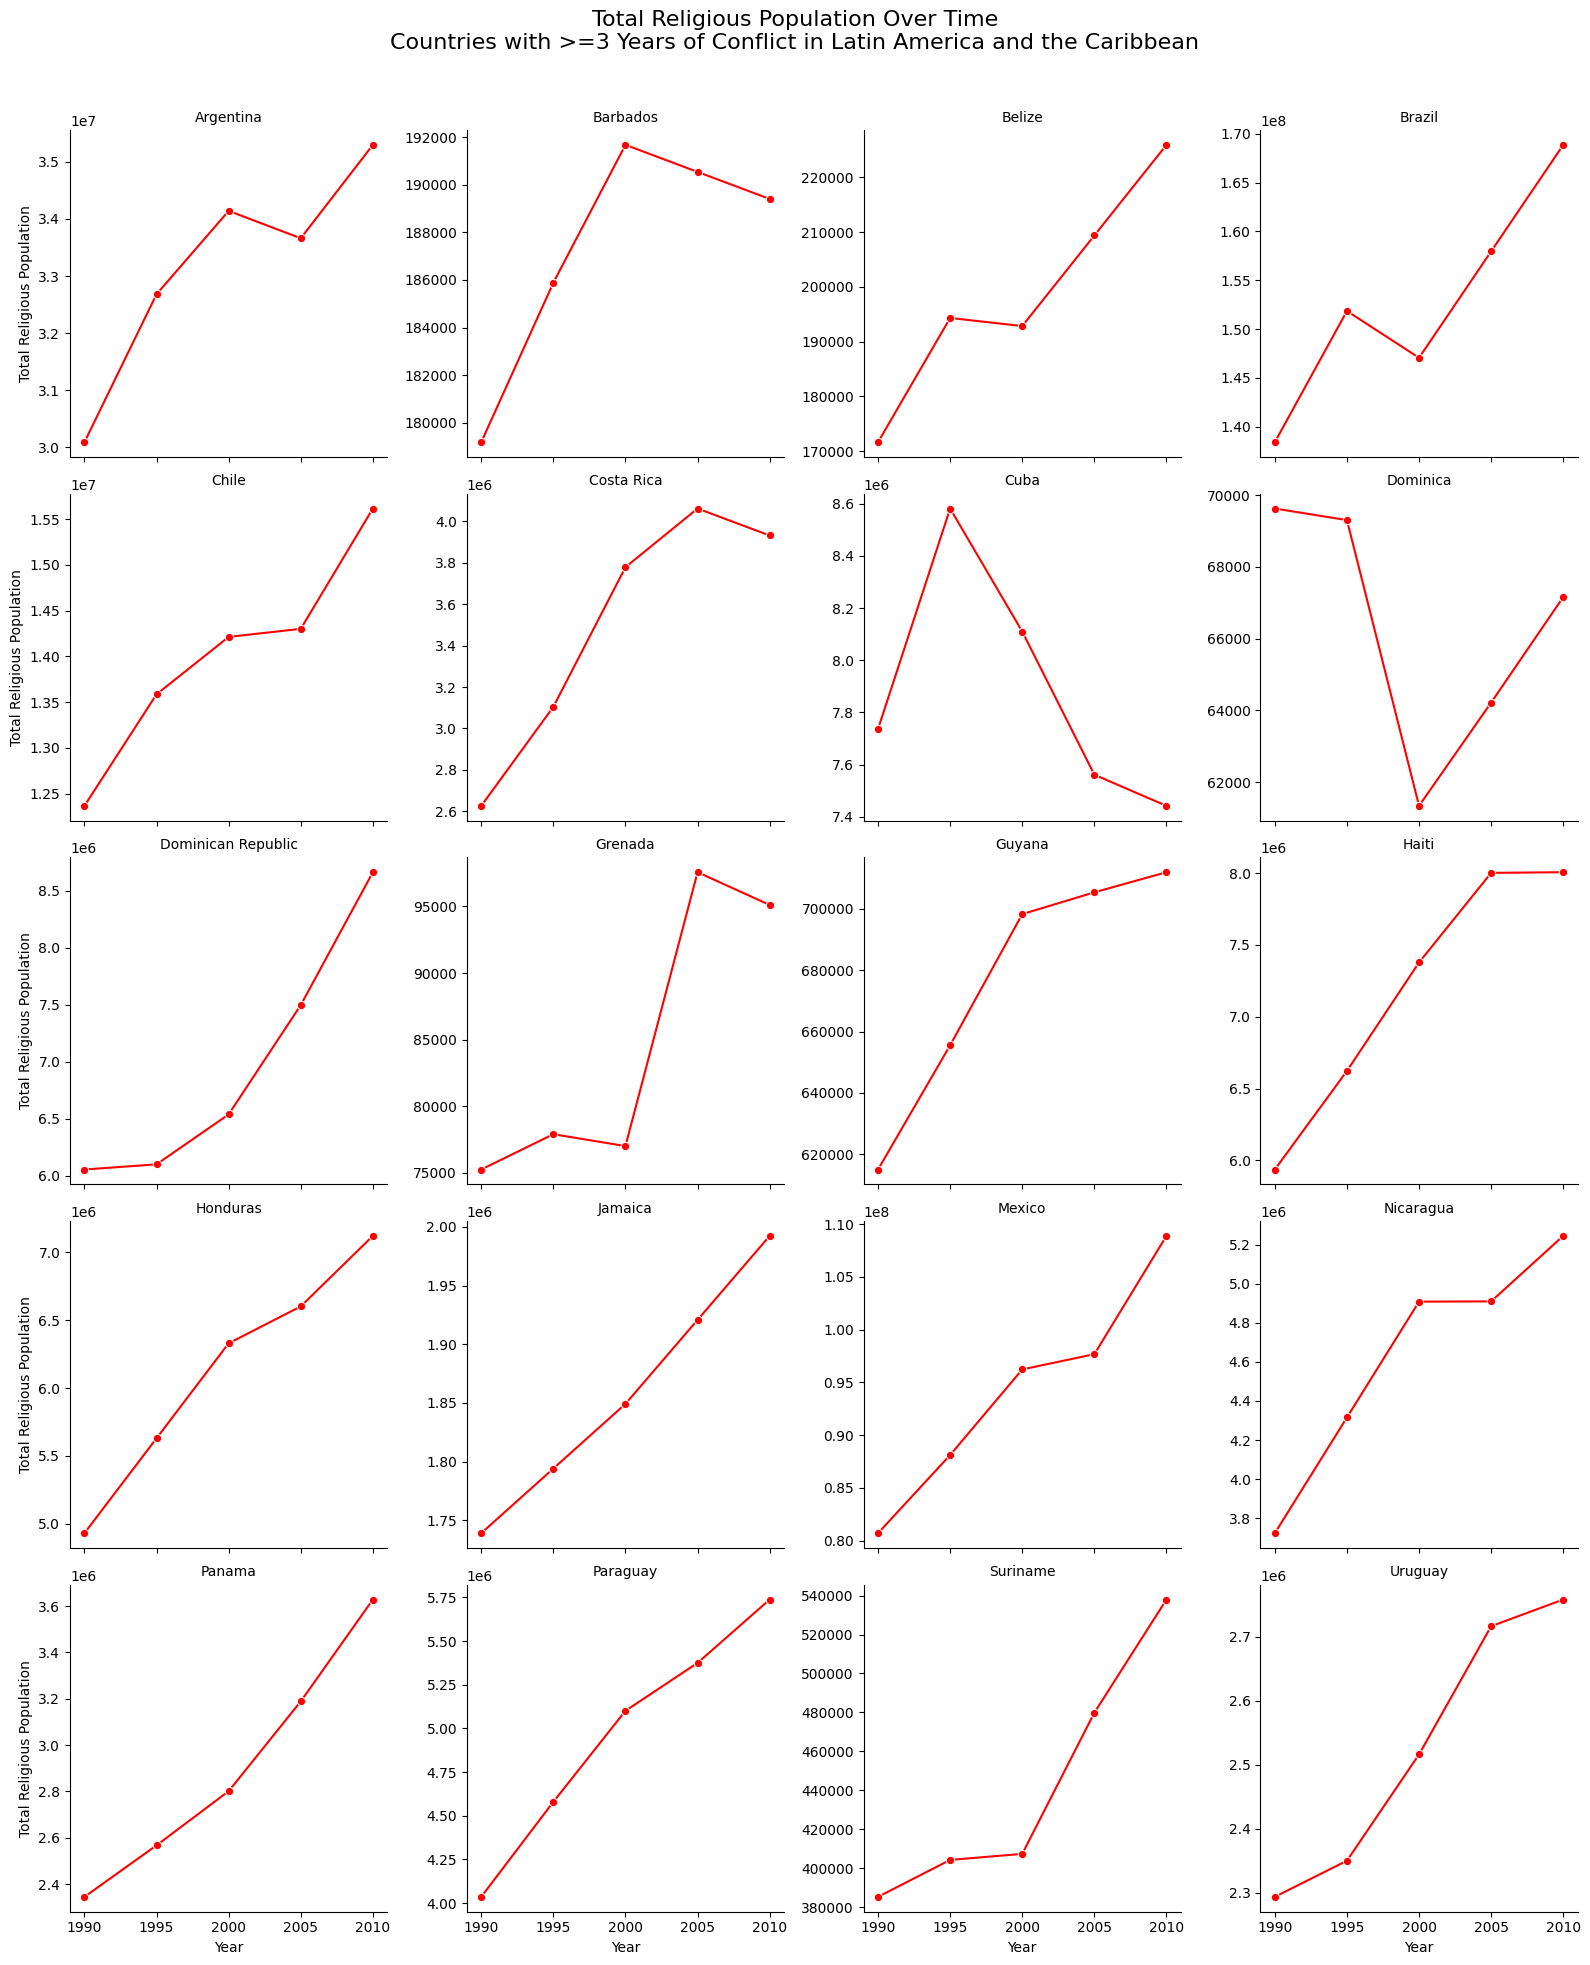

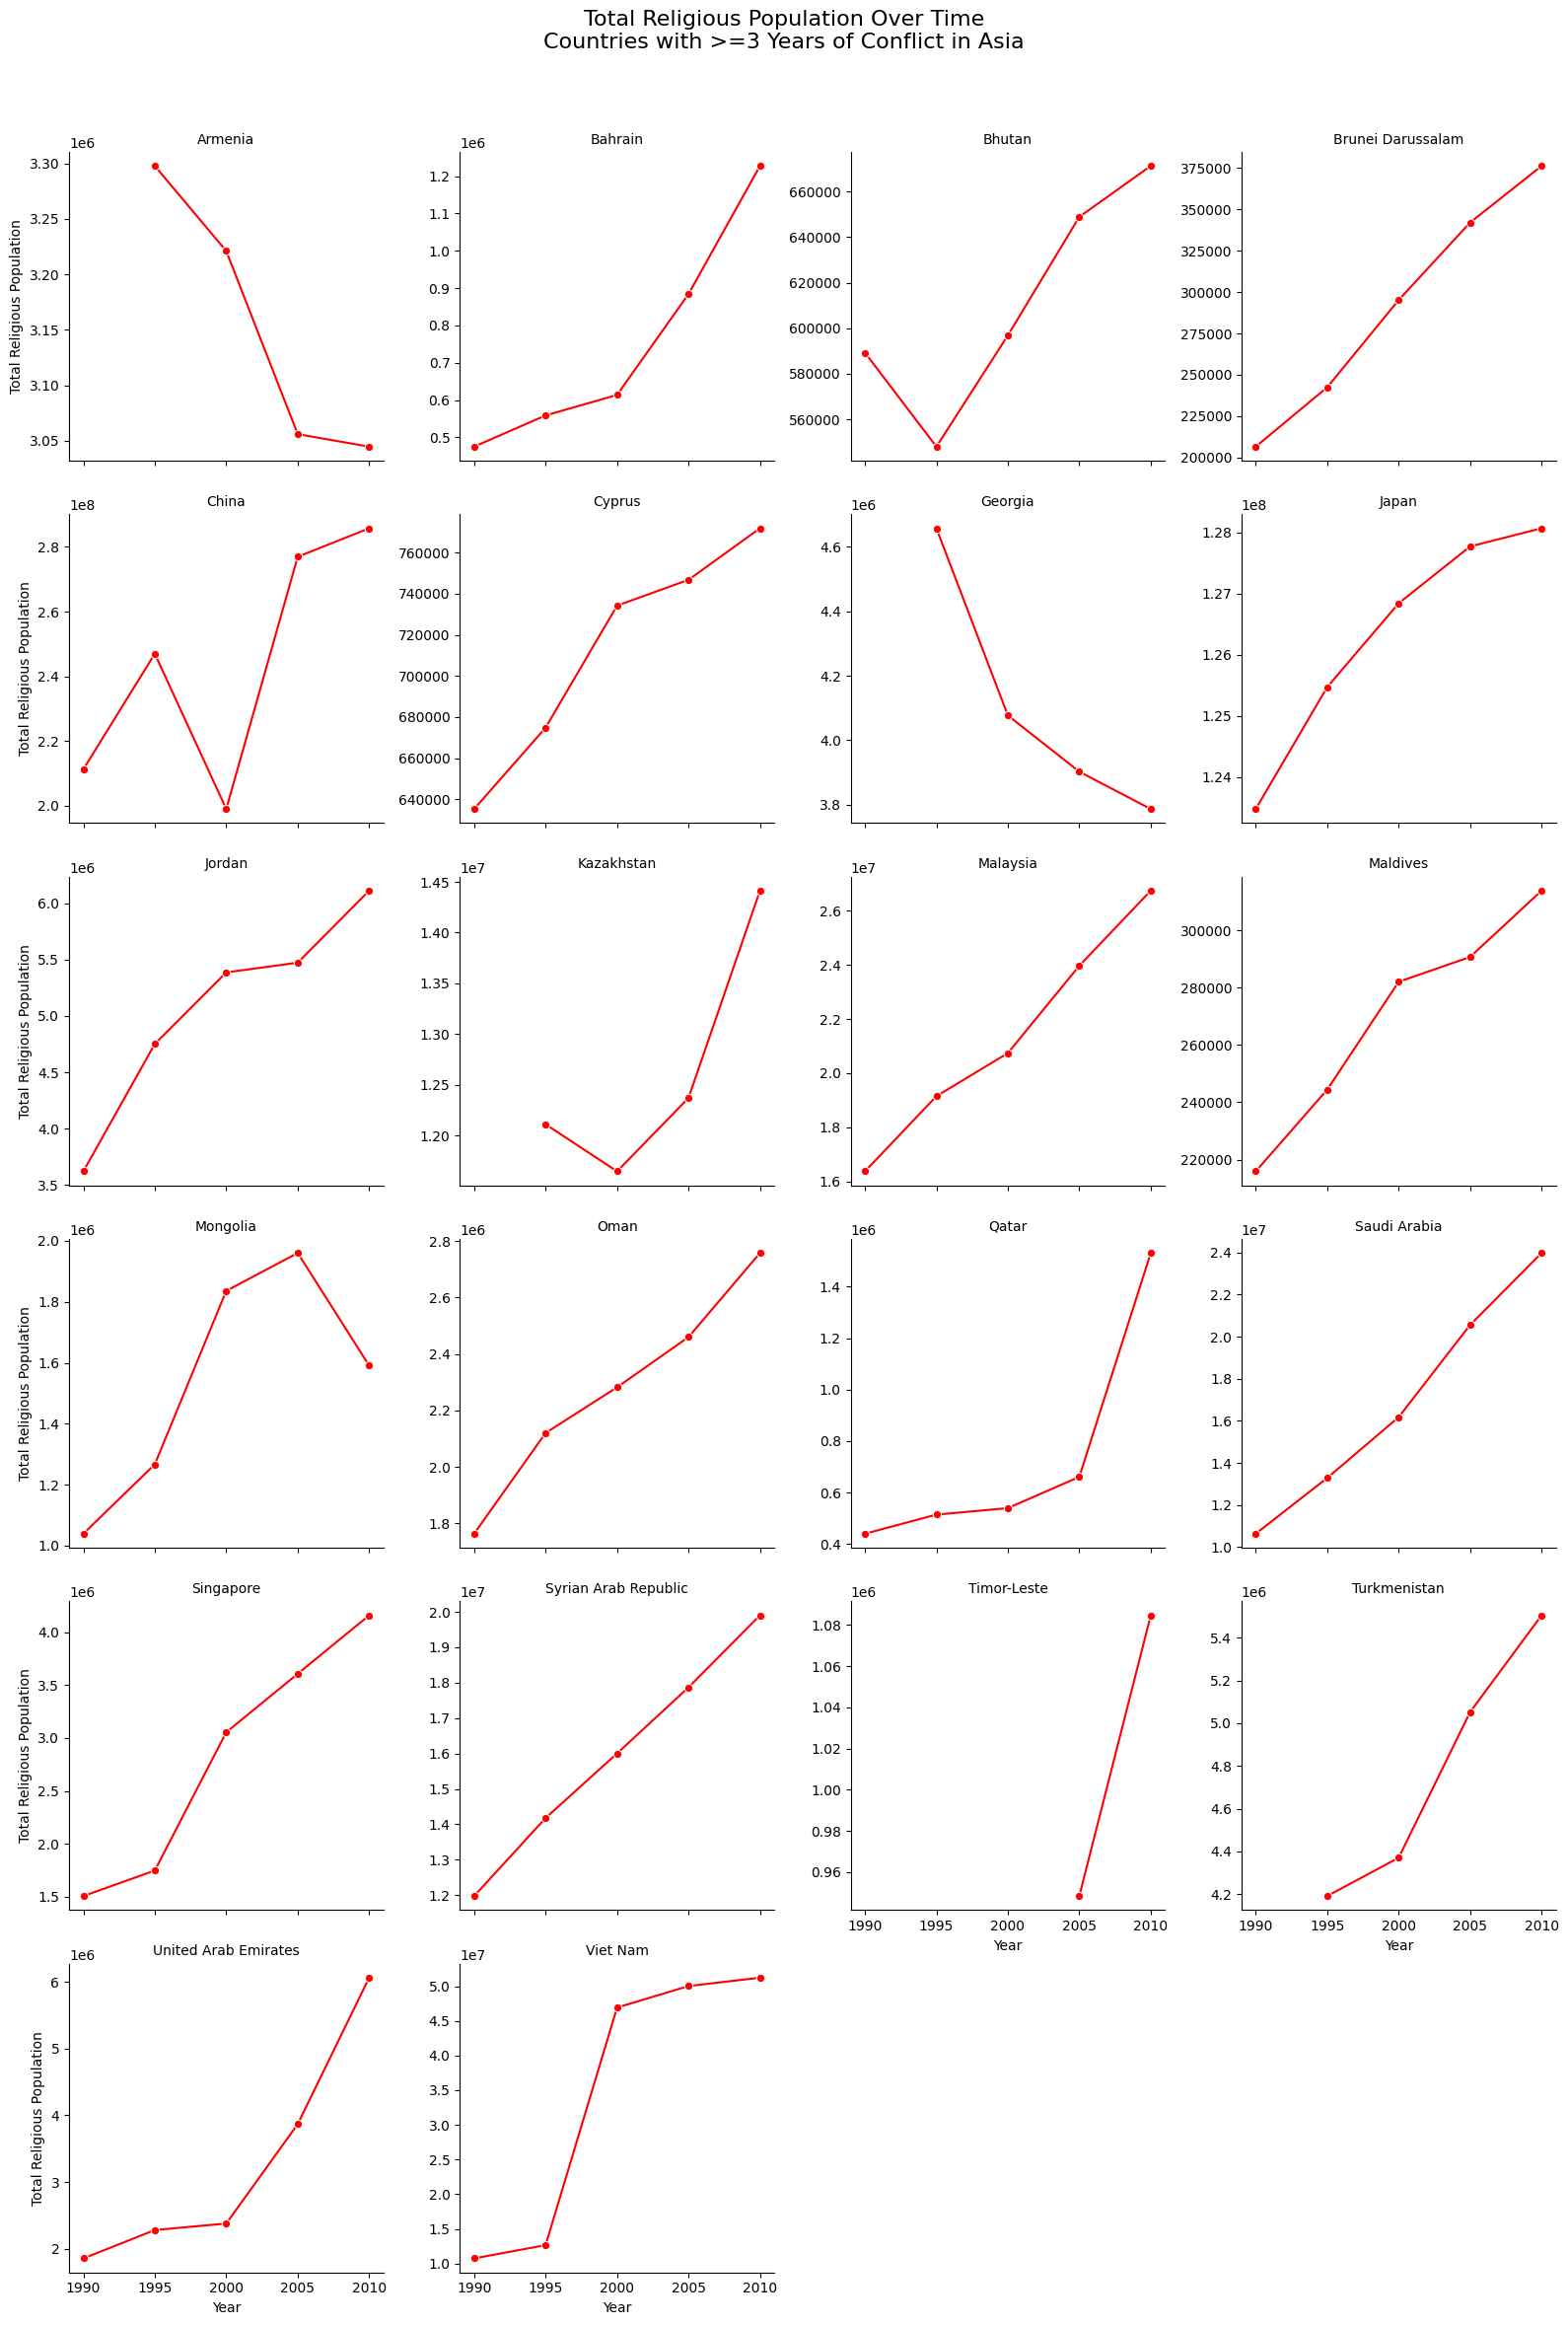

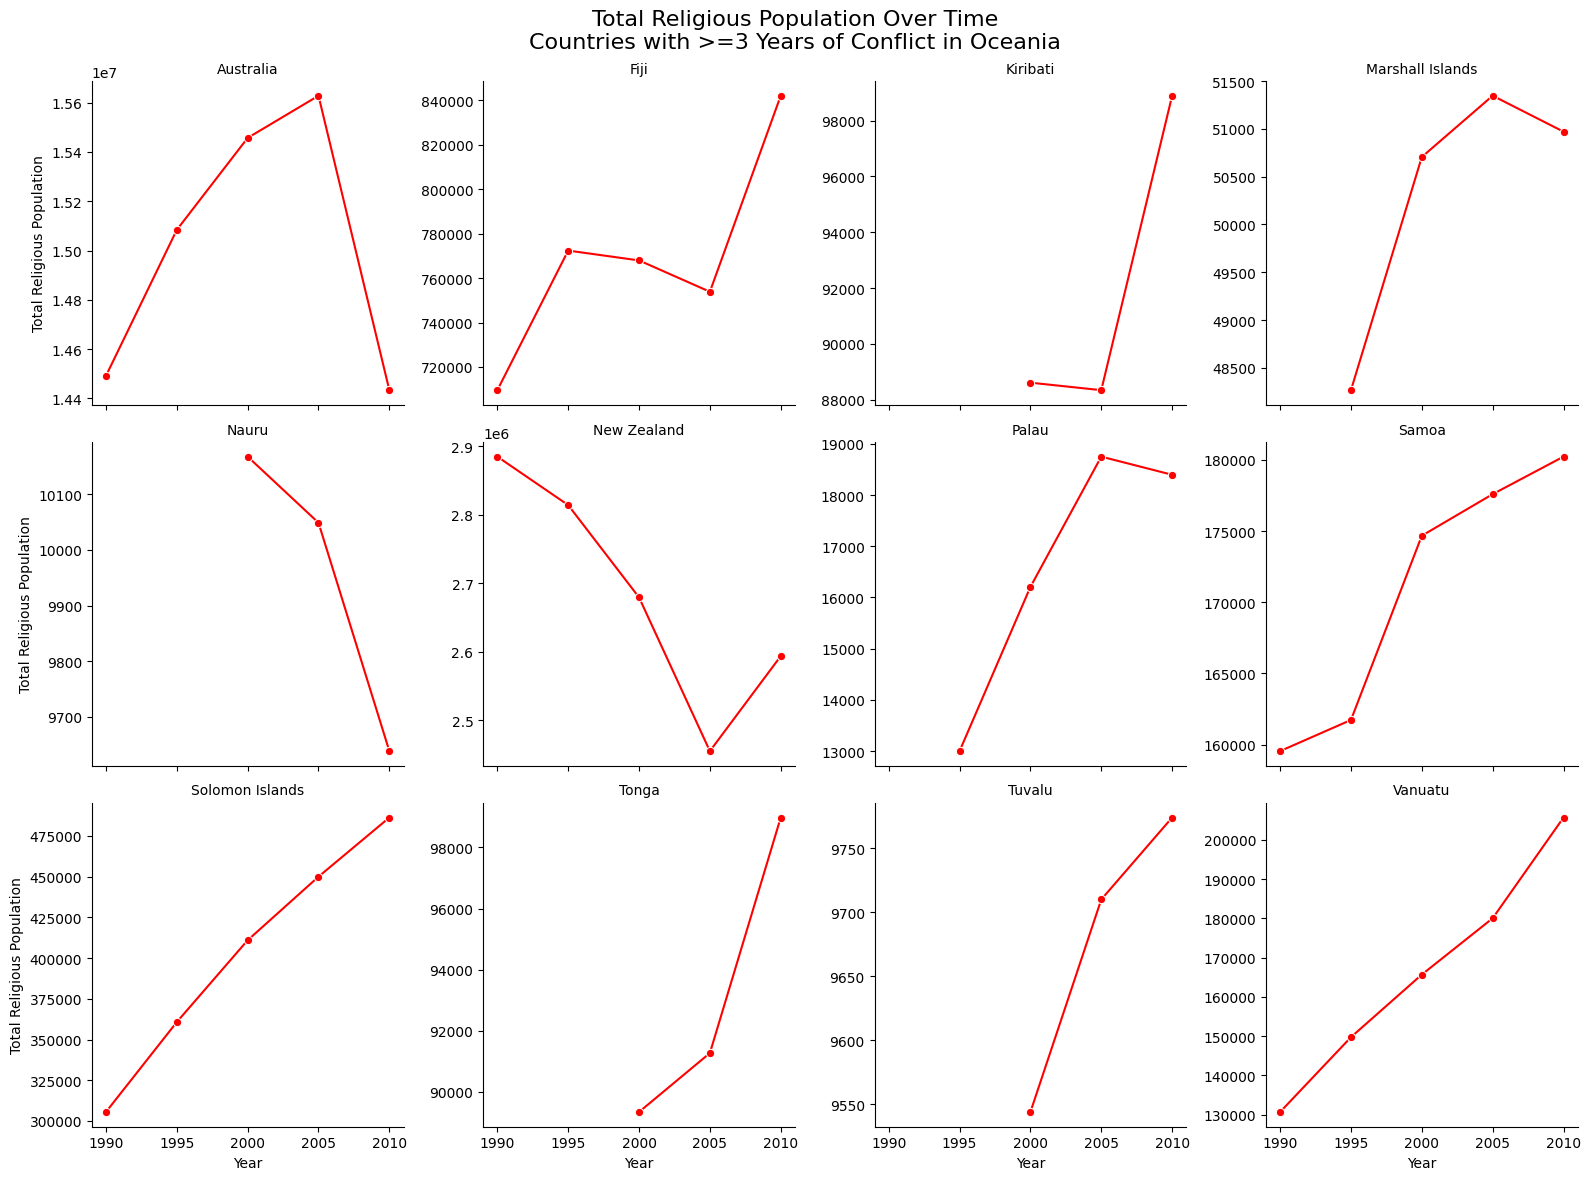

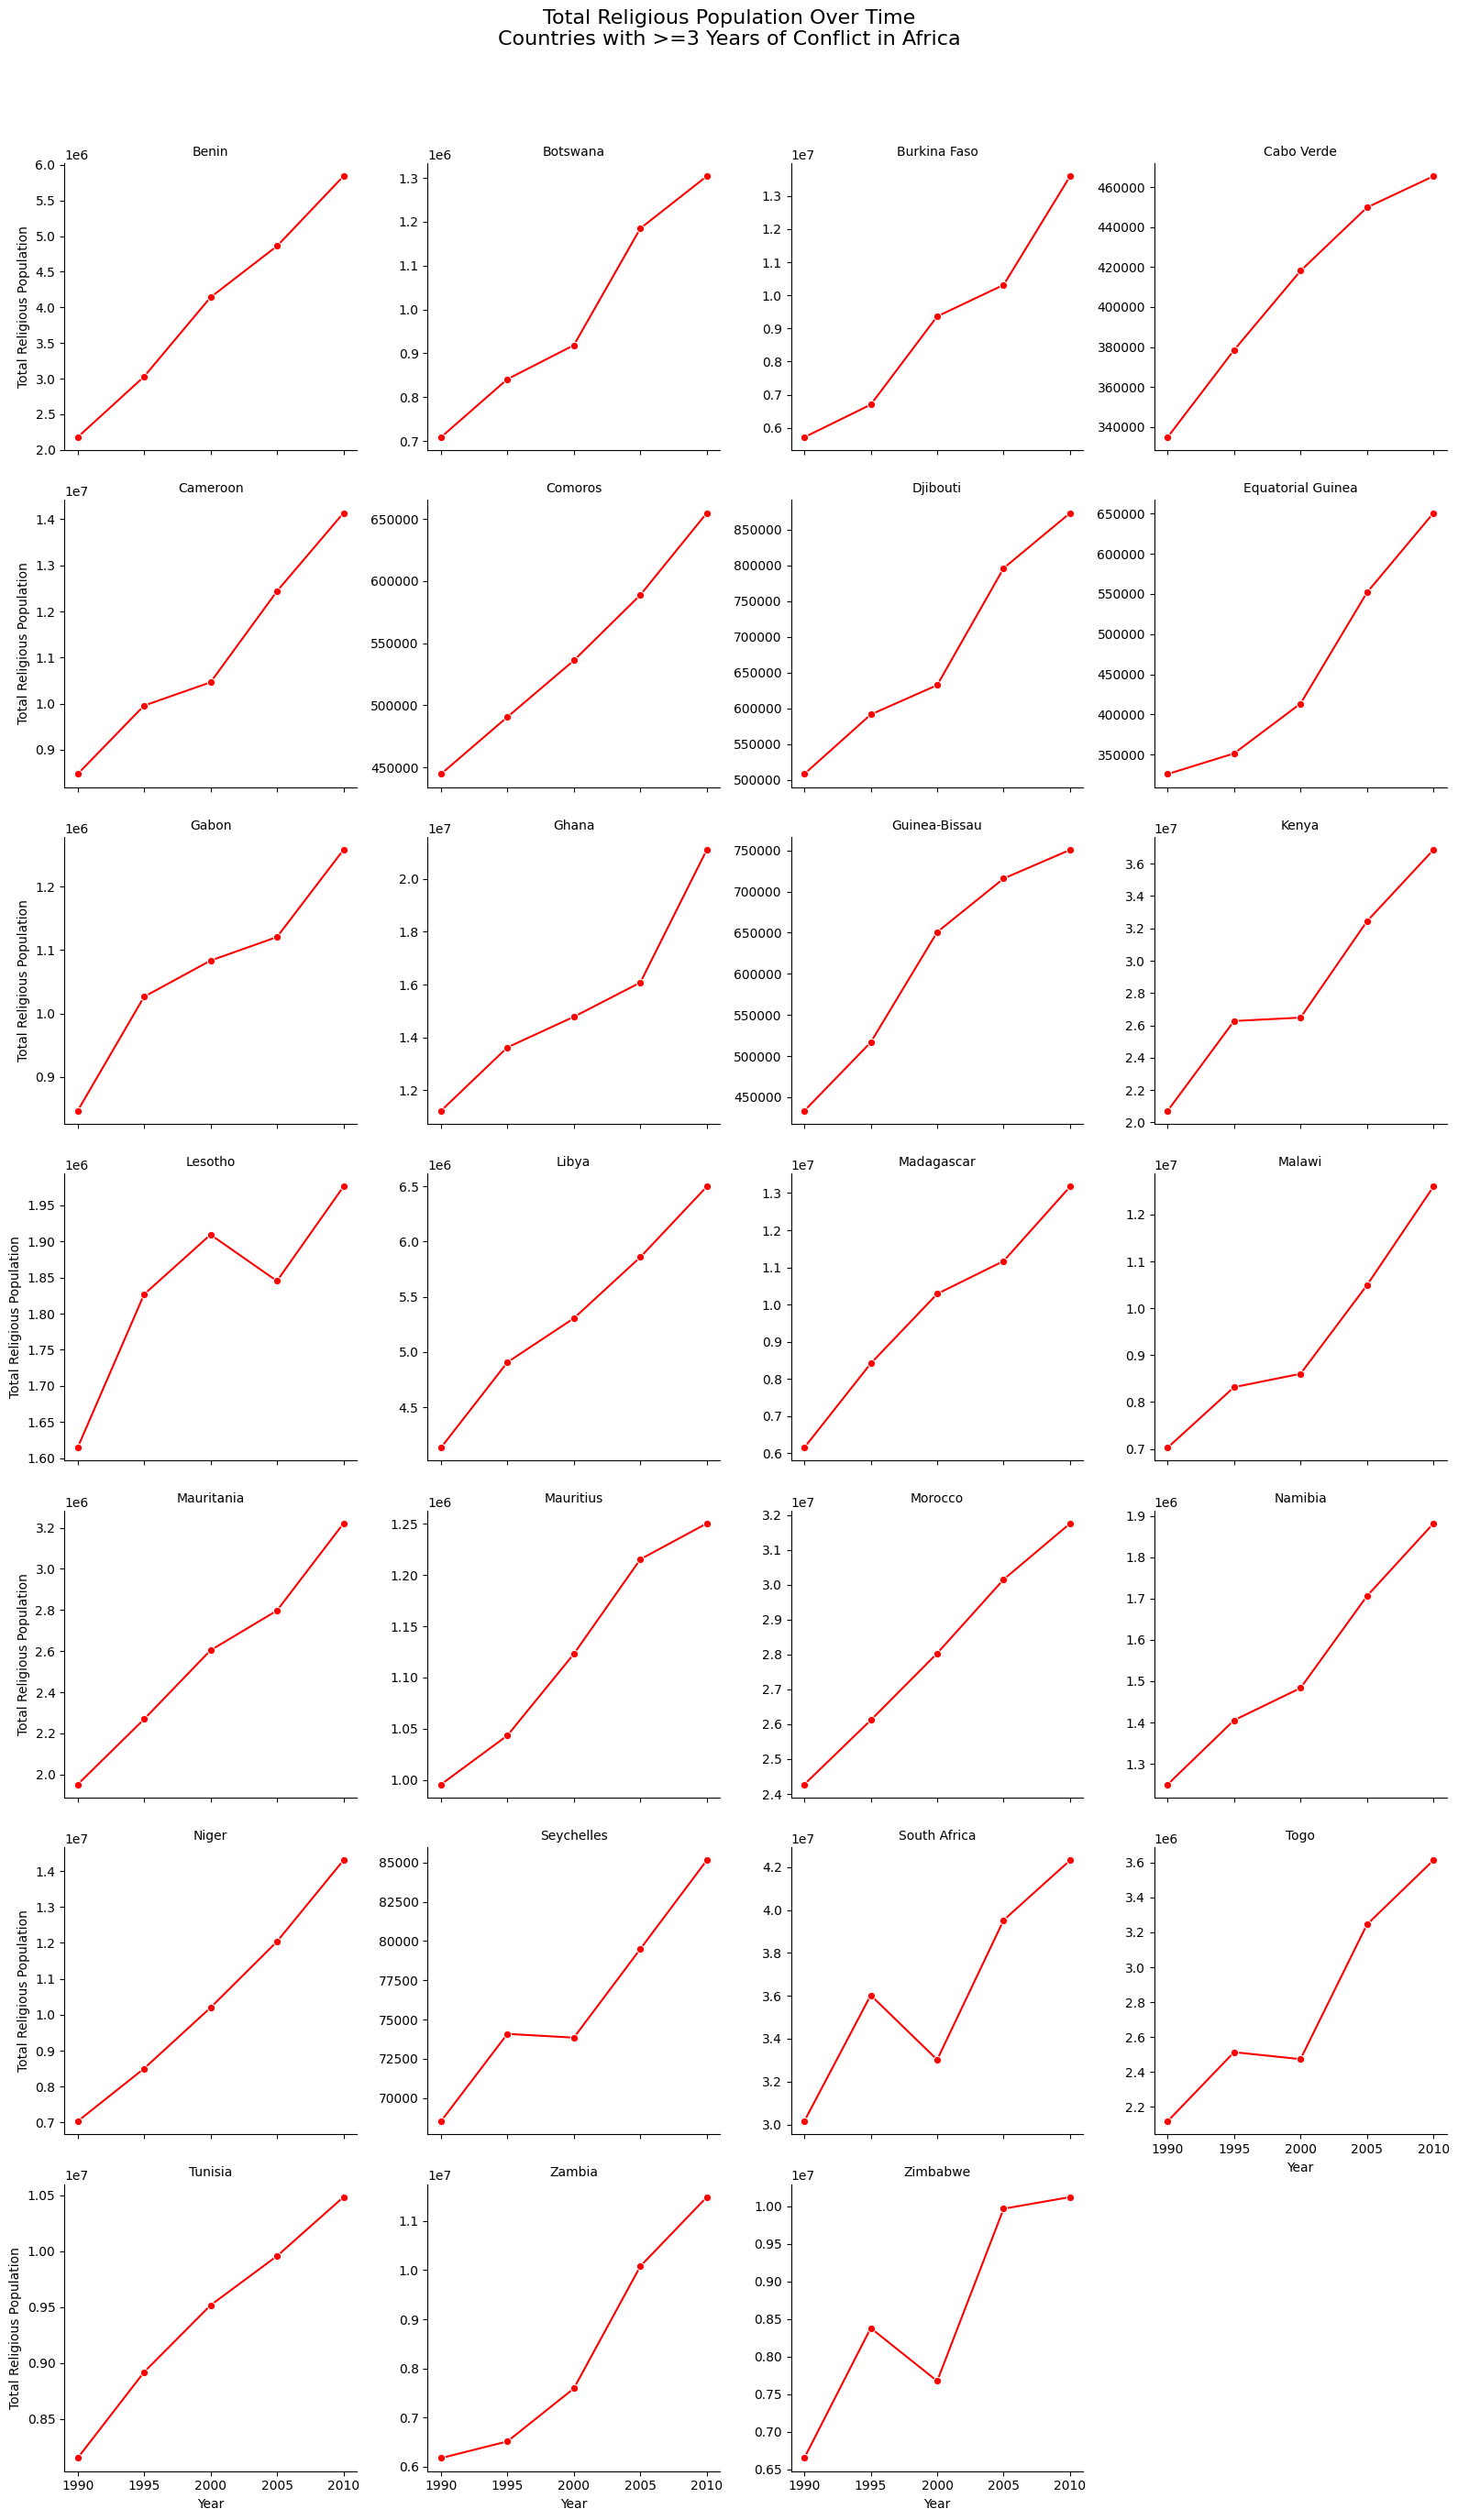

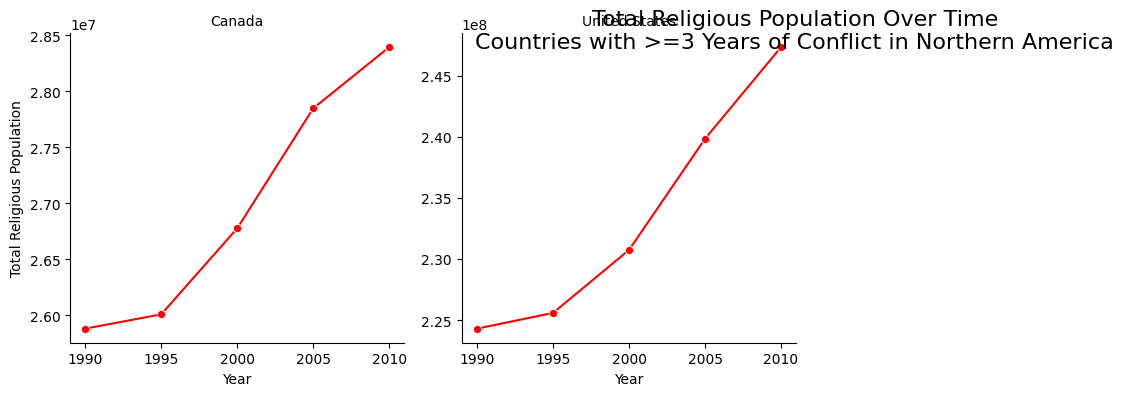

In [127]:
# Do the countries in conflict experience an increanse of religious population overall? YES


# Select the initial data
df_conflict_sum = long_df[long_df["country"].isin(country_conflict_list)]

# Sum religious population per country, year, and region
df_conflict_sum = (
    df_conflict_no
    .groupby(["country", "year", "un_region"])["relig_pop"]
    .sum()
    .reset_index(name="total_pop")
)

# Loop over regions
for region in df_conflict_sum["un_region"].unique():
    df_region = df_conflict_sum[df_conflict_sum["un_region"] == region]
    num_countries = df_region["country"].nunique()
    
    if num_countries == 0:
        continue  # skip empty region

    cols = 4
    rows = (num_countries + cols - 1) // cols  # integer division to get number of rows

    # Create FacetGrid
    g = sns.FacetGrid(
        df_region,
        col="country",
        col_wrap=cols,
        height=4,
        sharey=False
    )
    
    # Map lineplot onto the grid
    g.map_dataframe(
        sns.lineplot,
        x="year",
        y="total_pop",
        marker="o",
        color="red"
    )
    
    # Set labels and titles
    g.set_axis_labels("Year", "Total Religious Population")
    g.set_titles(col_template="{col_name}")
    g.fig.suptitle(
        f"Total Religious Population Over Time\nCountries with >=3 Years of Conflict in {region}",
        fontsize=16
    )
    
    plt.subplots_adjust(top=0.92)
    plt.savefig(f"FigA.7.1_ReligiousPopTot_country_region_{region}.png")
    plt.show()

## Interpretation
### note: this should be before the pattern among religions per country per region
Looking at variations in the total religious population for countries experiencing conflict for three or more years out of five, we observe a systematic increase in religious population. At this stage, this may also reflect general population growth, but preliminary results suggest that religion grows in absolute numbers in conflict-affected countries. These observations should be interpreted cautiously, as other factors have not yet been analyzed and the conflict datasets contain known biases. Notable decreases are observed in some countries: Russia in 1995 (possibly due to post-Berlin Wall political factors), Somalia in 2005 (likely due to missing data), and localized decreases in Myanmar and Sri Lanka.

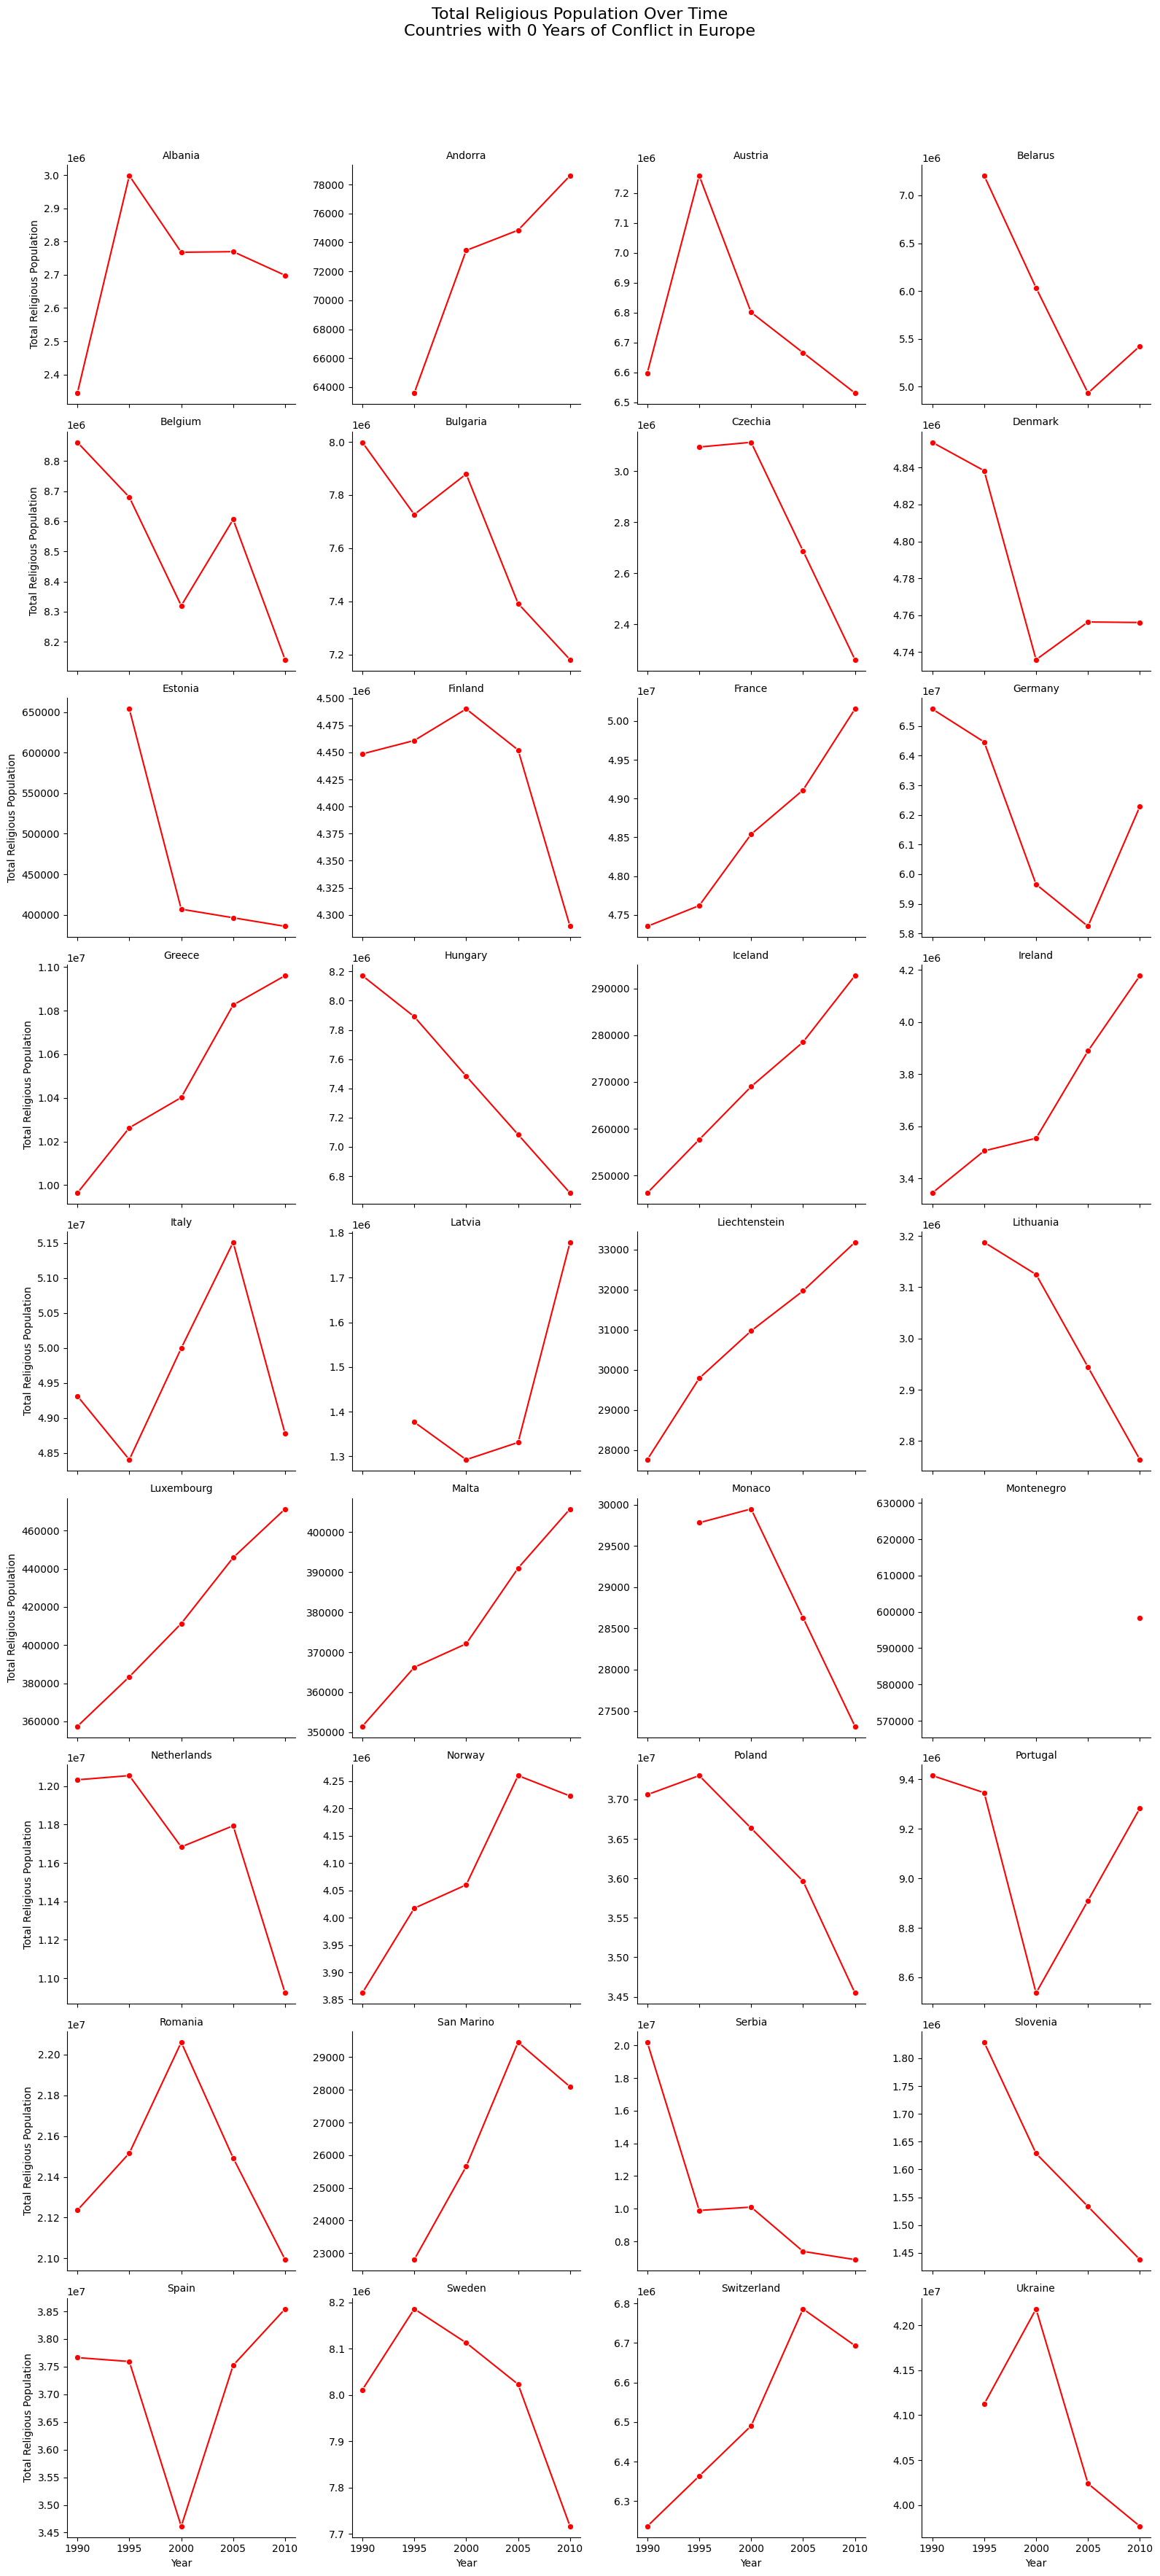

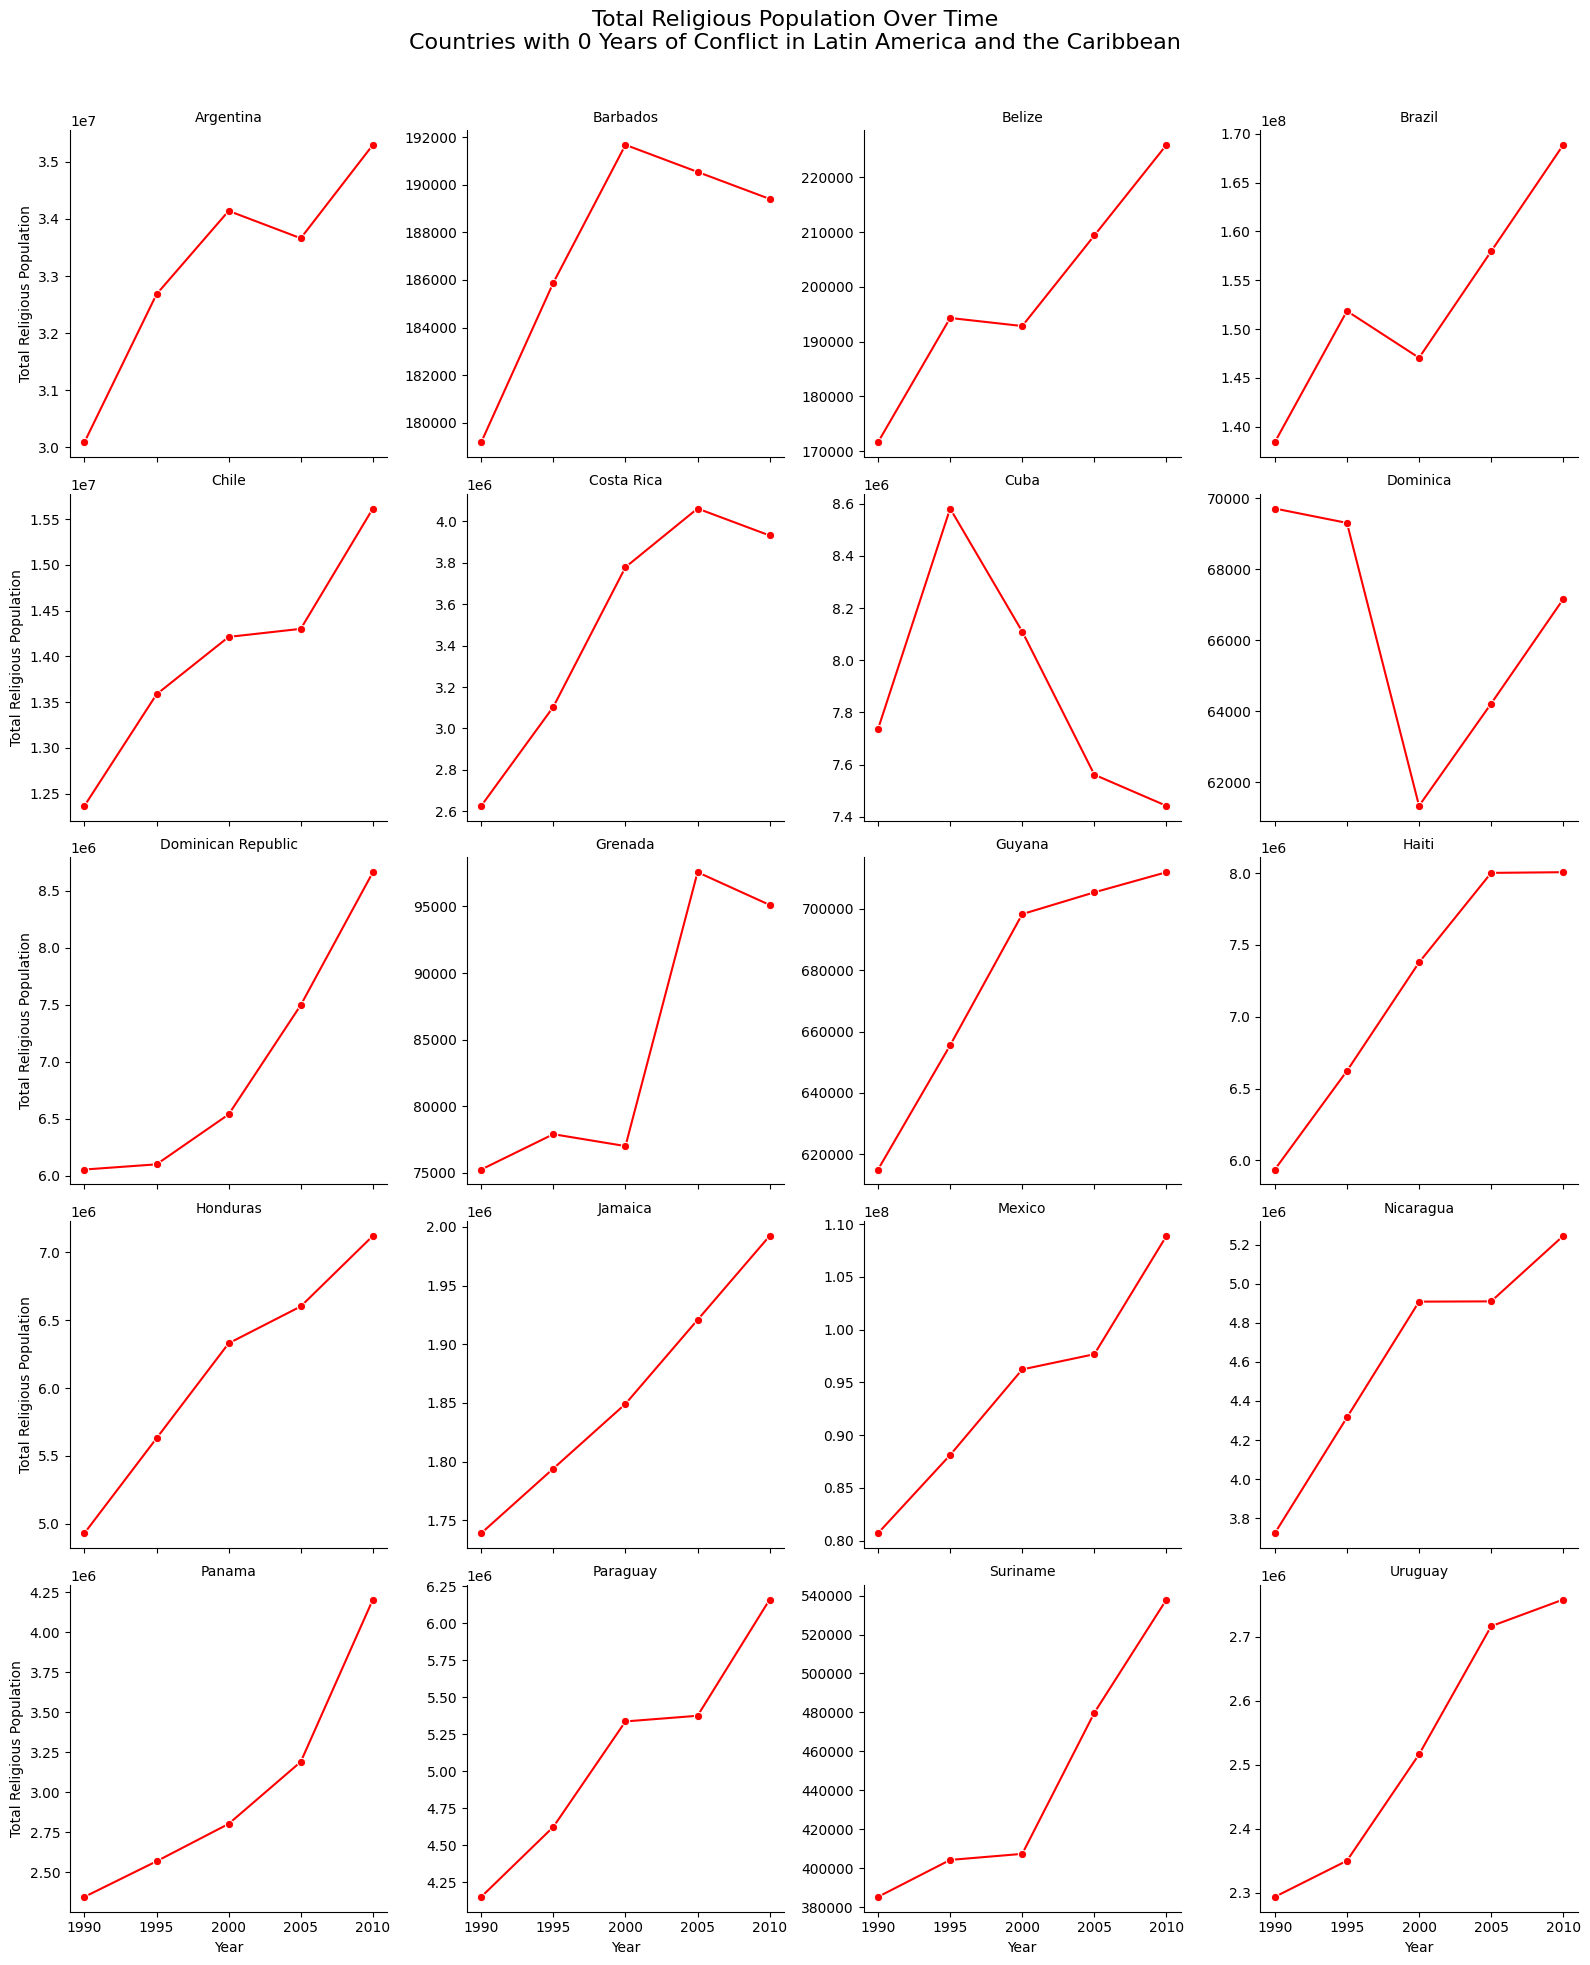

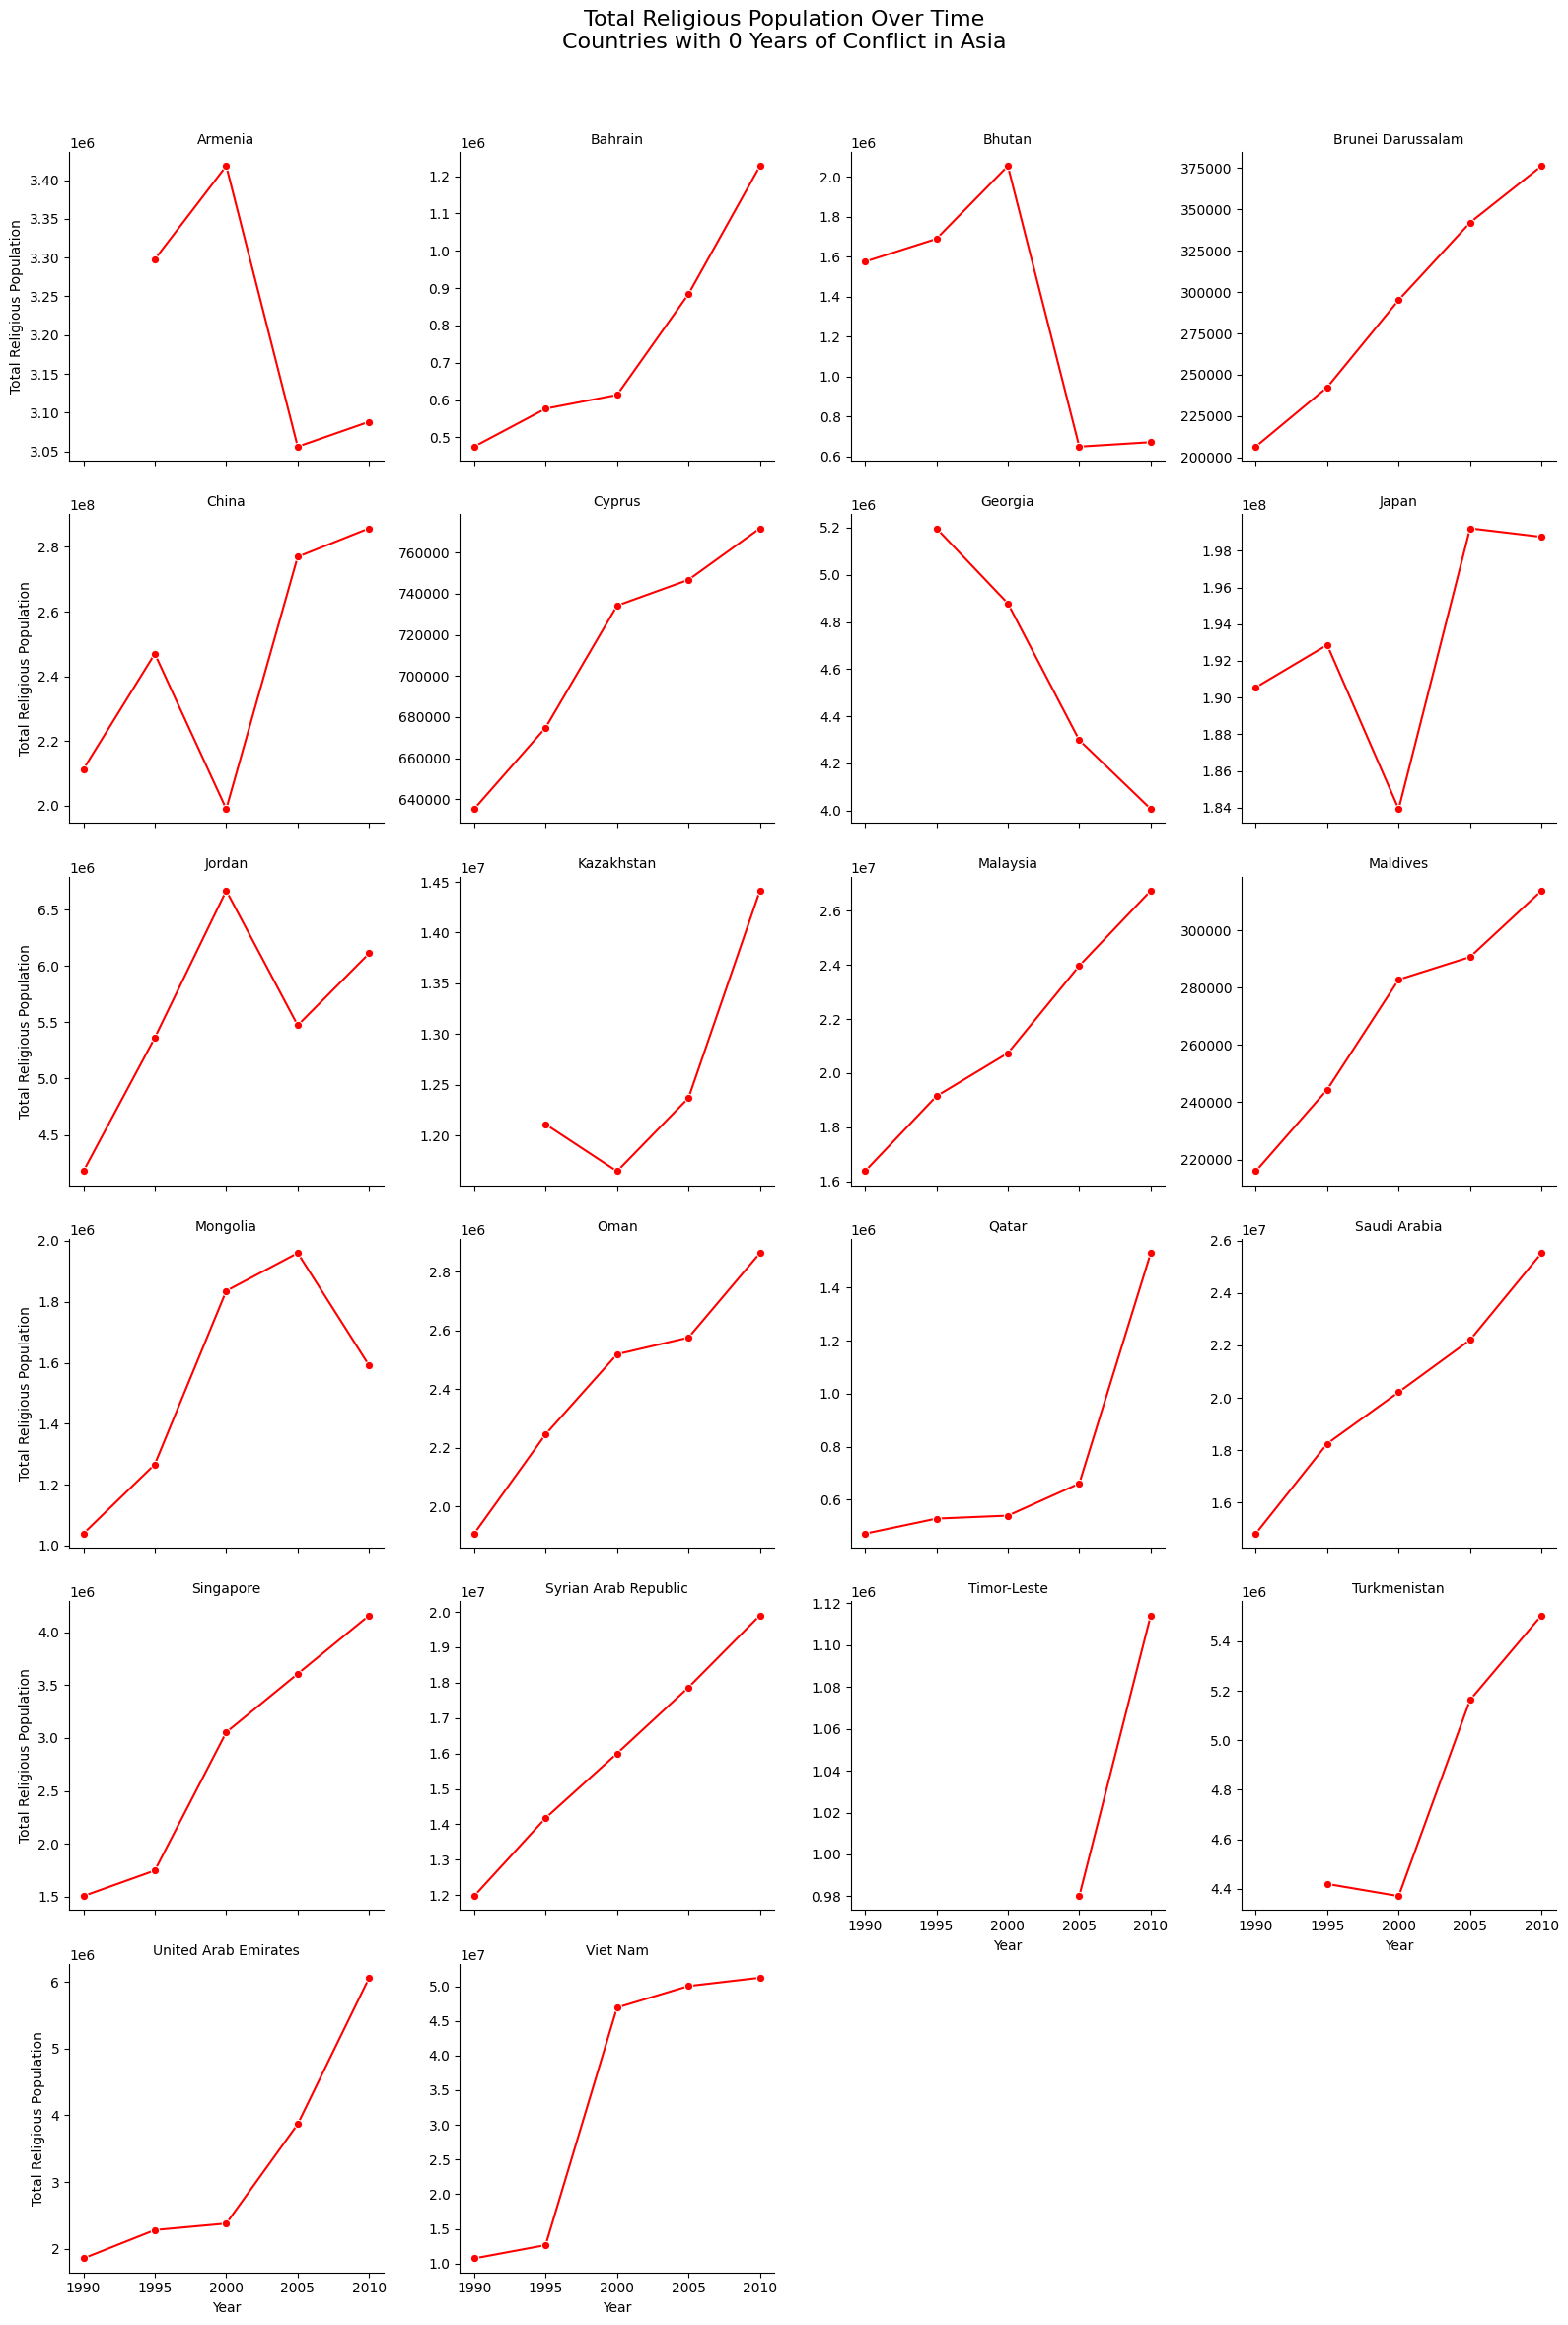

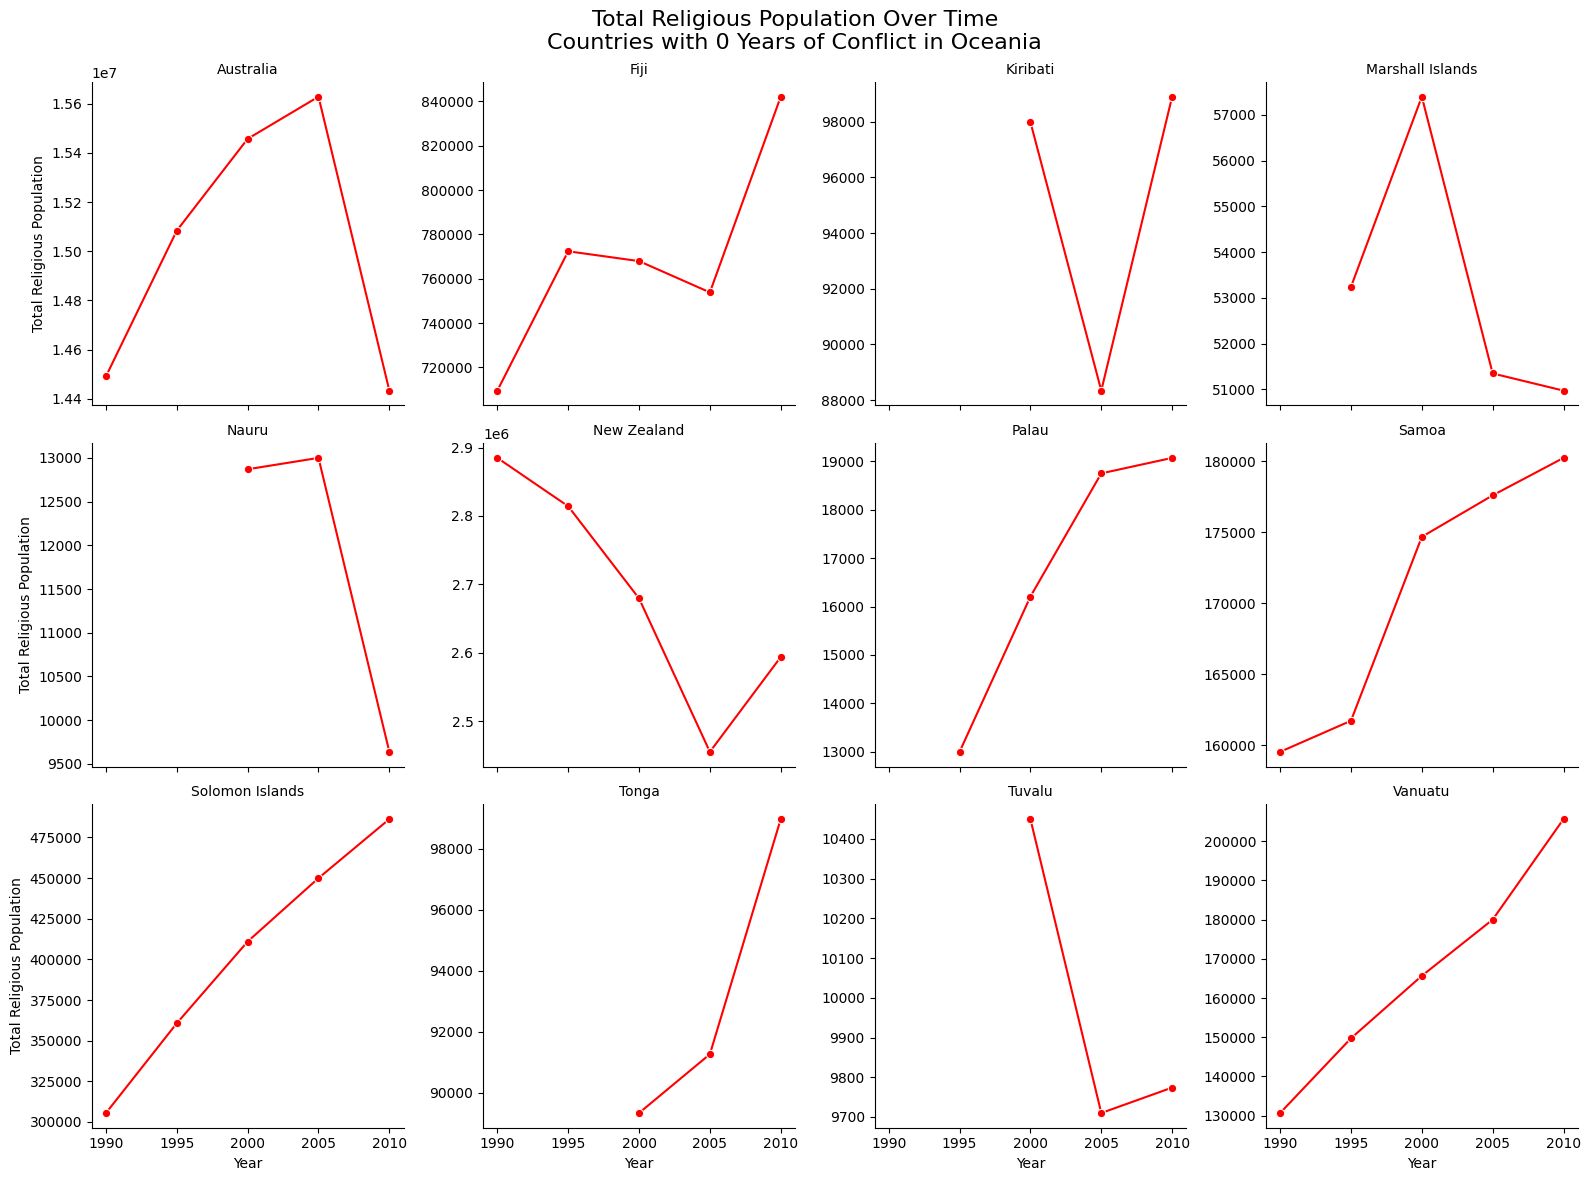

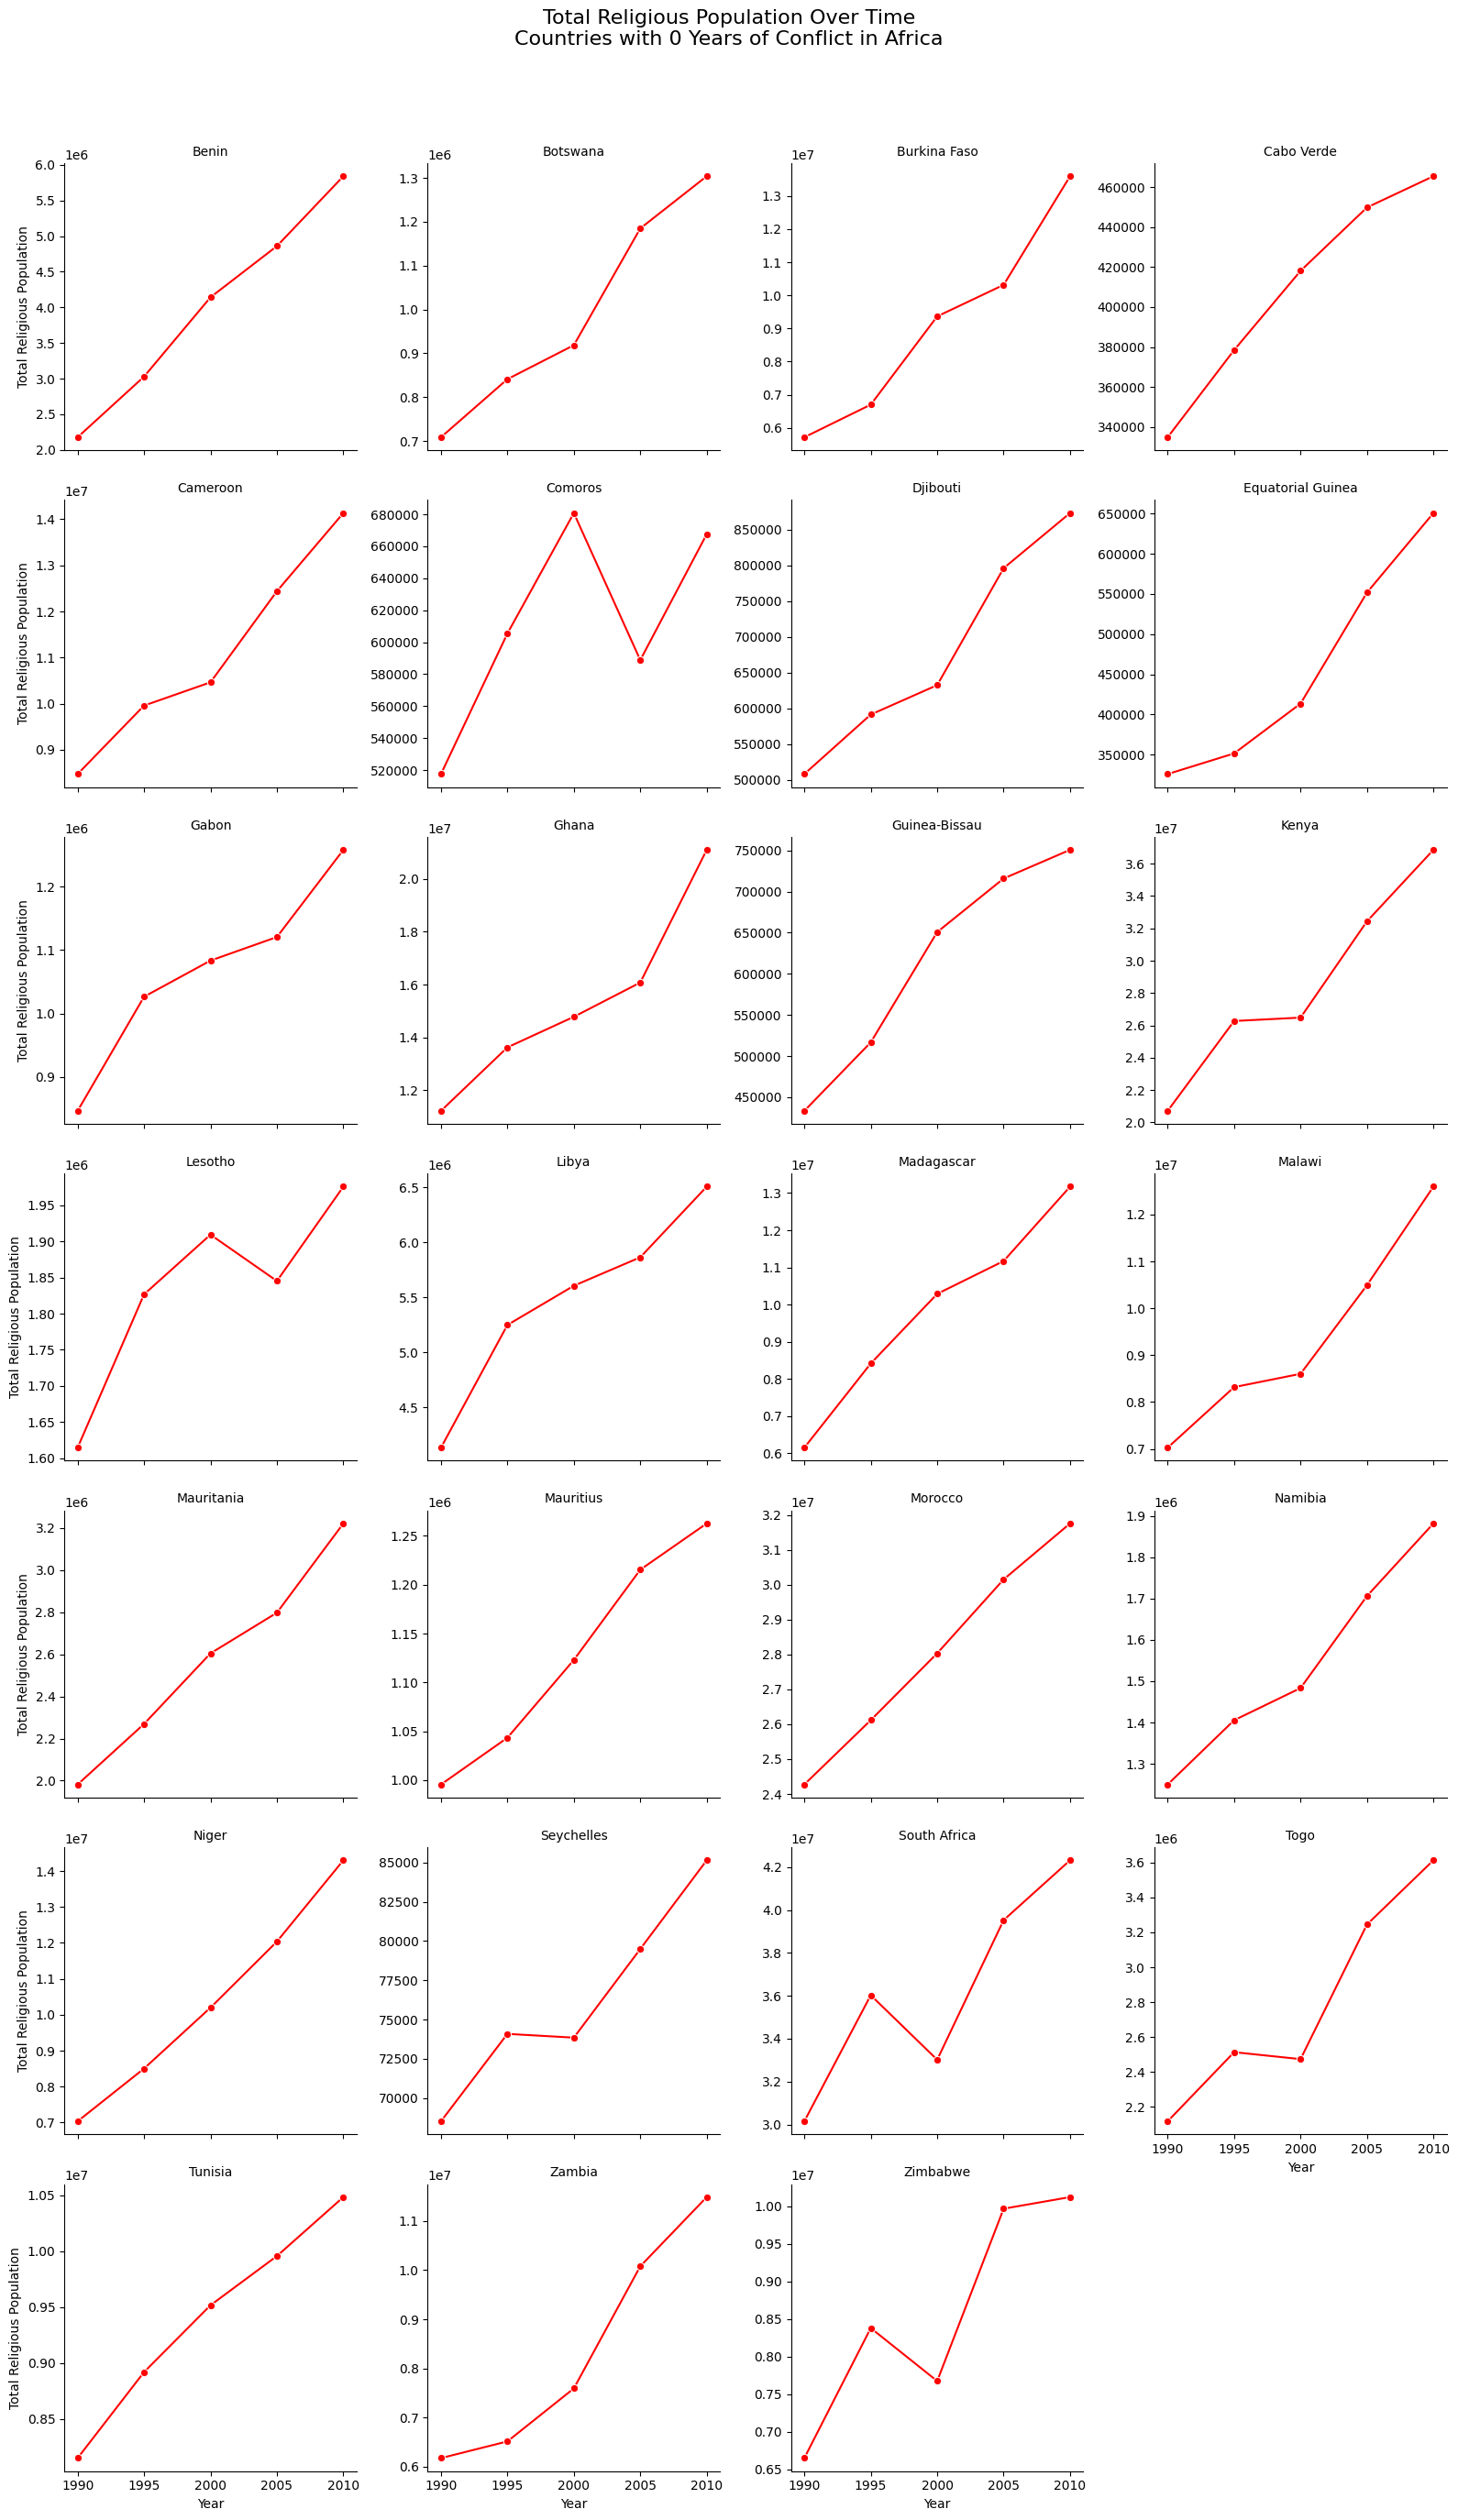

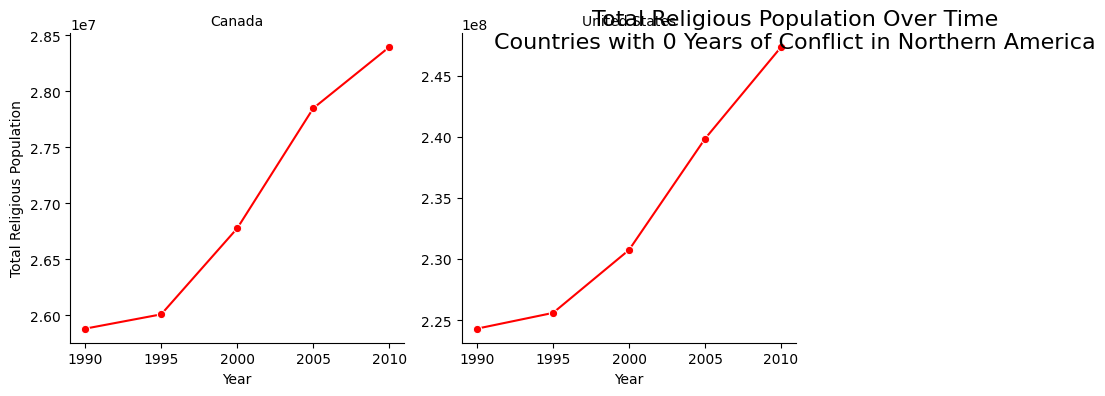

In [128]:
# Do the countries no conflict experience an decrease in religious population overall? IT DEPENDS

# Select the initial data
df_conflict_no = long_df[long_df["country"].isin(no_conflict_list)]

# Sum religious population per country, year, and region
df_conflict_sum = (
    df_conflict_no
    .groupby(["country", "year", "un_region"])["relig_pop"]
    .sum()
    .reset_index(name="total_pop")
)

# Loop over regions
for region in df_conflict_sum["un_region"].unique():
    df_region = df_conflict_sum[df_conflict_sum["un_region"] == region]
    num_countries = df_region["country"].nunique()
    
    if num_countries == 0:
        continue  # skip empty region

    cols = 4
    rows = (num_countries + cols - 1) // cols  # integer division to get number of rows

    # Create FacetGrid
    g = sns.FacetGrid(
        df_region,
        col="country",
        col_wrap=cols,
        height=4,
        sharey=False
    )
    
    # Map lineplot onto the grid
    g.map_dataframe(
        sns.lineplot,
        x="year",
        y="total_pop",
        marker="o",
        color="red"
    )
    
    # Set labels and titles
    g.set_axis_labels("Year", "Total Religious Population")
    g.set_titles(col_template="{col_name}")
    g.fig.suptitle(
        f"Total Religious Population Over Time\nCountries with 0 Years of Conflict in {region}",
        fontsize=16
    )
    
    plt.subplots_adjust(top=0.92)
    plt.savefig(f"FigA.7.2_ReligiousPopTot_country_region_{region}.png")
    plt.show()

## Interpretation
For countries that are reportedly free of armed conflict during the period, we observe both regional trends and national particularities. In Europe, there is a mix of trends, with some countries showing increases and others stagnation or slight declines, suggesting that other factors beyond conflict, such as secularization, urbanization, or historical context, may play a role. In South America, the religious population generally increases, with exceptions like Cuba and the Dominican Republic. In Asia, religious populations show a consistent upward trend, while in Oceania, trends are more variable across countries. In North America, the religious population tends to increase as well. These observations should be interpreted in light of demographic factors: differences in birth rates, overall population growth, and age structure may amplify or dampen the changes in religious population, so apparent increases may partially reflect general population growth rather than changes in religious affiliation per se. A more detailed analysis combining religious population data with demographic indicators per country is recommended to fully disentangle these effects.
### Add
In conclusion, while countries experiencing conflict tend to show increases in their religious populations, stability or decline in non-conflict countries is not uniform. Regional trends are still observable: Asia and the Americas remain predominantly religious, whereas Europe shows a more mixed pattern. These observations raise questions about the role of demographic factors, such as population growth and birth rates, as well as the hidden inclusion of countries involved in conflicts abroad (e.g., the United States, which is not officially in conflict on its territory despite international military involvement).”

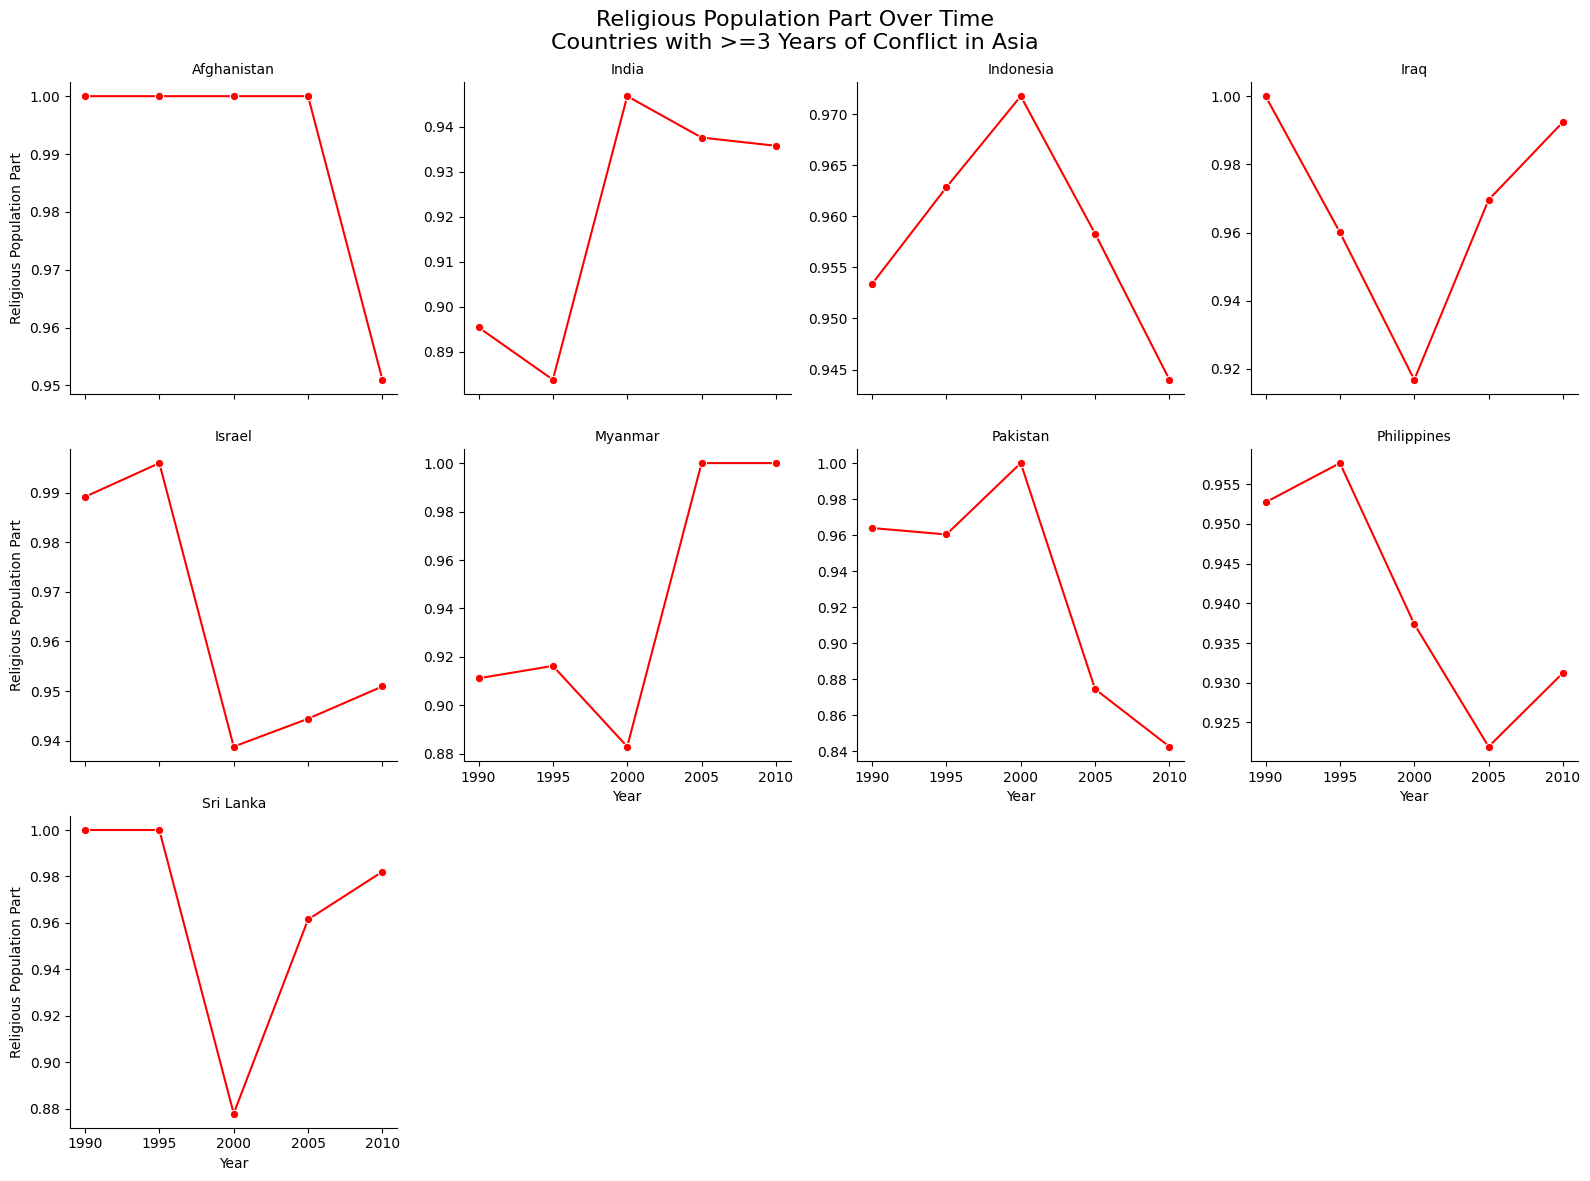

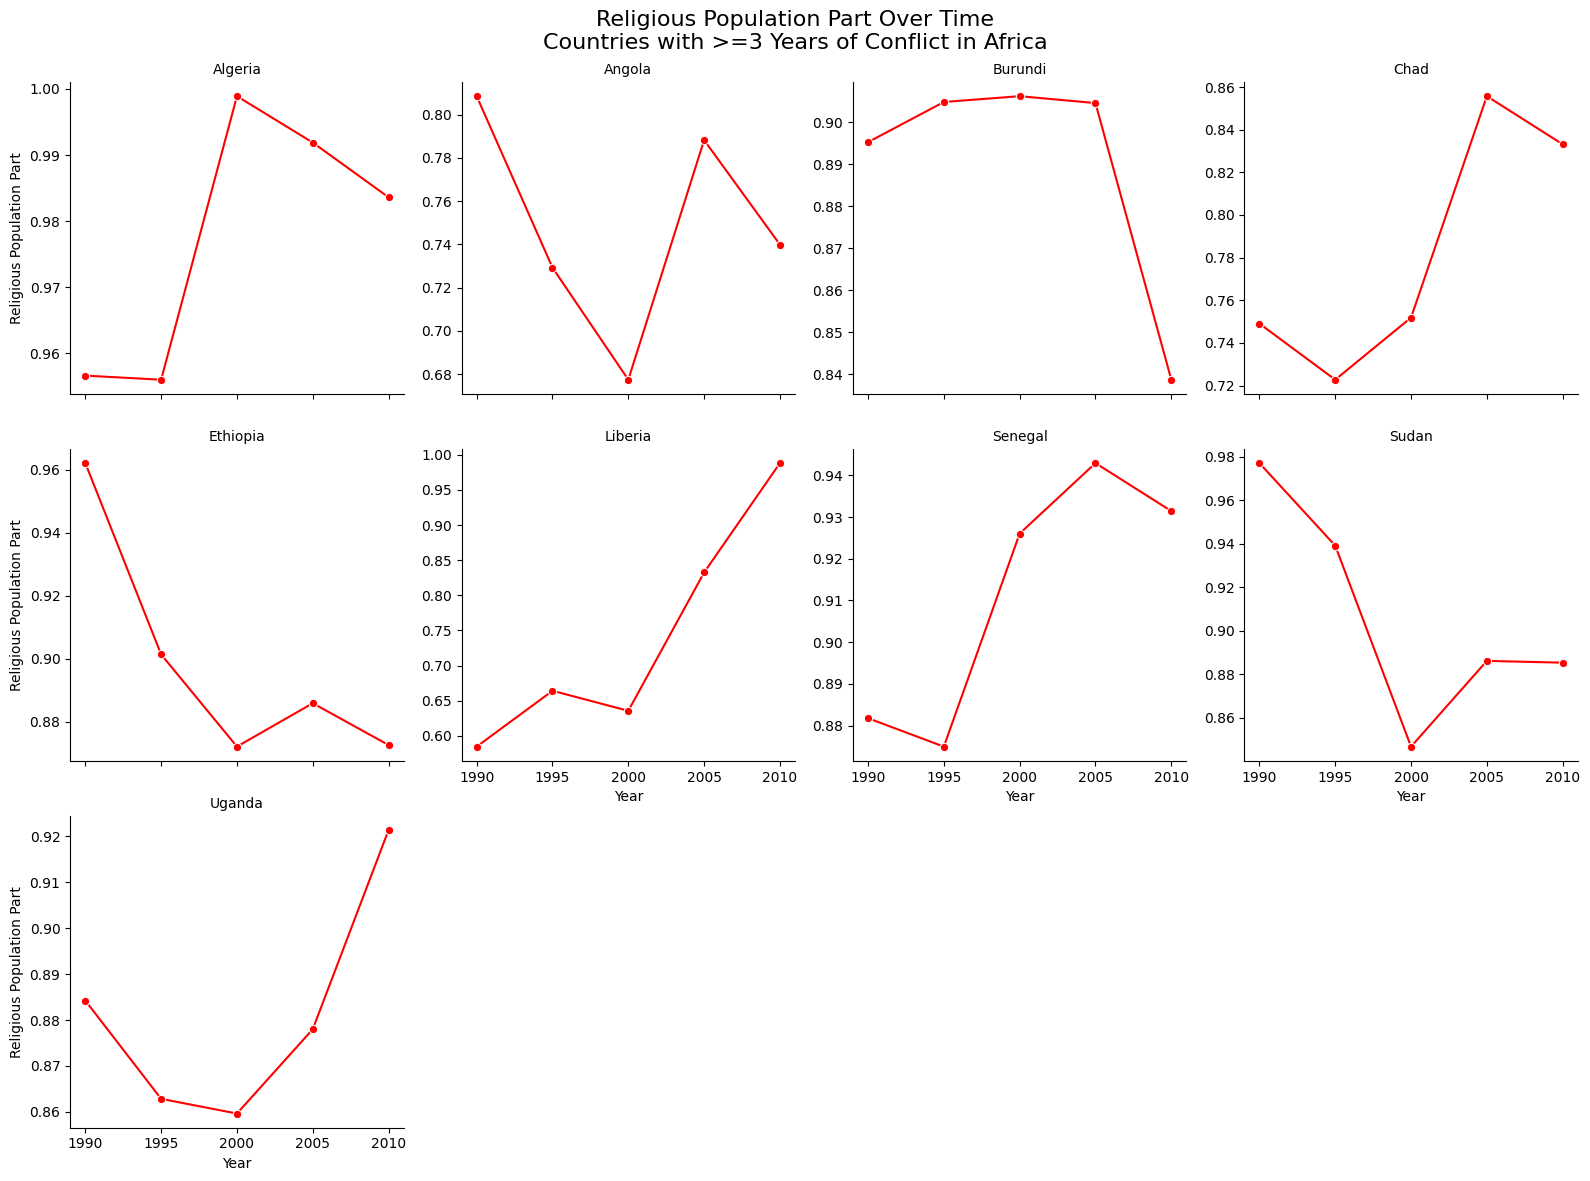

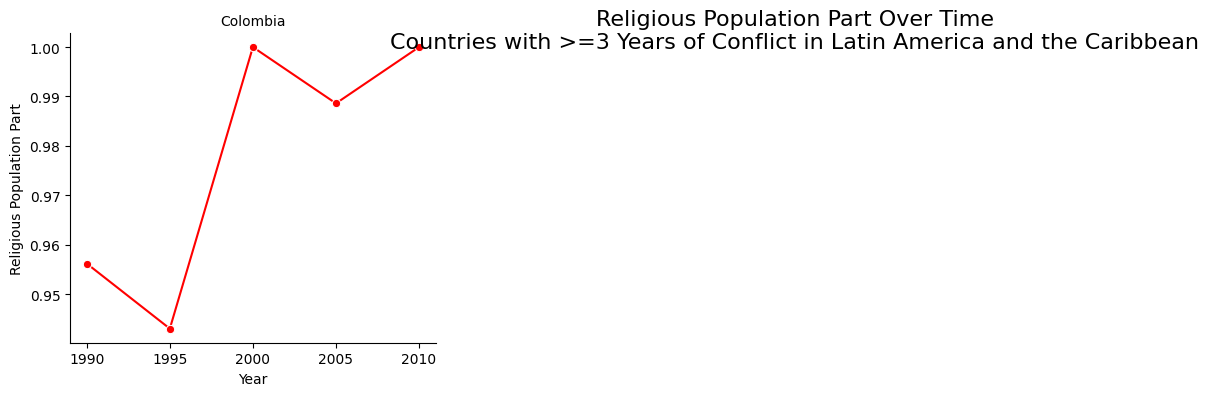

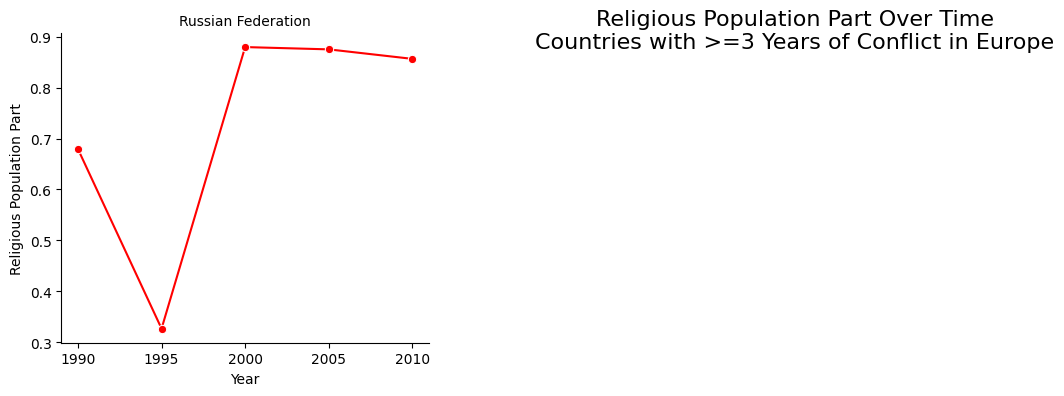

In [129]:
# Do the countries in conflict experience an increase of religious population part overall?  NO

# Select the initial data
df_conflict_yes = pop_percent[pop_percent["country"].isin(country_conflict_list)]

# Sum religious population per country, year, and region
df_conflict_sum = (
    df_conflict_yes
    .groupby(["country", "year", "un_region"])["percent_pop"]
    .sum()
    .reset_index(name="percent_pop")
)

# Loop over regions
for region in df_conflict_sum["un_region"].unique():
    df_region = df_conflict_sum[df_conflict_sum["un_region"] == region]
    num_countries = df_region["country"].nunique()
    
    if num_countries == 0:
        continue  # skip empty region

    cols = 4
    rows = (num_countries + cols - 1) // cols  # integer division to get number of rows

    # Create FacetGrid
    g = sns.FacetGrid(
        df_region,
        col="country",
        col_wrap=cols,
        height=4,
        sharey=False
    )
    
    # Map lineplot onto the grid
    g.map_dataframe(
        sns.lineplot,
        x="year",
        y="percent_pop",
        marker="o",
        color="red"
    )
    
    # Set labels and titles
    g.set_axis_labels("Year", "Religious Population Part")
    g.set_titles(col_template="{col_name}")
    g.fig.suptitle(
        f"Religious Population Part Over Time\nCountries with >=3 Years of Conflict in {region}",
        fontsize=16
    )
    
    plt.subplots_adjust(top=0.92)
    plt.savefig(f"FigA.7.3_ReligiousPopPart_country_region_{region}.png")
    plt.show()

In [130]:
pop_percent.describe()
df_conflict_sum.describe()


,year,percent_pop
count,100.000000,100.000000
mean,2000.000000,0.900679
std,7.106691,0.106215
min,1990.000000,0.326554
25%,1995.000000,0.874834
50%,2000.000000,0.931334
75%,2005.000000,0.963112
max,2010.000000,1.000000


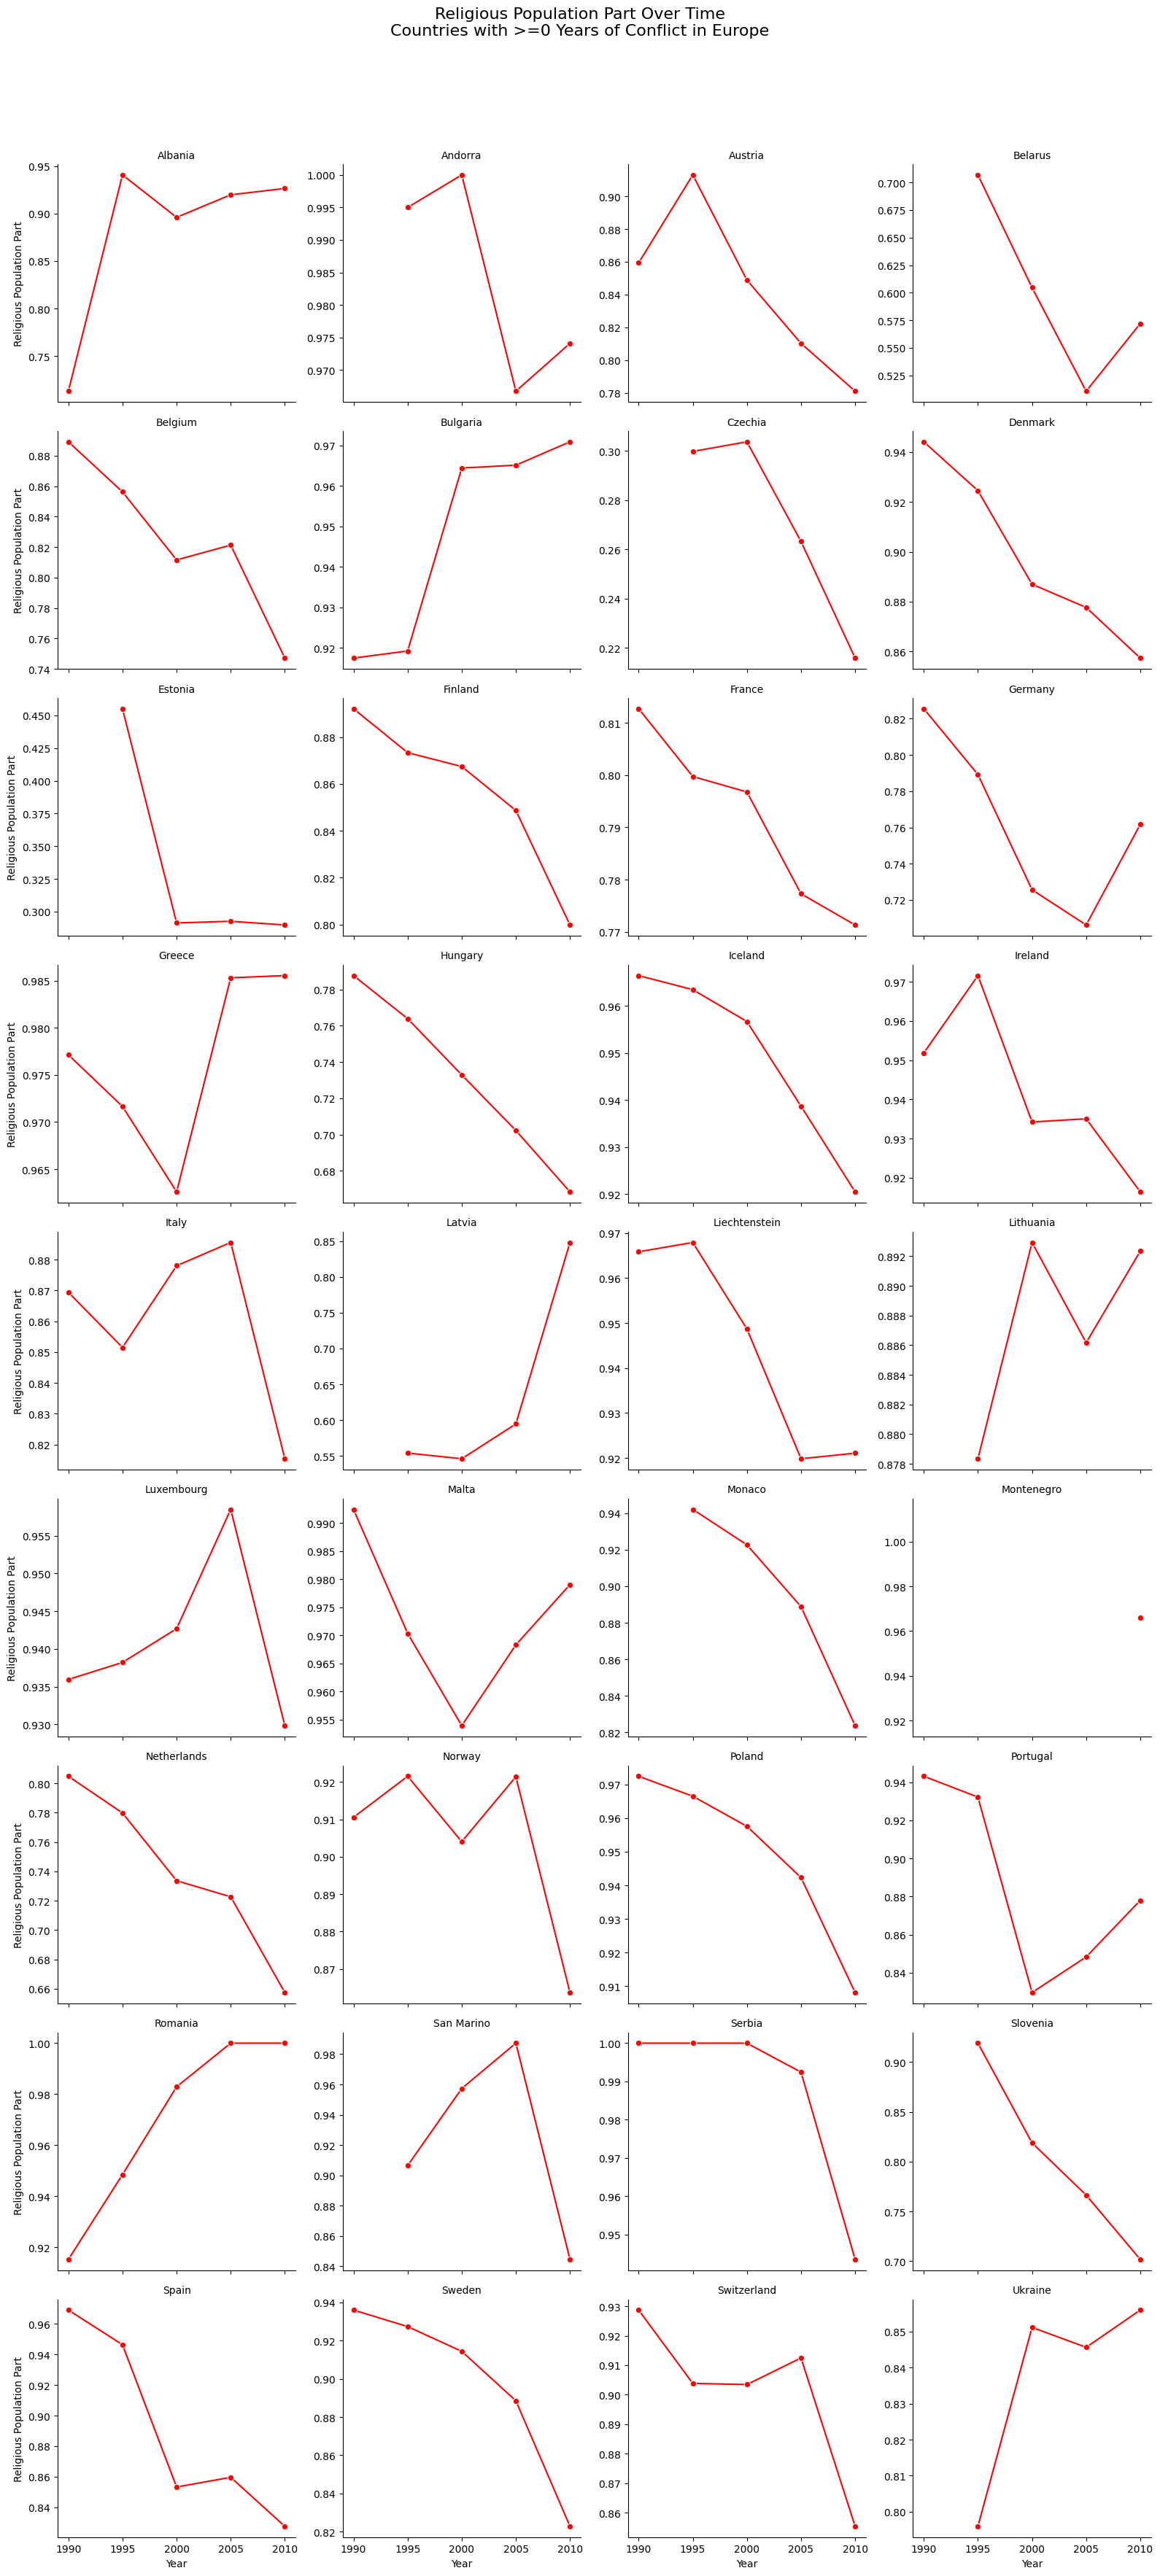

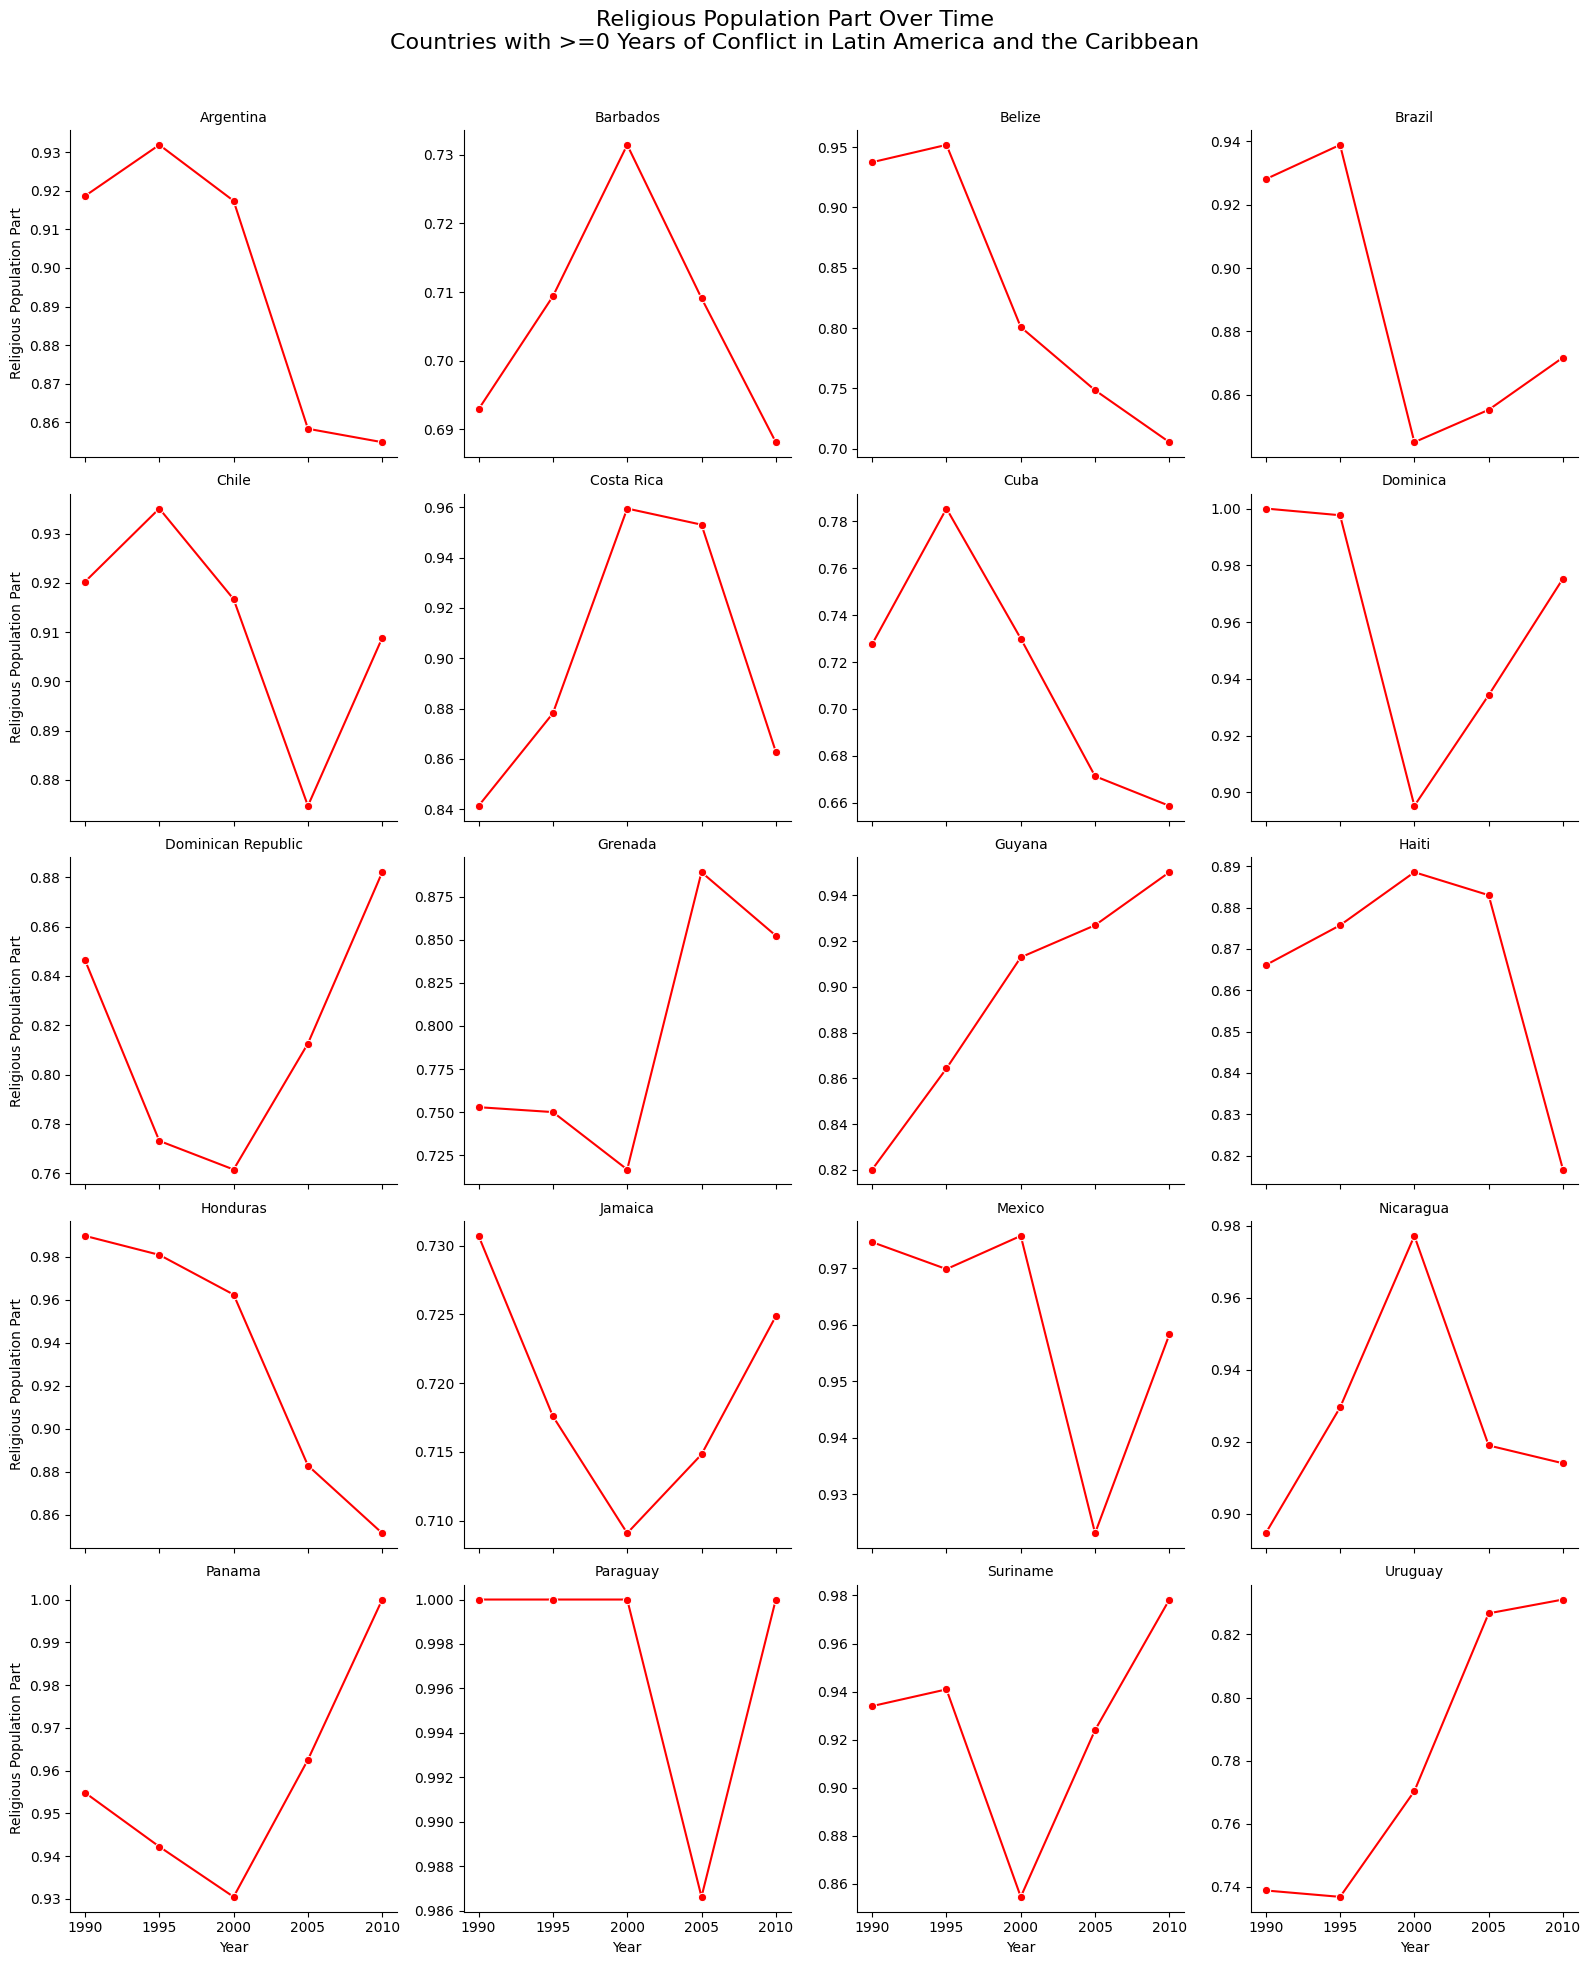

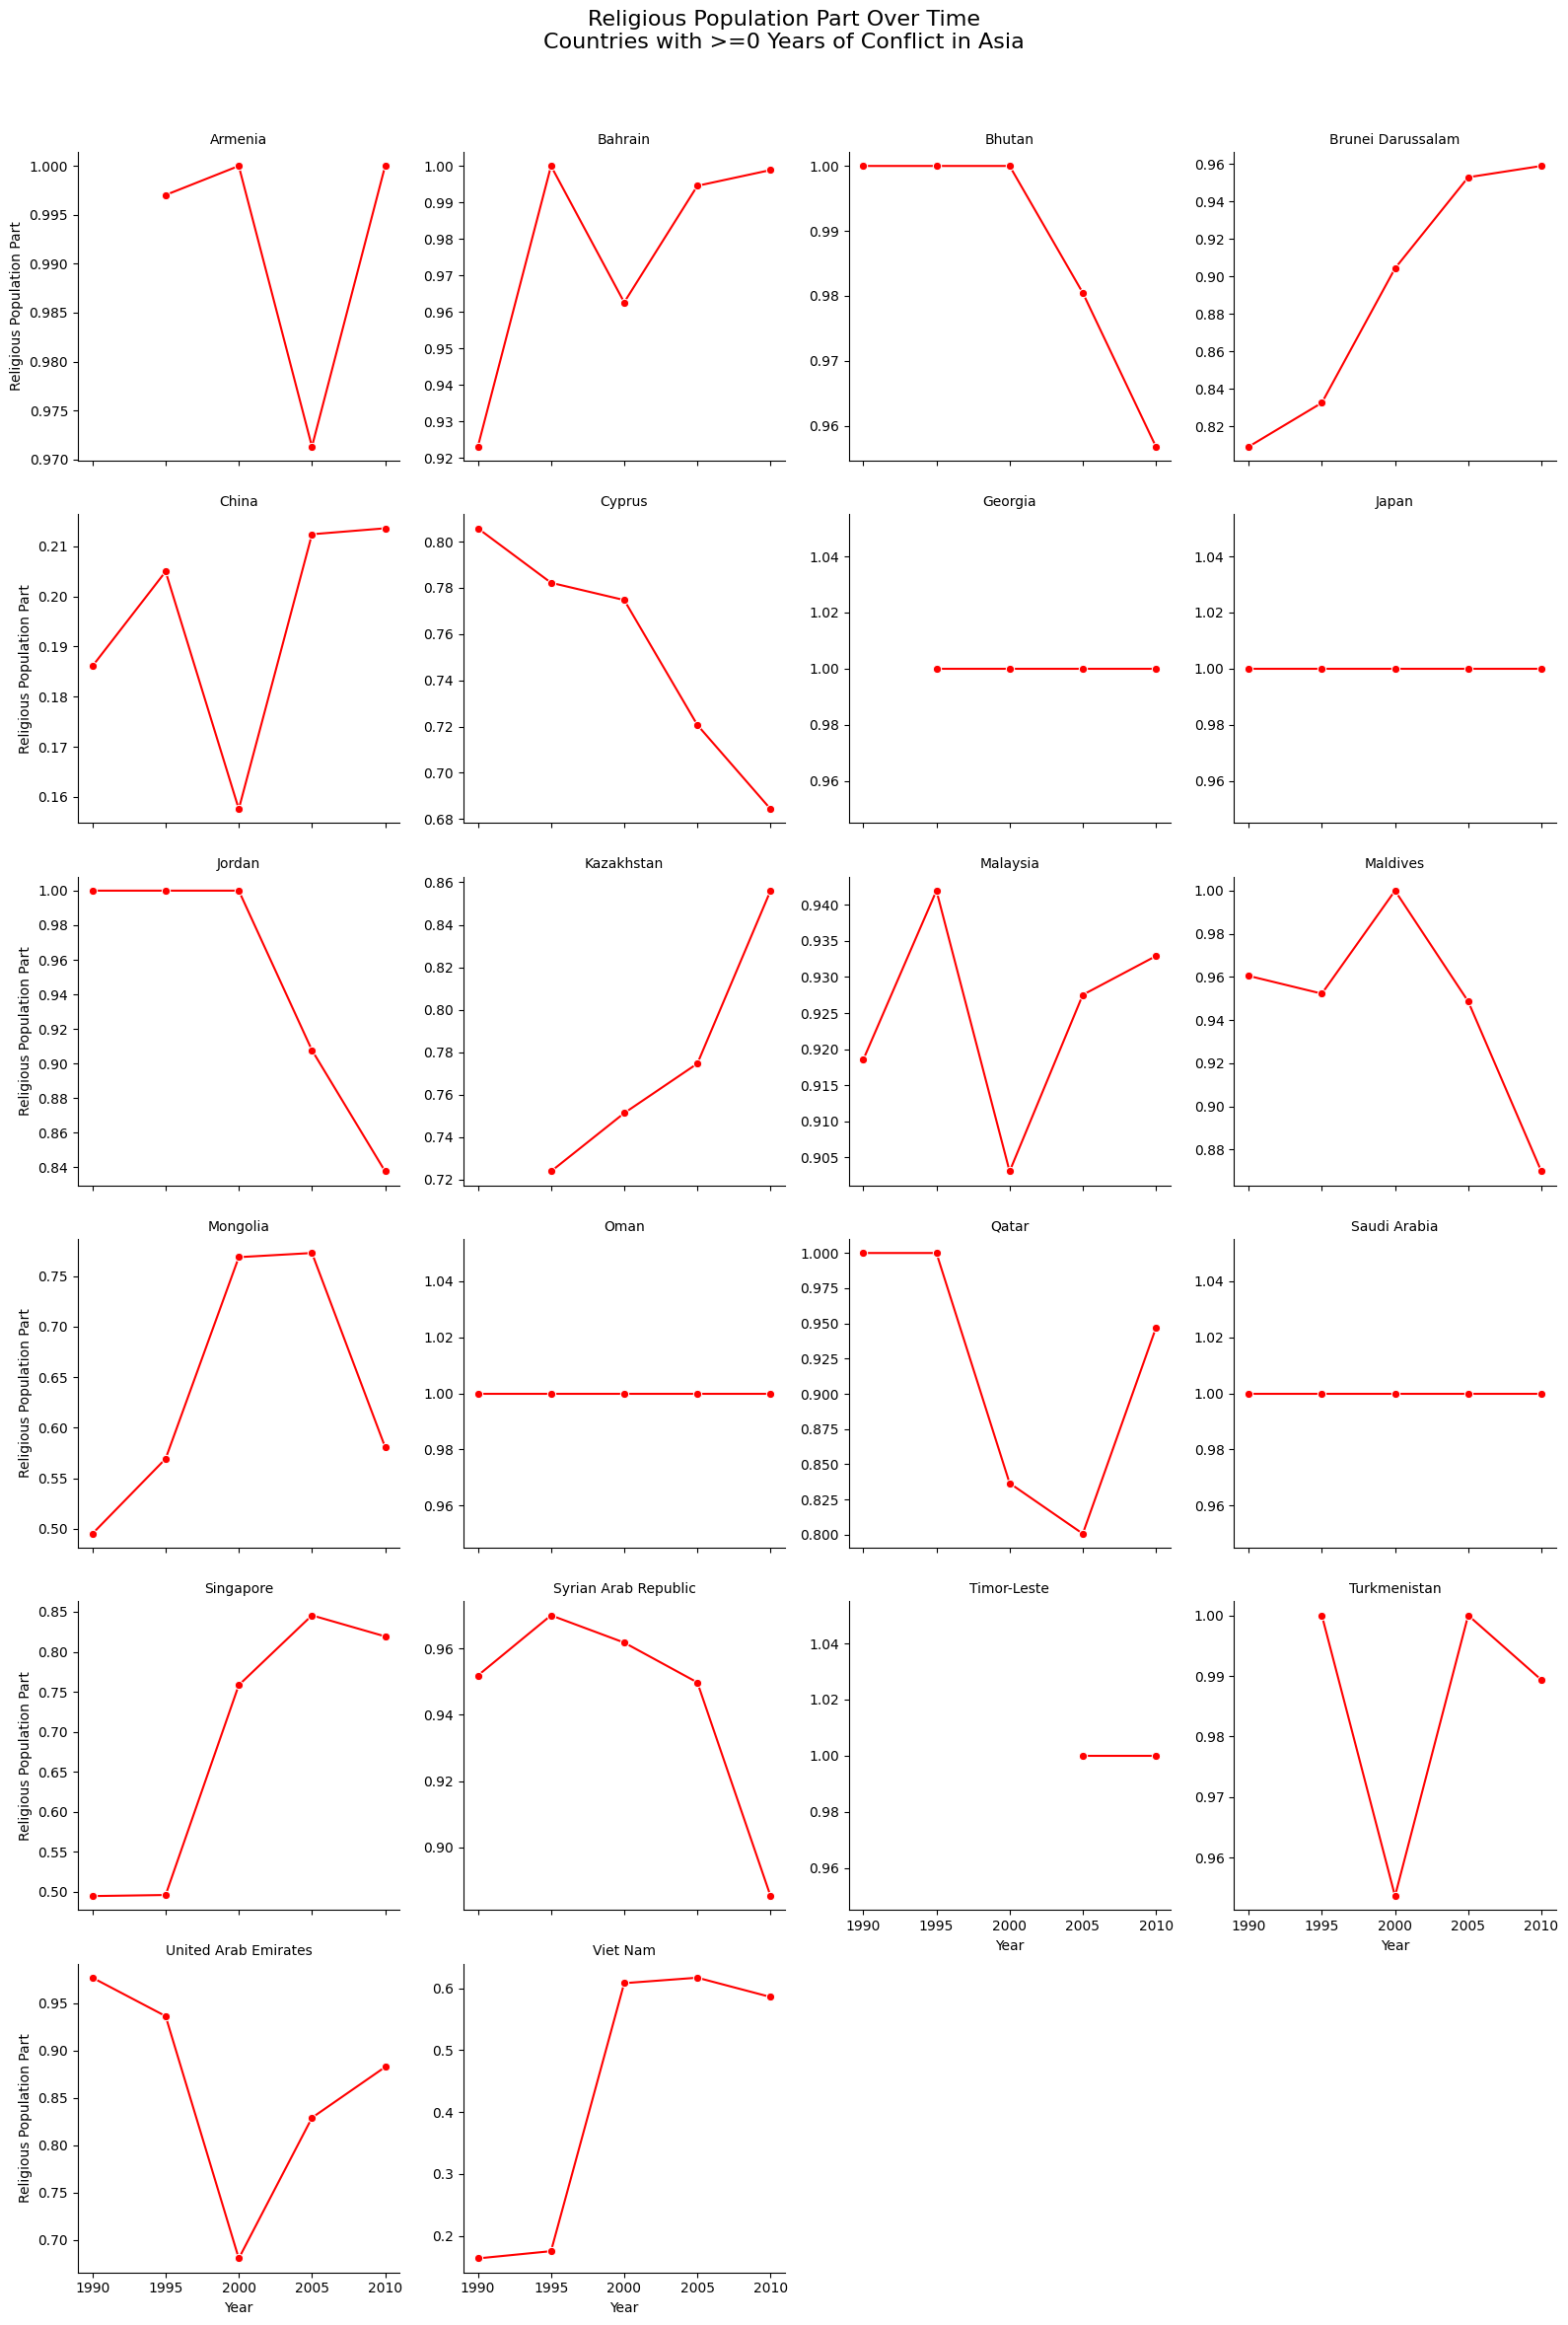

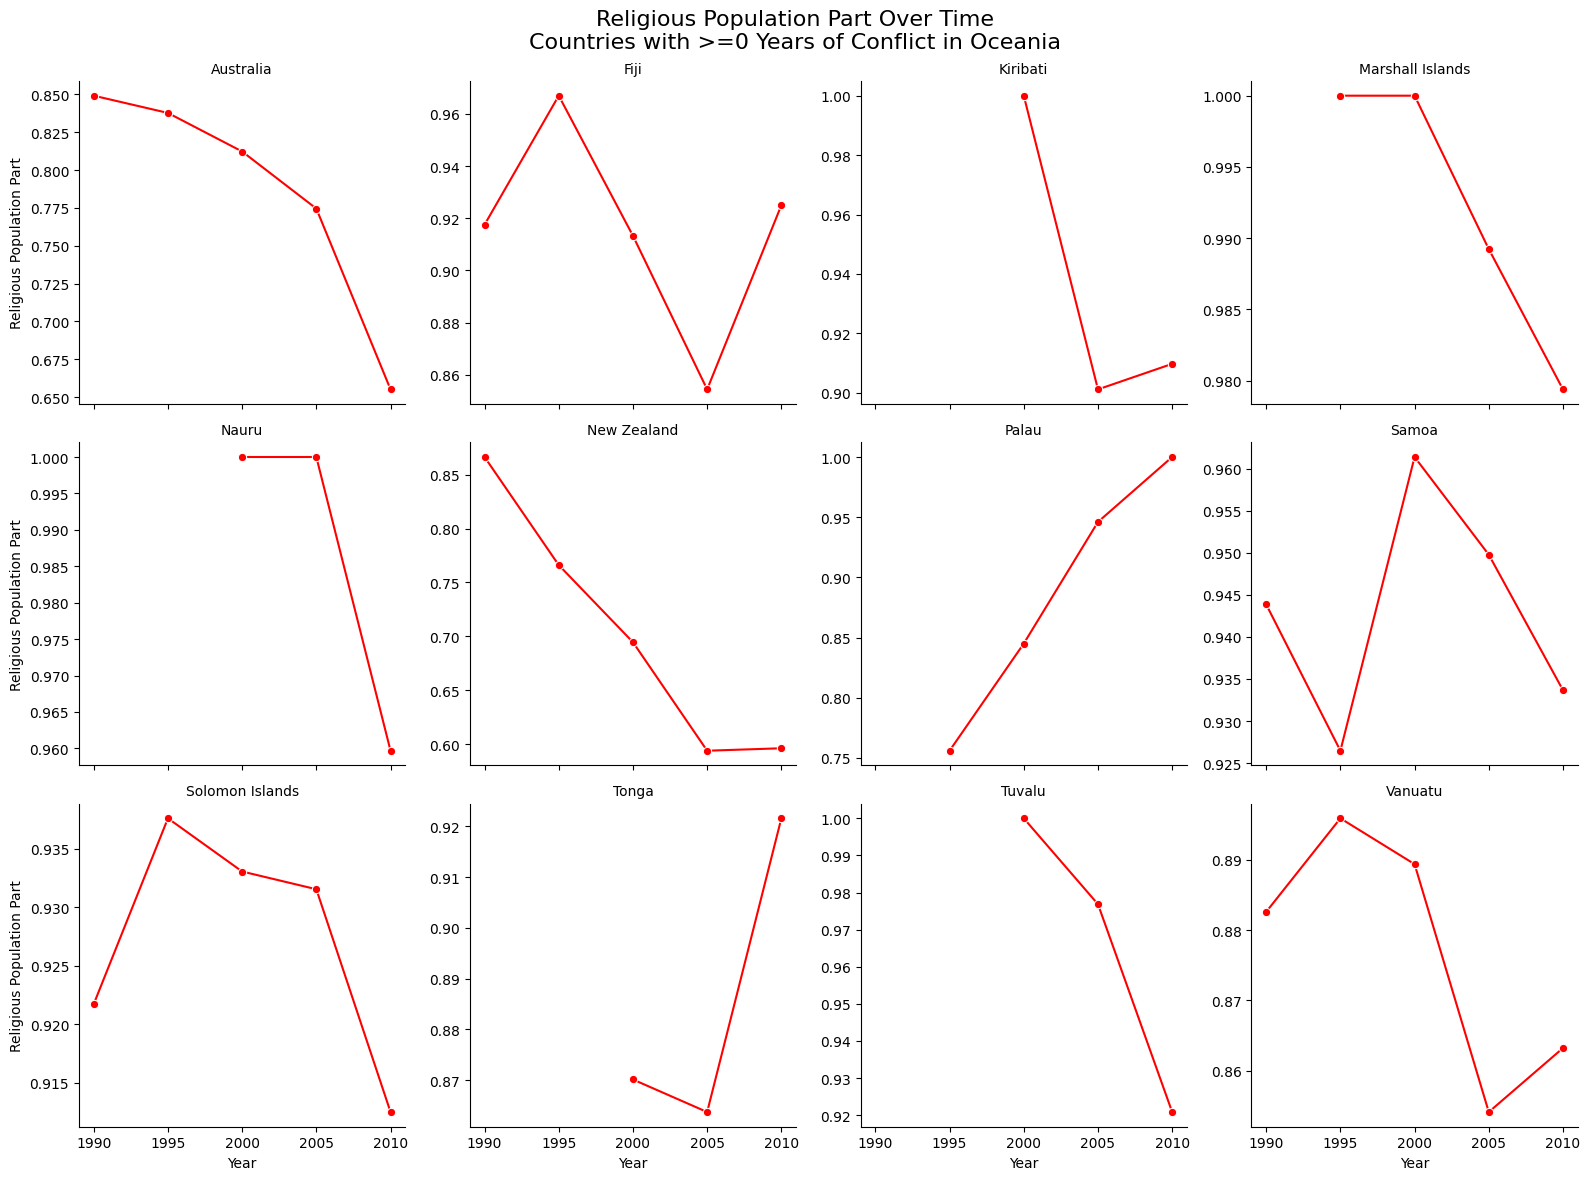

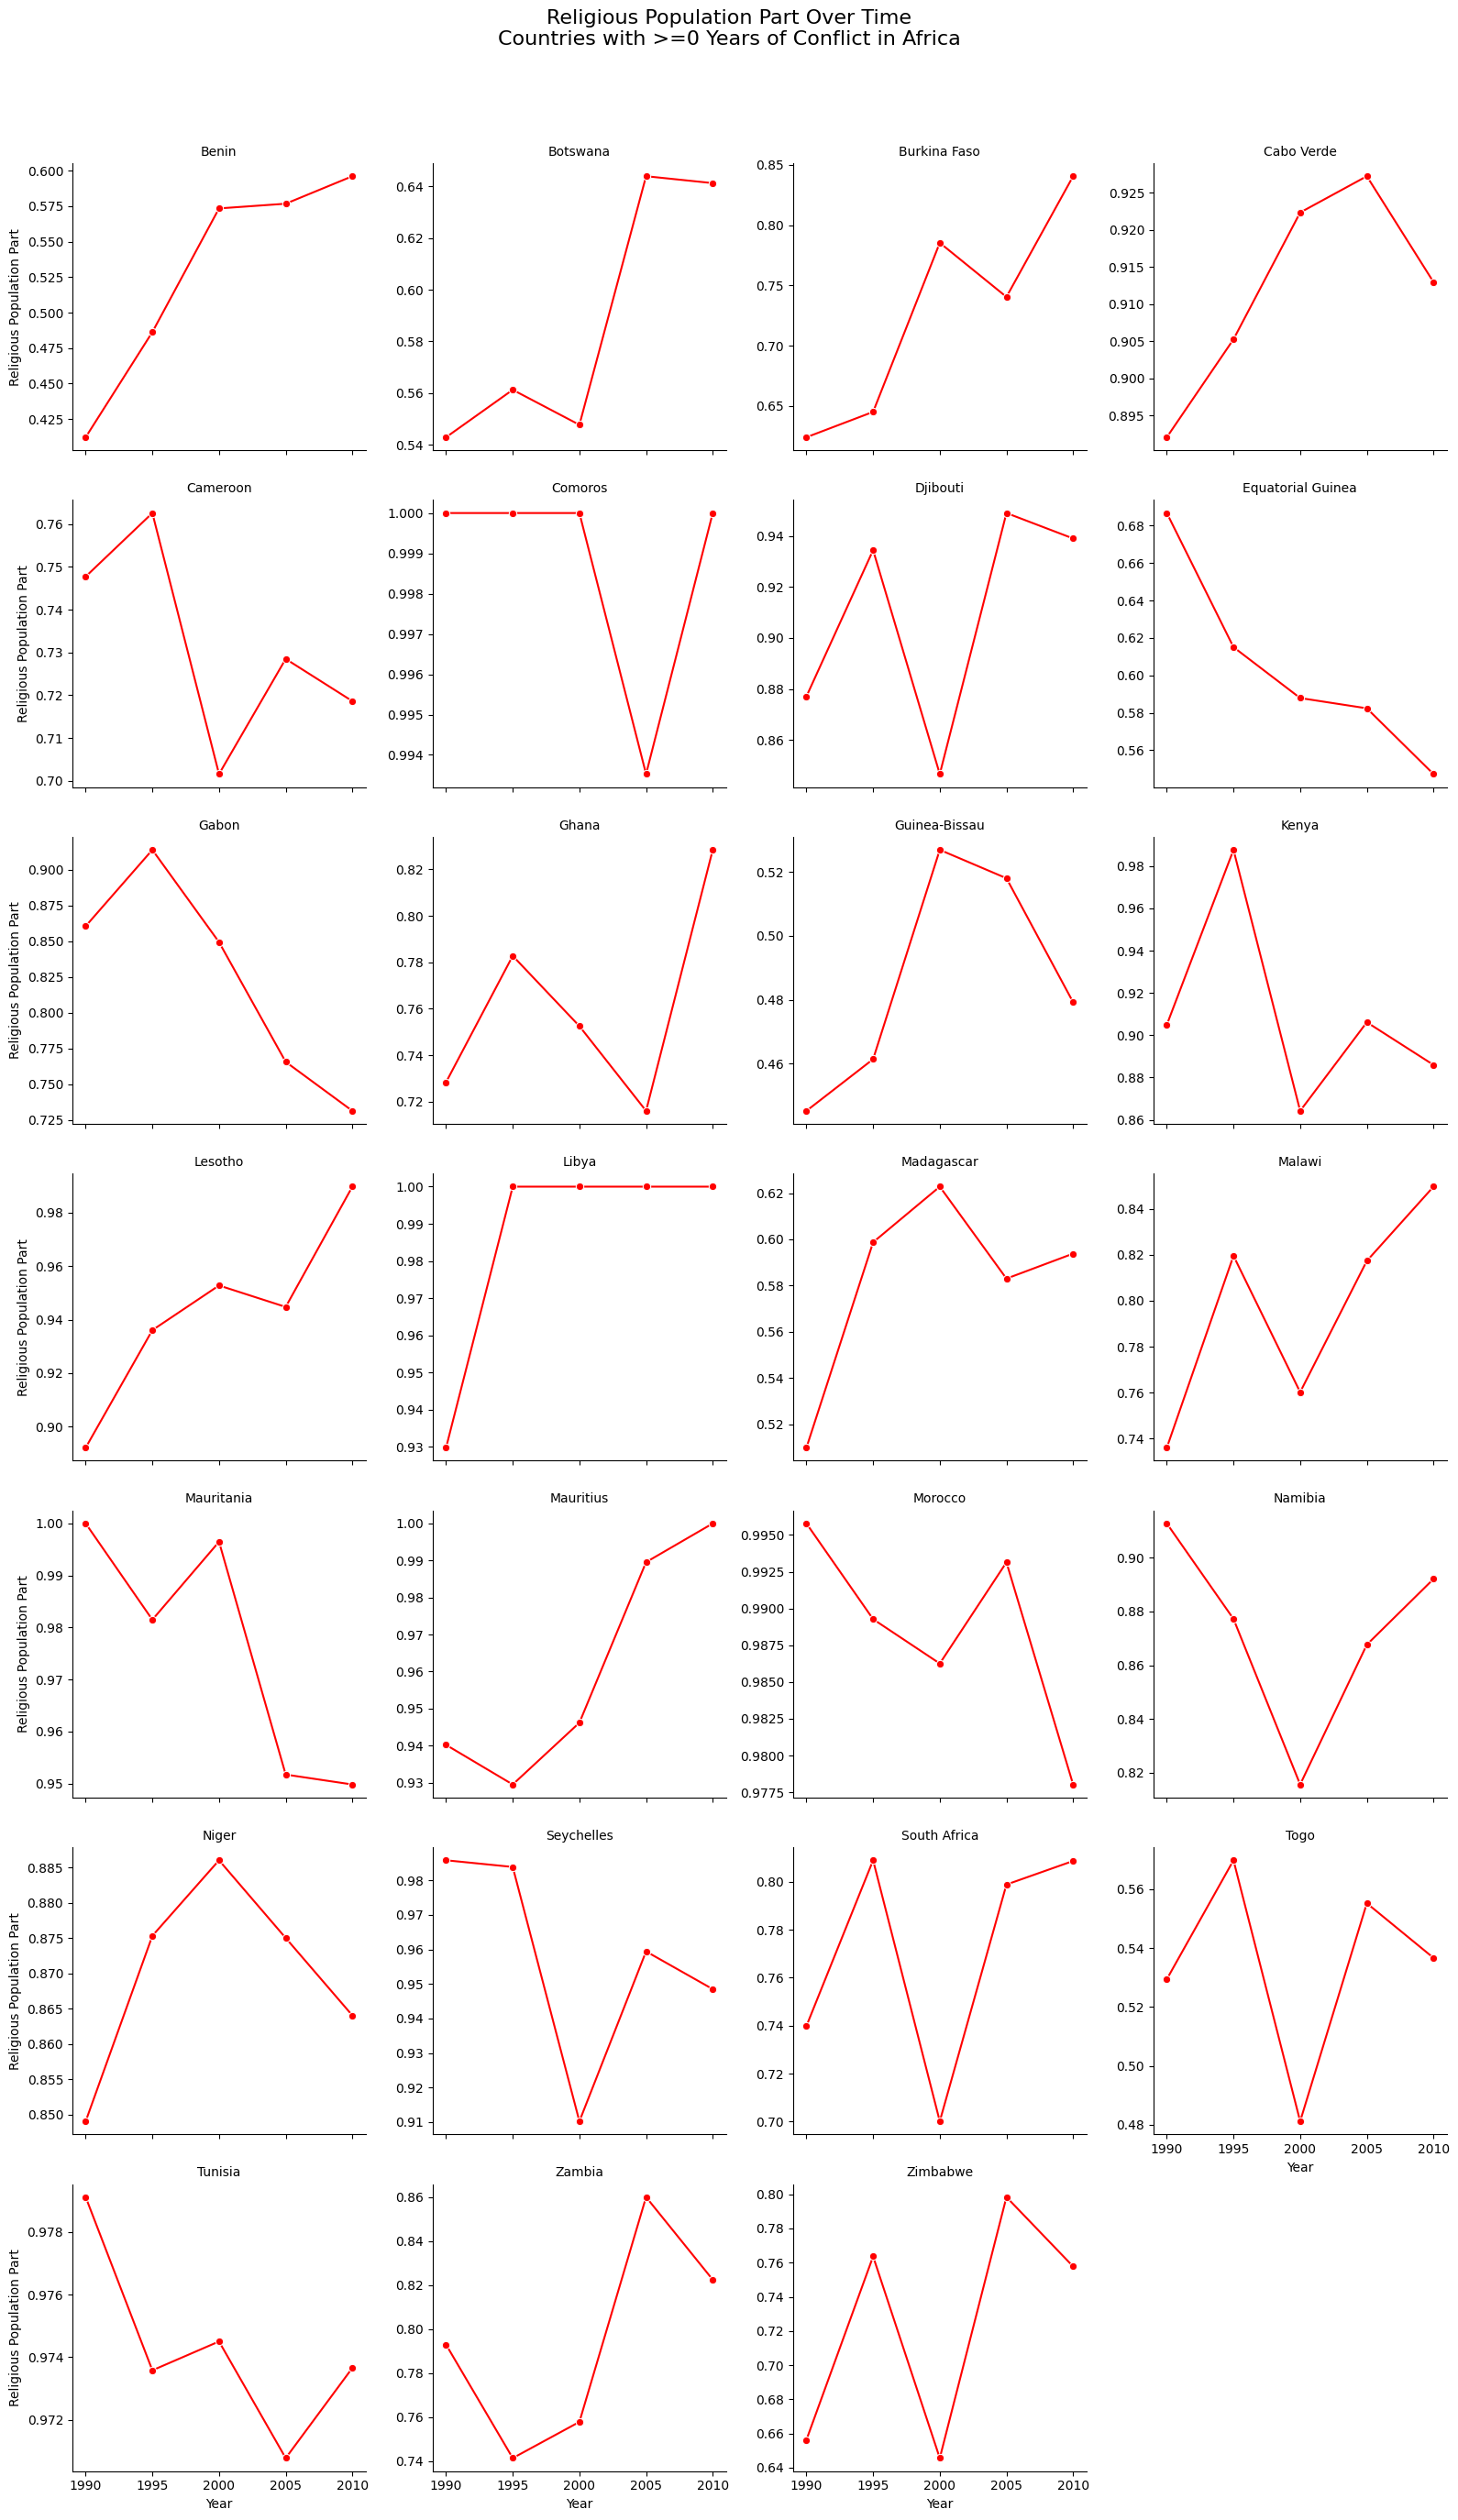

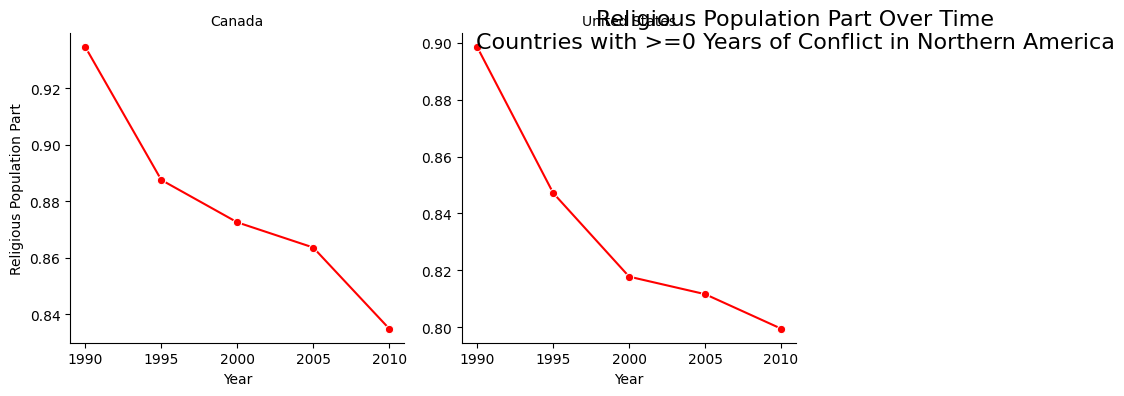

In [131]:
# Do the countries without conflict experience an increase of religious population part overall?  

# Select the initial data
df_conflict_no = pop_percent[pop_percent["country"].isin(no_conflict_list)]

# Sum religious population per country, year, and region
df_conflict_sum = (
    df_conflict_no
    .groupby(["country", "year", "un_region"])["percent_pop"]
    .sum()
    .reset_index(name="percent_pop")
)

# Loop over regions
for region in df_conflict_sum["un_region"].unique():
    df_region = df_conflict_sum[df_conflict_sum["un_region"] == region]
    num_countries = df_region["country"].nunique()
    
    if num_countries == 0:
        continue  # skip empty region

    cols = 4
    rows = (num_countries + cols - 1) // cols  # integer division to get number of rows

    # Create FacetGrid
    g = sns.FacetGrid(
        df_region,
        col="country",
        col_wrap=cols,
        height=4,
        sharey=False
    )
    
    # Map lineplot onto the grid
    g.map_dataframe(
        sns.lineplot,
        x="year",
        y="percent_pop",
        marker="o",
        color="red"
    )
    
    # Set labels and titles
    g.set_axis_labels("Year", "Religious Population Part")
    g.set_titles(col_template="{col_name}")
    g.fig.suptitle(
        f"Religious Population Part Over Time\nCountries with >=0 Years of Conflict in {region}",
        fontsize=16
    )
    
    plt.subplots_adjust(top=0.92)
    plt.savefig(f"FigA.7.4_ReligiousPopPart_country_region_{region}.png")
    plt.show()

In [102]:
df_conflict_sum.describe()

,year,percent_pop
count,564.000000,564.000000
mean,2000.434397,0.845662
std,6.959483,0.161244
min,1990.000000,0.157589
25%,1995.000000,0.780661
50%,2000.000000,0.892132
75%,2005.000000,0.958615
max,2010.000000,1.000000


## Question: Do conflicts increase or decrease religiosity?
### H1: Exposure to conflict raises religiosity as a coping mechanism but may decrease it in highly secularized societies. 

1. The number of religious people remains stable and low for all the regions, except for Africa which experienced a light increase, and Asia which is much over the other regions (Figure1 graph A).  Western regions are mainly christian, while Asia is more diverse and Africa shared between Christianism and Islam (Figure1 graph B).

2. However, when we observe the average percentage per region (Figure1 graph C) , we can conclude part of religion is decreasing in Europe and Northern America, while remains high and stable for Latin America, Oceania and Asia. Suprisingly, Africa religious part is the lowest and increases, that might be explained by selecting most important religions (in termes of numbers)

3. Victoria: But there is an increase of religion in countries whith conflict.... difference of religion evolution over time according to conflict presence. Other findings and graphs

4. Zooming at a country level for each region, the part of religious population variates only of +/- 10 %  (std) for most countries experiencing 3 years in conflict or more. For highest deltas, the european outlier is Russia with a proportion from 70% in 1990 to nearly 30% in 1995, and peak of 88% in 2000, that might underlines the fall of the soviectic union and economical instability following this transition, while in Africa Liberia jumped from 60% to almost 100%. During this period the country experienced 2 civil wars leading more than 250 000 deaths (Figure2 graph A). 
this is really versatile due to the definition of conflict ("only 25 deaths")
On the other hand, for coutnries without any reported conflict for the time period reveal more diversity (descriptive statistiques) with lower percentages etd higher dispersion. Most of the countries in Eruope see their religious population part decreasing (14%). Otherwie, variations stay in a short range of high percentage for most of the countries independantly of the reions. Only some countries show higher variations in religious part of the population, which suggest the need of an analysis at a contry level more than regional either global.
Difficult to access to the methodology of this dataset, so it should taken with caution.

5. Religious patterns are generally coherent and meaningful, even in countries affected by conflict. In most cases, one or two religions dominate nearly the entire population, while other faiths remain minor. Islam and Christianity are the predominant religions worldwide, with exceptions in parts of Asia where Hinduism, Buddhism, or Confucianism prevail. Dominant religions tend to evolve symmetrically, so their relative proportions remain largely stable despite overall population growth. In many countries without conflict, these proportions remain stable over time. Countries exhibiting large variations—such as Albania, Serbia, and North Macedonia in Europe; Guyana and Suriname in South America; and North Korea, South Korea, and Vietnam in Asia_warrant focused analysis. At this stage, there also appear to be geographical patterns that deserve closer study, which could be explored through the development of a typology of countries based on these symmetries and variations to deepen the analysis  (Figure2 graph B). 

6. Victoria: Test demonstrates a relative dependancy between conflict presence and religious share... opening on additionalf actors to explore > GDP 
